In [7]:
import os
import itertools
import torch
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_style('darkgrid')
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve, auc
from sklearn.metrics import classification_report, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
from itertools import cycle
import cv2
import torch.nn as nn
import torch.optim as optim
from PIL import Image
import torch.nn.functional as F          # for the model
import torchvision.transforms.functional as TF   # for augmentation
from pathlib import Path
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
import torchvision.transforms as transforms
from torchvision import models
from torchvision.datasets import ImageFolder
# ignore the warnings
import warnings
warnings.filterwarnings('ignore')

# Dataset Loading

In [8]:
data_dir = "D:\Black Gram Leaf\Resized"

In [9]:
class CustomImageDataset(Dataset):
    def __init__(self, filepaths, labels, transform=None):
        self.filepaths = filepaths
        self.labels = labels
        self.transform = transform
    
    def __len__(self):
        return len(self.filepaths)
    
    def __getitem__(self, idx):
        image = cv2.imread(self.filepaths[idx])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        label = self.labels[idx]
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

# --------------------------------------------------
# 🔹 LOAD DATA
# --------------------------------------------------
def loading_the_data(data_dir):
    filepaths = []
    labels = []

    folds = os.listdir(data_dir)

    for fold in folds:
        foldpath = os.path.join(data_dir, fold)
        filelist = os.listdir(foldpath)
        for file in filelist:
            fpath = os.path.join(foldpath, file)
            filepaths.append(fpath)
            labels.append(fold)

    return pd.DataFrame({"filepaths": filepaths, "labels": labels})

df = loading_the_data(data_dir)

             Class  Number of Images
0  Cercospora Spot               598
1          Healthy               545
2           Insect               408
3     Leaf Crinkle               806
4    Yellow Mosaic              1681


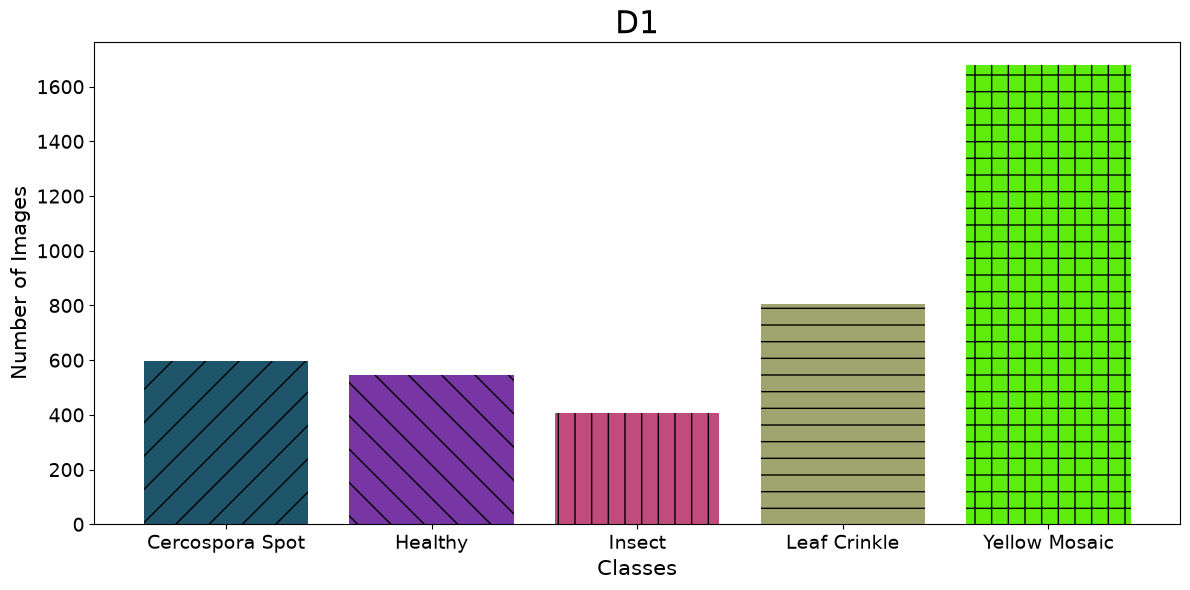

In [10]:

import random
plt.style.use('default')

# Get the list of categories (subfolder names)
categories = [folder for folder in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, folder))]

# Count the number of images in each category
image_counts = []
for category in categories:
    category_path = os.path.join(data_dir, category)
    image_files = [file for file in os.listdir(category_path) if file.lower().endswith(('png', 'jpg', 'jpeg', 'bmp', 'tiff'))]
    image_counts.append(len(image_files))

# Create a dataframe to show the number of images per class
data = pd.DataFrame({"Class": categories, "Number of Images": image_counts})
print(data)


# Create a bar chart to visualize the number of images in each category
plt.figure(figsize=(12, 6))
patterns = ["/", "\\", "|", "-", "+", "x", "o", "*"]  # Define patterns for bars
colors = ["#" + ''.join(random.choices('0123456789ABCDEF', k=6)) for _ in categories]  # Generate unique colors
bars = plt.bar(categories, image_counts, color=colors)
for bar, pattern in zip(bars, patterns):
    bar.set_hatch(pattern)

plt.title("D1", fontsize=22)
plt.xlabel("Classes", fontsize=15)
plt.ylabel("Number of Images", fontsize=15)
plt.xticks(rotation=0, fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.savefig('D:\\438-ProjectImg\\D1.png', format='png', dpi=600)
plt.show()

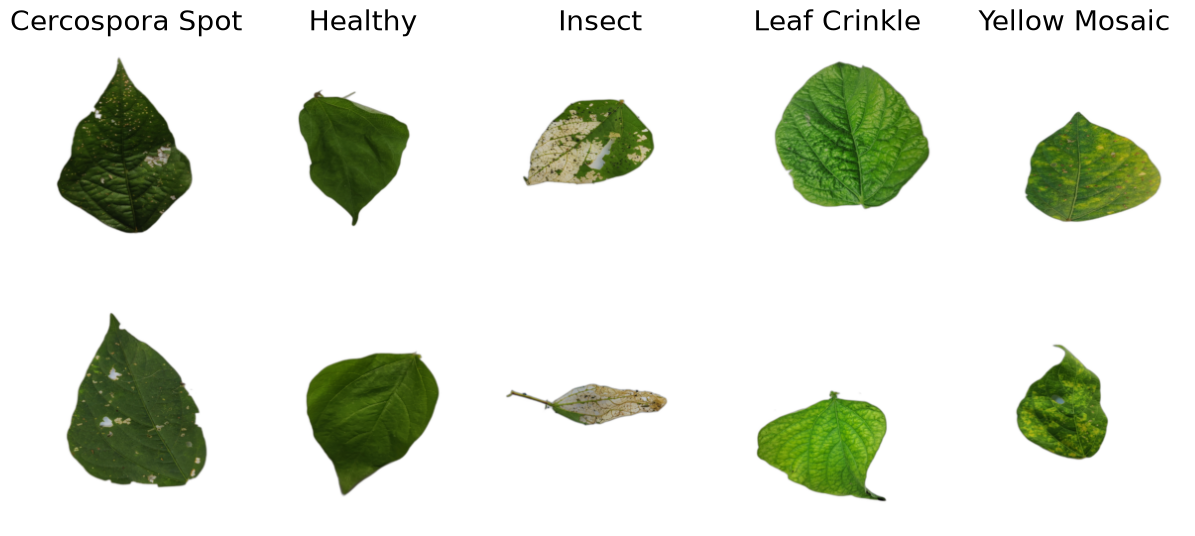

In [18]:
from PIL import Image

# Define a transform to resize images and convert them to tensors
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize images to 512x512 for uniformity
    transforms.ToTensor()
])

# Number of rows and columns
rows, cols = 2, 5

# Ensure categories list contains at least `cols` categories
if len(categories) < cols:
    raise ValueError("Not enough categories to display.")

# Initialize a figure for visualization
plt.figure(figsize=(12, 6))  # Adjusted figure size for better clarity with 2 rows and 5 columns

# Iterate twice to create two rows with different images from the same categories
for row in range(rows):
    for col, category in enumerate(categories[:cols]):  # Use the first `cols` categories
        # Get the path of the category folder
        category_path = os.path.join(data_dir, category)

        # Get the list of image files in the category folder
        image_files = [file for file in os.listdir(category_path) if file.lower().endswith(('png', 'jpg', 'jpeg', 'bmp', 'tiff'))]

        # Ensure there is at least one image in the category
        if not image_files:
            print(f"No images found in category: {category}")
            continue

        # Randomly select an image from the category
        image_path = os.path.join(category_path, random.choice(image_files))
        image = Image.open(image_path).convert("RGB")

        # Apply the transform
        image = transform(image)

        # Convert the tensor back to a PIL image for visualization
        image = transforms.ToPILImage()(image)

        # Add the image to the plot
        plt.subplot(rows, cols, row * cols + col + 1)
        plt.imshow(image)
        
        # Set title only for the first row
        if row == 0:
            plt.title(category, fontsize=20)
        
        plt.axis('off')

# Adjust layout and display the plot
plt.tight_layout()
plt.savefig('D:\\438-ProjectImg\\D2.png', format='png', dpi=600)
plt.show()


# Data transformation & Splitting

In [6]:
data_transform = transforms.Compose([
    transforms.ToTensor(),  # Convert to Tensor first
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

In [5]:
train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df['labels'], random_state=42)  # 80% train, 20% temp
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df['labels'], random_state=42)  # 75% of temp (15% of total) for test(15% of total) for test

In [6]:
import pandas as pd

# Assuming train_df, val_df, and test_df have a 'labels' column
train_counts = train_df['labels'].value_counts()
val_counts = val_df['labels'].value_counts()
test_counts = test_df['labels'].value_counts()

# Combine into a single DataFrame
class_counts = pd.DataFrame({
    'Training': train_counts,
    'Validation': val_counts,
    'Testing': test_counts
}).fillna(0).astype(int)  # Fill NaN with 0 and convert to integer

# Add a column for total counts (optional)
class_counts['Total'] = class_counts.sum(axis=1)

# Display the table
print(class_counts)

                      Training  Validation  Testing  Total
labels                                                    
Yellow Mosaic             1345         168      168   1681
Leaf Crinkle               645          81       80    806
Cercospora leaf spot       478          60       60    598
Healthy                    436          54       55    545
Insect                     326          41       41    408


# Train set Augmentation

In [43]:
import os
import numpy as np
from PIL import Image
import albumentations as A
from tqdm import tqdm

# --------------------------------------------------
# ALBUMENTATIONS PIPELINE
# --------------------------------------------------
train_aug_seq = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Affine(scale=(0.9, 1.1), rotate=(-15, 15), p=1.0),
    A.RandomBrightnessContrast(brightness_limit=(0.0, 0.2), contrast_limit=0.0, p=1.0),
    A.GaussianBlur(blur_limit=(5, 5), p=0.5),  # 5x5 Gaussian Kernel blur
])

# --------------------------------------------------
# OFFLINE TRAIN AUGMENTATION FUNCTION
# --------------------------------------------------
def offline_augment_train(train_df, output_root, target_per_class=2000):

    os.makedirs(output_root, exist_ok=True)

    for label in train_df['labels'].unique():

        print(f"\nProcessing class: {label}")

        class_df = train_df[train_df['labels'] == label]
        class_images = class_df['filepaths'].values

        class_output_dir = os.path.join(output_root, label)
        os.makedirs(class_output_dir, exist_ok=True)

        original_count = len(class_images)

        # Copy original images first
        for idx, img_path in enumerate(class_images):
            img = Image.open(img_path).convert("RGB")
            save_path = os.path.join(class_output_dir, f"original_{idx}.jpg")
            img.save(save_path, quality=100)

        print(f"Original images saved: {original_count}")

        # Determine augmentations needed
        if original_count >= target_per_class:
            print("No augmentation needed (already balanced).")
            continue

        augment_needed = target_per_class - original_count
        augment_per_image = augment_needed // original_count + 1

        augmented_count = 0

        for idx, img_path in enumerate(tqdm(class_images)):

            image = np.array(Image.open(img_path).convert("RGB"))

            for j in range(augment_per_image):

                # Apply Albumentations transformation
                augmented = train_aug_seq(image=image)["image"]
                augmented_pil = Image.fromarray(augmented)

                save_path = os.path.join(
                    class_output_dir,
                    f"aug_{idx}_{j}.jpg"
                )
                augmented_pil.save(save_path, quality=100)

                augmented_count += 1

                if original_count + augmented_count >= target_per_class:
                    break

            if original_count + augmented_count >= target_per_class:
                break

        print(f"Augmented images created: {augmented_count}")
        print(f"Total images in class '{label}': {original_count + augmented_count}")

In [44]:
expanded_train_dir = "D:\\Black Gram Leaf\\TrainAug"

offline_augment_train(
    train_df,
    expanded_train_dir,
    target_per_class=2000   # ← choose desired class size
)


Processing class: Healthy
Original images saved: 436


 89%|████████▉ | 390/436 [00:08<00:01, 43.75it/s]


Augmented images created: 1564
Total images in class 'Healthy': 2000

Processing class: Yellow Mosaic
Original images saved: 1345


 49%|████▊     | 654/1345 [00:05<00:05, 119.62it/s]


Augmented images created: 655
Total images in class 'Yellow Mosaic': 2000

Processing class: Insect
Original images saved: 326


...

Augmented images created: 1674
Total images in class 'Insect': 2000

Processing class: Cercospora leaf spot
Original images saved: 478


 79%|███████▉  | 380/478 [00:08<00:02, 45.17it/s]


Augmented images created: 1522
Total images in class 'Cercospora leaf spot': 2000

Processing class: Leaf Crinkle
Original images saved: 645


 70%|██████▉   | 451/645 [00:08<00:03, 55.73it/s]

Augmented images created: 1355
Total images in class 'Leaf Crinkle': 2000


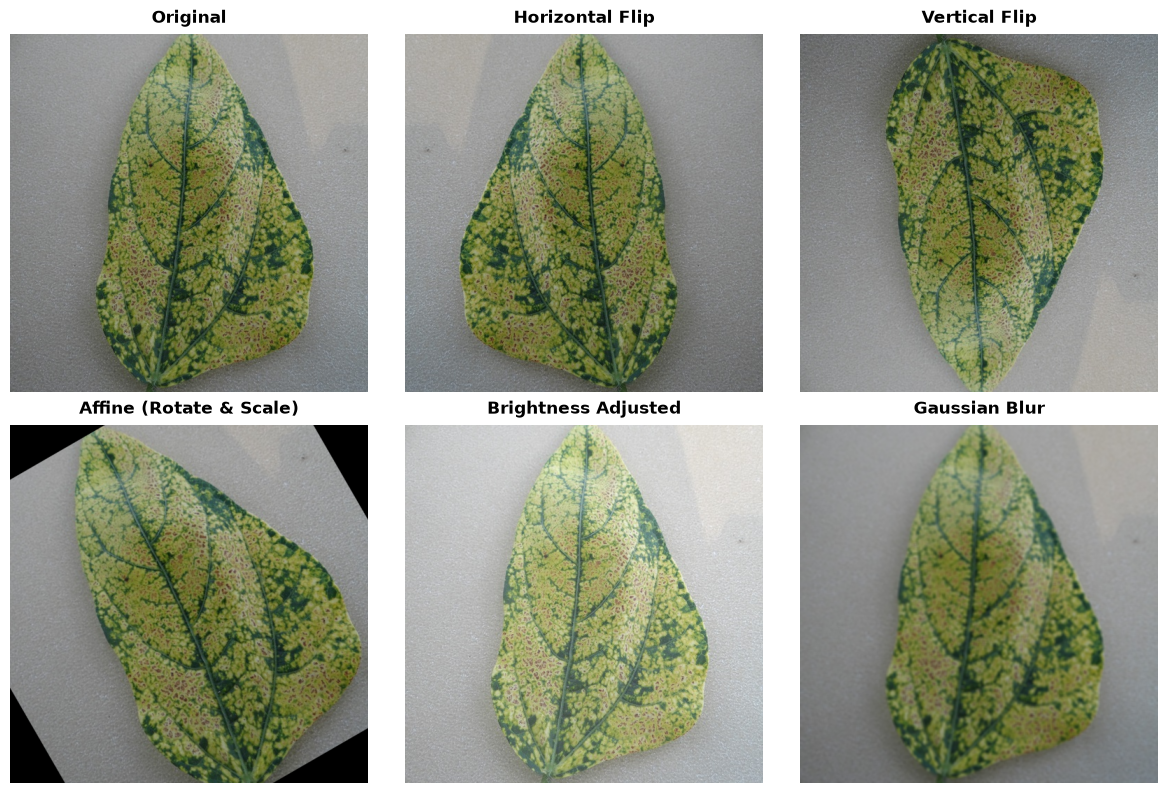

In [6]:
import os
import albumentations as A
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# 1. Load sample image using a raw string (r"...") for Windows paths
sample_image_path = r"D:\BPLD Dataset\Original\Yellow Mosaic\63y.jpg"

image = np.array(Image.open(sample_image_path).convert("RGB"))

# 2. Define individual transforms with p=1.0 to isolate each technique
augmentations = {
    "Original": None,
    "Horizontal Flip": A.HorizontalFlip(p=1.0),
    "Vertical Flip": A.VerticalFlip(p=1.0),
    "Affine (Rotate & Scale)": A.Affine(scale=1.1, rotate=30, p=1.0),
    "Brightness Adjusted": A.RandomBrightnessContrast(
        brightness_limit=(0.2, 0.2), contrast_limit=0.0, p=1.0
    ),
    "Gaussian Blur": A.GaussianBlur(blur_limit=(5, 5), p=1.0),
}

# 3. Create a 2x3 subplot grid to display each technique
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for idx, (title, transform) in enumerate(augmentations.items()):
  if transform is None:
    transformed_img = image
  else:
    transformed_img = transform(image=image)["image"]

  axes[idx].imshow(transformed_img)
  axes[idx].set_title(title, fontsize=12, fontweight="bold", pad=8)
  axes[idx].axis("off")

plt.tight_layout()

# 4. Save high-resolution image using raw string for the destination directory
output_file = (
    r"C:\Users\Samiz\OneDrive\Pictures\Blckgrm\augmentation_samples.png"
)
plt.savefig(output_file, dpi=600, bbox_inches="tight")
plt.show()

In [49]:
def loading_the_data(data_dir):
    filepaths = []
    labels = []

    folds = os.listdir(data_dir)

    for fold in folds:
        foldpath = os.path.join(data_dir, fold)
        filelist = os.listdir(foldpath)

        for file in filelist:
            filepaths.append(os.path.join(foldpath, file))
            labels.append(fold)

    return pd.DataFrame({"filepaths": filepaths, "labels": labels})

In [50]:
expanded_train_df = loading_the_data(expanded_train_dir)

In [51]:
label_mapping = {label: idx for idx, label in enumerate(df['labels'].unique())}

train_labels = train_df['labels'].map(label_mapping).values
val_labels = val_df['labels'].map(label_mapping).values
test_labels = test_df['labels'].map(label_mapping).values

In [52]:
from my_dataset import CustomImageDataset
train_dataset = CustomImageDataset(
    expanded_train_df['filepaths'].values,
    expanded_train_df['labels'].map(label_mapping).values,
    transform=data_transform
)

val_dataset = CustomImageDataset(
    val_df['filepaths'].values,
    val_labels,
    transform=data_transform
)

test_dataset = CustomImageDataset(
    test_df['filepaths'].values,
    test_labels,
    transform=data_transform
)

In [53]:
train_loader = DataLoader(train_dataset, batch_size=32,
                          shuffle=True, num_workers=4, pin_memory=True)

val_loader = DataLoader(val_dataset, batch_size=32,
                        shuffle=False, num_workers=4, pin_memory=True)

test_loader = DataLoader(test_dataset, batch_size=32,
                         shuffle=False, num_workers=0, pin_memory=True)

In [54]:

# Assuming train_df, val_df, and test_df have a 'labels' column
train_counts = expanded_train_df['labels'].value_counts()
val_counts = val_df['labels'].value_counts()
test_counts = test_df['labels'].value_counts()

# Combine into a single DataFrame
class_counts = pd.DataFrame({
    'Training': train_counts,
    'Validation': val_counts,
    'Testing': test_counts
}).fillna(0).astype(int)  # Fill NaN with 0 and convert to integer

# Add a column for total counts (optional)(optional)
class_counts['Total'] = class_counts.sum(axis=1)

# Display the table
print(class_counts)

                      Training  Validation  Testing  Total
labels                                                    
Cercospora leaf spot      2000          60       60   2120
Healthy                   2000          54       55   2109
Insect                    2000          41       41   2082
Leaf Crinkle              2000          81       80   2161
Yellow Mosaic             2000         168      168   2336


In [7]:
import os
import pandas as pd
from torch.utils.data import DataLoader
from torchvision import transforms

# 1. Define your online augmentation using standard PyTorch transforms
# This perfectly mimics your imgaug pipeline

# Training transforms (No Resize needed)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomAffine(degrees=[-15, 15], scale=[0.9, 1.1]),
    transforms.ColorJitter(brightness=[1.0, 1.2]),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation & Test transforms (No Resize needed)
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


# 2. Extract Labels for mappings
label_mapping = {label: idx for idx, label in enumerate(train_df['labels'].unique())}

# Get numerical labels
train_labels = train_df['labels'].map(label_mapping).values
val_labels = val_df['labels'].map(label_mapping).values
test_labels = test_df['labels'].map(label_mapping).values


# 3. Create Datasets directly from the ORIGINAL dataframes
from my_dataset1 import CustomImageDataset

# Use train_transform here!
train_dataset = CustomImageDataset(
    filepaths=train_df['filepaths'].values,  # <-- Use original train_df
    labels=train_labels,
    transform=train_transform                # <-- Pass the augmentation transform
)

# Use val_test_transform here!
val_dataset = CustomImageDataset(
    filepaths=val_df['filepaths'].values,
    labels=val_labels,
    transform=val_test_transform             # <-- No augmentations
)

# Use val_test_transform here!
test_dataset = CustomImageDataset(
    filepaths=test_df['filepaths'].values,
    labels=test_labels,
    transform=val_test_transform             # <-- No augmentations
)


# 4. Create DataLoaders
train_loader = DataLoader(
    train_dataset, 
    batch_size=32, 
    shuffle=True, 
    num_workers=4, 
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=32, 
    shuffle=False, 
    num_workers=4, 
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset, 
    batch_size=32, 
    shuffle=False, 
    num_workers=0, 
    pin_memory=True
)

# Model Training and testing functions

In [8]:
# Model setup
if not torch.cuda.is_available():
    raise RuntimeError('CUDA device is not available. Please ensure a GPU is available to train the model.')
device = torch.device('cuda')

In [9]:
import time
from torch.cuda.amp import autocast, GradScaler

def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=20, patience=5, min_delta=0.001):
    model.to(device)
    scaler = GradScaler()  # AMP gradient scaler

    train_losses, train_accuracies = [], []
    val_losses, val_accuracies = [], []

    best_val_loss = float('inf')
    patience_counter = 0
    best_epoch = 0

    start_time = time.time()  # Start timing
    total_inference_time = 0.0  # <-- Track inference time

    for epoch in range(num_epochs):
        model.train()
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 30)
        running_loss = 0.0
        correct = 0
        total = 0

        # Training loop with AMP
        for inputs, labels in tqdm(train_loader, desc='Training', leave=False):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()

            with autocast():  # Forward pass in mixed precision
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = correct / total
        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_acc)

        # Validation loop with AMP (inference only)
        model.eval()
        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        val_start_time = time.time()  # <-- start inference timing
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                with autocast():
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)

                val_running_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
        val_end_time = time.time()
        total_inference_time += (val_end_time - val_start_time)  # <-- accumulate inference time

        val_loss = val_running_loss / len(val_loader.dataset)
        val_acc = val_correct / val_total
        val_losses.append(val_loss)
        val_accuracies.append(val_acc)

        print(f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_acc:.4f}')
        print(f'Training Loss: {epoch_loss:.4f}, Training Accuracy: {epoch_acc:.4f}')

        # Early Stopping
        if best_val_loss - val_loss > min_delta:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            patience_counter = 0
        else:
            patience_counter += 1
            print(f"Patience Counter: {patience_counter}/{patience}")

        if patience_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch+1}.")
            break

        scheduler.step()

    end_time = time.time()  # End timing
    elapsed_time = end_time - start_time
    hours, rem = divmod(elapsed_time, 3600)
    minutes, seconds = divmod(rem, 60)

    # Inference time breakdown
    inf_hours, inf_rem = divmod(total_inference_time, 3600)
    inf_minutes, inf_seconds = divmod(inf_rem, 60)

    total_epochs_run = epoch + 1
    epochs_range = range(1, total_epochs_run + 1)

    # Plotting curves
    plt.figure(figsize=(20, 8))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, train_losses, marker='o', label='Training Loss')
    plt.plot(epochs_range, val_losses, marker='o', label='Validation Loss')
    plt.axvline(x=best_epoch, color='red', linestyle='--', label='Best Epoch')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Loss Curve')
    plt.legend()

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, train_accuracies, marker='o', label='Training Accuracy')
    plt.plot(epochs_range, val_accuracies, marker='o', label='Validation Accuracy')
    plt.axvline(x=best_epoch, color='red', linestyle='--', label='Best Epoch')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Accuracy Curve')
    plt.legend()

    plt.tight_layout()
    plt.show()

    # Reports
    print("\nTraining Report:")
    print(f"Total training time: {int(hours):02d}:{int(minutes):02d}:{int(seconds):02d}")
    print(f"Total epochs run: {total_epochs_run}")
    print(f"Best Training Loss: {train_losses[best_epoch-1]:.4f} at epoch {best_epoch}")
    print(f"Best Training Accuracy: {train_accuracies[best_epoch-1]:.4f}")

    print("\nValidation Report:")
    print(f"Best Validation Loss: {best_val_loss:.4f} at epoch {best_epoch}")
    print(f"Best Validation Accuracy: {val_accuracies[best_epoch-1]:.4f}")
    print(f"Final Validation Loss: {val_losses[-1]:.4f}")
    print(f"Final Validation Accuracy: {val_accuracies[-1]:.4f}")

    print("\nInference Report:")
    print(f"Total Inference Time (Validation only): {int(inf_hours):02d}:{int(inf_minutes):02d}:{int(inf_seconds):02d}")


In [10]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from itertools import cycle
import torch

def evaluate_model(model, dataloader, label_mapping):
    model.eval()
    correct = 0
    total = 0
    all_labels = []
    all_preds = []
    all_probs = []
    
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)

            # Predicted class
            _, predicted = torch.max(outputs, 1)

            # Convert to probabilities
            probs = torch.softmax(outputs, dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(predicted.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    
    # Accuracy
    accuracy = correct / total
    print(f'Accuracy: {accuracy:.4f}')
    
    # Classification Report
    print(classification_report(all_labels, all_preds, target_names=list(label_mapping.keys())))
    
    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_mapping.keys(),
                yticklabels=label_mapping.keys(),
                cbar_kws={'shrink': 0.8})
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.xlabel('Predicted', fontsize=14)
    plt.ylabel('True', fontsize=14)
    plt.title('Confusion Matrix', fontsize=16)
    plt.show()
    
    all_probs = np.array(all_probs)
    n_classes = len(label_mapping)

    # ===== Binary Classification =====
    if n_classes == 2:
        y_true = np.array(all_labels)
        plt.figure(figsize=(12, 5))

        # ROC curves
        plt.subplot(1, 2, 1)
        for class_idx in [0, 1]:
            y_binary = (y_true == class_idx).astype(int)
            y_score = all_probs[:, class_idx]
            fpr, tpr, _ = roc_curve(y_binary, y_score)
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, lw=2, label=f'Class {class_idx} (AUC = {roc_auc:.2f})')
        plt.plot([0, 1], [0, 1], 'k--', lw=2)
        plt.xlabel('False Positive Rate', fontsize=12)
        plt.ylabel('True Positive Rate', fontsize=12)
        plt.title('ROC AUC Curve', fontsize=14)
        plt.legend()

        # PR curves
        plt.subplot(1, 2, 2)
        for class_idx in [0, 1]:
            y_binary = (y_true == class_idx).astype(int)
            y_score = all_probs[:, class_idx]
            precision, recall, _ = precision_recall_curve(y_binary, y_score)
            pr_auc = auc(recall, precision)
            plt.plot(recall, precision, lw=2, label=f'Class {class_idx} (AUC = {pr_auc:.2f})')
        plt.xlabel('Recall', fontsize=12)
        plt.ylabel('Precision', fontsize=12)
        plt.title('Precision-Recall Curve', fontsize=14)
        plt.legend()

        plt.tight_layout()
        plt.show()

    # ===== Multi-class Classification =====
    else:
        y_test_bin = label_binarize(all_labels, classes=range(n_classes))
        fpr, tpr, roc_auc = {}, {}, {}
        precision, recall, pr_auc = {}, {}, {}

        colors = cycle(['blue', 'red', 'green', 'orange', 'purple', 'cyan'])

        # ROC Curve
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        for i, color in zip(range(n_classes), colors):
            fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], all_probs[:, i])
            roc_auc[i] = auc(fpr[i], tpr[i])
            plt.plot(fpr[i], tpr[i], color=color, lw=2,
                     label=f'Class {i} (AUC = {roc_auc[i]:0.2f})')
        plt.plot([0, 1], [0, 1], 'k--', lw=2)
        plt.xlabel('False Positive Rate', fontsize=12)
        plt.ylabel('True Positive Rate', fontsize=12)
        plt.title('ROC AUC Curve', fontsize=14)
        plt.legend()

        # PR Curve
        plt.subplot(1, 2, 2)
        colors = cycle(['blue', 'red', 'green', 'orange', 'purple', 'cyan'])
        for i, color in zip(range(n_classes), colors):
            precision[i], recall[i], _ = precision_recall_curve(y_test_bin[:, i], all_probs[:, i])
            pr_auc[i] = auc(recall[i], precision[i])
            plt.plot(recall[i], precision[i], color=color, lw=2,
                     label=f'Class {i} (AUC = {pr_auc[i]:0.2f})')
        plt.xlabel('Recall', fontsize=12)
        plt.ylabel('Precision', fontsize=12)
        plt.title('Precision-Recall Curve', fontsize=14)
        plt.legend()

        plt.tight_layout()
        plt.show()


In [20]:
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score, 
    matthews_corrcoef, average_precision_score, cohen_kappa_score, confusion_matrix
)
import numpy as np
import torch

def evaluate_model_with_metrics(model, dataloader):
    model.eval()
    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            probs = torch.softmax(outputs, dim=1)  # for PR AUC

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    # Base metrics
    accuracy = accuracy_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    mcc = matthews_corrcoef(all_labels, all_preds)

    # PR AUC (weighted average)
    try:
        pr_auc = average_precision_score(all_labels, all_probs, average="weighted")
    except ValueError:
        pr_auc = float('nan')

    # Cohen's Kappa
    kappa = cohen_kappa_score(all_labels, all_preds)

    # Specificity (macro average)
    cm = confusion_matrix(all_labels, all_preds)
    TN = []
    FP = []
    for i in range(len(cm)):
        tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
        fp = cm[:, i].sum() - cm[i, i]
        TN.append(tn)
        FP.append(fp)
    specificity_per_class = [TN[i] / (TN[i] + FP[i]) if (TN[i] + FP[i]) > 0 else 0 for i in range(len(cm))]
    specificity = np.average(specificity_per_class)  # macro average

    # Print metrics
    print(f"Accuracy:    {accuracy:.5f}")
    print(f"Recall:      {recall:.5f}")
    print(f"Precision:   {precision:.5f}")
    print(f"F1 Score:    {f1:.5f}")
    print(f"MCC:         {mcc:.5f}")
    print(f"PR AUC:      {pr_auc:.5f}")
    print(f"Kappa:       {kappa:.5f}")
    print(f"Specificity: {specificity:.5f}")


In [64]:
torch.save(model.state_dict(), "ProposedBean2New.pth")

In [17]:
torch.save(model.state_dict(), "ProposedBean2.pth")

In [22]:
torch.save(model.state_dict(), "ProposedBeanModel100.pth")

In [65]:
torch.cuda.empty_cache()

# Proposed Model

In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# ══════════════════════════════════════════════════════════════════════════════
# 1. User-Proposed Enhancements (Preserved from LightBeanFormerV2)
# ══════════════════════════════════════════════════════════════════════════════

class DropPath(nn.Module):
    def __init__(self, drop_prob=0.0):
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x):
        if self.drop_prob == 0.0 or not self.training:
            return x
        keep_prob = 1 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = keep_prob + torch.rand(shape, dtype=x.dtype, device=x.device)
        return x.div(keep_prob) * random_tensor.floor_()

class LayerScale(nn.Module):
    def __init__(self, channels: int, init_value: float = 1e-4):
        super().__init__()
        self.gamma = nn.Parameter(init_value * torch.ones(channels))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * self.gamma.view(1, -1, 1, 1)

class LBSA(nn.Module):
    """Local Boundary Spatial Attention"""
    def __init__(self, kernel_size=7):
        super().__init__()
        self.stat_conv   = nn.Conv2d(2, 1, kernel_size, padding=kernel_size//2, bias=False)
        lap = torch.tensor([[0.,-1.,0.],[-1.,4.,-1.],[0.,-1.,0.]]).view(1,1,3,3)
        self.register_buffer("lap_kernel", lap.repeat(1,2,1,1))
        self.boundary_bn = nn.BatchNorm2d(1)
        self.alpha       = nn.Parameter(torch.zeros(1))
        self.sigmoid     = nn.Sigmoid()

    def forward(self, x):
        avg_m    = torch.mean(x, dim=1, keepdim=True)
        max_m, _ = torch.max(x,  dim=1, keepdim=True)
        maps     = torch.cat([avg_m, max_m], dim=1)
        stat_map = self.stat_conv(maps)
        bound_map= self.boundary_bn(F.conv2d(maps, self.lap_kernel, padding=1))
        alpha    = self.sigmoid(self.alpha)
        return x * self.sigmoid(alpha * stat_map + (1.0 - alpha) * bound_map)

class GLocalHead(nn.Module):
    """Global-Local Hierarchical Classification Head"""
    def __init__(self, in_channels, num_classes, dropout=0.3):
        super().__init__()
        self.gap        = nn.AdaptiveAvgPool2d(1)
        self.local_pool = nn.AdaptiveAvgPool2d(2)                     
        self.local_proj = nn.Conv2d(in_channels, in_channels // 4, 1, bias=False)
        self.norm       = nn.LayerNorm(in_channels * 2)
        self.dropout    = nn.Dropout(dropout)
        self.fc         = nn.Linear(in_channels * 2, num_classes)

    def forward(self, x):
        g   = self.gap(x).flatten(1)                                  
        loc = self.local_proj(self.local_pool(x)).flatten(1)          
        return self.fc(self.dropout(self.norm(torch.cat([g, loc], dim=1))))

# ══════════════════════════════════════════════════════════════════════════════
# 2. Enhanced LightNeSt Core
# ══════════════════════════════════════════════════════════════════════════════

class RadixASEPConv(nn.Module):
    """
    Split-Attention with Depthwise Convs, upgraded with ASEP-style pooling.
    Uses both Max and Avg pooling to generate attention weights.
    """
    def __init__(self, channels, radix=2, stride=1):
        super().__init__()
        self.radix = radix
        self.branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(channels, channels, kernel_size=3, stride=stride, padding=1, 
                          groups=channels, bias=False),
                nn.BatchNorm2d(channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(channels, channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(channels),
                nn.ReLU(inplace=True)
            ) for _ in range(radix)
        ])
        
        inter_channels = max(32, channels // 4)
        self.fc1 = nn.Conv2d(channels, inter_channels, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(inter_channels)
        self.fc2 = nn.Conv2d(inter_channels, channels * radix, kernel_size=1)
        
    def forward(self, x):
        branch_outs = [branch(x) for branch in self.branches]
        U = sum(branch_outs)
        
        # ASEP-style dual pooling injection
        S_avg = F.adaptive_avg_pool2d(U, 1)
        S_max = F.adaptive_max_pool2d(U, 1)
        S = S_avg + S_max
        
        Z = F.relu(self.bn1(self.fc1(S)), inplace=True)
        weight = self.fc2(Z)
        
        B, _, H, W = weight.shape
        weight = weight.view(B, self.radix, -1, 1, 1)
        attention_weights = F.softmax(weight, dim=1)
        
        return sum(branch_outs[i] * attention_weights[:, i] for i in range(self.radix))

class LightNeStBlockV2(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, drop_path=0.0):
        super().__init__()
        mid_channels = out_channels // 2
        
        self.conv1 = nn.Conv2d(in_channels, mid_channels, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(mid_channels)
        
        self.radix_conv = RadixASEPConv(mid_channels, radix=2, stride=stride)
        
        self.conv3 = nn.Conv2d(mid_channels, out_channels, kernel_size=1, bias=False)
        self.bn3 = nn.BatchNorm2d(out_channels)
        
        # Inject user's Local Boundary Spatial Attention
        self.lbsa = LBSA()
        
        # Regularization on residual branch
        self.ls = LayerScale(out_channels)
        self.drop_path = DropPath(drop_path) if drop_path > 0.0 else nn.Identity()
        
        self.downsample = None
        if stride != 1 or in_channels != out_channels:
            if stride != 1:
                self.downsample = nn.Sequential(
                    nn.AvgPool2d(kernel_size=2, stride=stride, ceil_mode=True),
                    nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                    nn.BatchNorm2d(out_channels)
                )
            else:
                self.downsample = nn.Sequential(
                    nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                    nn.BatchNorm2d(out_channels)
                )
                
    def forward(self, x):
        identity = self.downsample(x) if self.downsample else x
        
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.radix_conv(out)
        out = self.bn3(self.conv3(out))
        out = self.lbsa(out)
        
        out = self.drop_path(self.ls(out))
        return F.relu(out + identity, inplace=True)

class LightBASNeSt(nn.Module):
    def __init__(self, num_classes, layers=[3, 4, 6, 3], channels=[96, 192, 384, 576], drop_path_rate=0.1):
        super().__init__()
        
        stem_out = channels[0] // 2
        self.stem = nn.Sequential(
            nn.Conv2d(3, stem_out // 2, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(stem_out // 2),
            nn.ReLU(inplace=True),
            nn.Conv2d(stem_out // 2, stem_out // 2, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(stem_out // 2),
            nn.ReLU(inplace=True),
            nn.Conv2d(stem_out // 2, stem_out, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(stem_out),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        
        self.in_channels = stem_out
        
        # Total blocks = sum(layers)
        dpr = [x.item() for x in torch.linspace(0, drop_path_rate, sum(layers))]
        
        # Dynamic dpr index tracking
        idx = 0
        self.layer1 = self._make_layer(channels[0], layers[0], stride=1, dpr=dpr[idx : idx + layers[0]])
        idx += layers[0]
        
        self.layer2 = self._make_layer(channels[1], layers[1], stride=2, dpr=dpr[idx : idx + layers[1]])
        idx += layers[1]
        
        self.layer3 = self._make_layer(channels[2], layers[2], stride=2, dpr=dpr[idx : idx + layers[2]])
        idx += layers[2]
        
        self.layer4 = self._make_layer(channels[3], layers[3], stride=2, dpr=dpr[idx : idx + layers[3]])
        
        self.head = GLocalHead(channels[3], num_classes)
        
    def _make_layer(self, out_channels, blocks, stride, dpr):
        layer_list = []
        layer_list.append(LightNeStBlockV2(self.in_channels, out_channels, stride=stride, drop_path=dpr[0]))
        self.in_channels = out_channels
        for i in range(1, blocks):
            layer_list.append(LightNeStBlockV2(self.in_channels, out_channels, stride=1, drop_path=dpr[i]))
        return nn.Sequential(*layer_list)
        
    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return self.head(x)



In [17]:
import math

import torch

import torch.nn as nn

import torch.optim as optim

from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR



# ══════════════════════════════════════════════════════════════════════════════

# 1. Weight Initialization

# ══════════════════════════════════════════════════════════════════════════════

def init_weights(m):

    if isinstance(m, nn.Conv2d):

        nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')

        if m.bias is not None:

            nn.init.zeros_(m.bias)

    elif isinstance(m, (nn.BatchNorm2d, nn.LayerNorm)):

        nn.init.ones_(m.weight)

        if hasattr(m, 'bias') and m.bias is not None:

            nn.init.zeros_(m.bias)

    elif isinstance(m, nn.Linear):

        nn.init.trunc_normal_(m.weight, std=0.02)

        if m.bias is not None:

            nn.init.zeros_(m.bias)



def load_custom_model(num_classes, device):

    model = LightNeStV2(
        num_classes=num_classes, 
        layers=[3, 4, 6, 3], 
        channels=[96, 192, 384, 576]
    )

    model.apply(init_weights)  # Apply explicit initialization

    return model.to(device)



# ══════════════════════════════════════════════════════════════════════════════

# 2. Parameter Grouping (Excluding Norm/Bias from Weight Decay)

# ══════════════════════════════════════════════════════════════════════════════

def get_parameter_groups(model, weight_decay=1e-2):

    decay = []

    no_decay = []

    for name, param in model.named_parameters():

        if not param.requires_grad:

            continue

        # Exclude 1D parameters, relative position bias tables, and biases

        if param.ndim <= 1 or 'relative_position_bias_table' in name or 'bias' in name:

            no_decay.append(param)

        else:

            decay.append(param)

    return [

        {'params': decay, 'weight_decay': weight_decay},

        {'params': no_decay, 'weight_decay': 0.0}

    ]



In [18]:
import math

import torch

import torch.nn as nn

import torch.optim as optim

from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR



# ══════════════════════════════════════════════════════════════════════════════

# 3. 30-Epoch Optimized Training Pipeline

# ══════════════════════════════════════════════════════════════════════════════

num_classes = len(label_mapping)

model = load_custom_model(num_classes, device)



# Loss function

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)  # Label smoothing for better generalization



# Parameter groups with separated weight decay

param_groups = get_parameter_groups(model, weight_decay=0.02)


# 3e-4 helps train slightly faster than 1e-4 within 30 epochs without destabilizing

optimizer = optim.AdamW(param_groups, lr=5e-4)



# 30-Epoch Schedule Configuration

total_epochs = 30

warmup_epochs = 3  # ~10% of total training time



warmup_scheduler = LinearLR(

    optimizer, 

    start_factor=0.1, 

    end_factor=1.0, 

    total_iters=warmup_epochs

)



cosine_scheduler = CosineAnnealingLR(

    optimizer, 

    T_max=total_epochs - warmup_epochs,  # 27 epochs of cosine decay

    eta_min=1e-6

)



# Combined Warmup + Cosine Decay

scheduler = SequentialLR(

    optimizer,

    schedulers=[warmup_scheduler, cosine_scheduler],

    milestones=[warmup_epochs]

)


Epoch 1/30
------------------------------


Validation Loss: 0.8395, Validation Accuracy: 0.7550
Training Loss: 1.1382, Training Accuracy: 0.6065

Epoch 2/30
------------------------------


Validation Loss: 0.7091, Validation Accuracy: 0.8639
Training Loss: 0.8543, Training Accuracy: 0.7697

Epoch 3/30
------------------------------


Validation Loss: 0.9669, Validation Accuracy: 0.7649
Training Loss: 0.7370, Training Accuracy: 0.8458
Patience Counter: 1/5

Epoch 4/30
------------------------------


Validation Loss: 0.7166, Validation Accuracy: 0.8243
Training Loss: 0.6825, Training Accuracy: 0.8684
Patience Counter: 2/5

Epoch 5/30
------------------------------


...

Validation Loss: 0.4169, Validation Accuracy: 0.9926
Training Loss: 0.4131, Training Accuracy: 0.9935
Patience Counter: 1/5

Epoch 27/30
------------------------------


Validation Loss: 0.4124, Validation Accuracy: 0.9926
Training Loss: 0.4118, Training Accuracy: 0.9954
Patience Counter: 2/5

Epoch 28/30
------------------------------


Validation Loss: 0.4141, Validation Accuracy: 0.9901
Training Loss: 0.4084, Training Accuracy: 0.9947
Patience Counter: 3/5

Epoch 29/30
------------------------------


Validation Loss: 0.4125, Validation Accuracy: 0.9950
Training Loss: 0.4111, Training Accuracy: 0.9938
Patience Counter: 4/5

Epoch 30/30
------------------------------


Validation Loss: 0.4119, Validation Accuracy: 0.9950
Training Loss: 0.4082, Training Accuracy: 0.9960


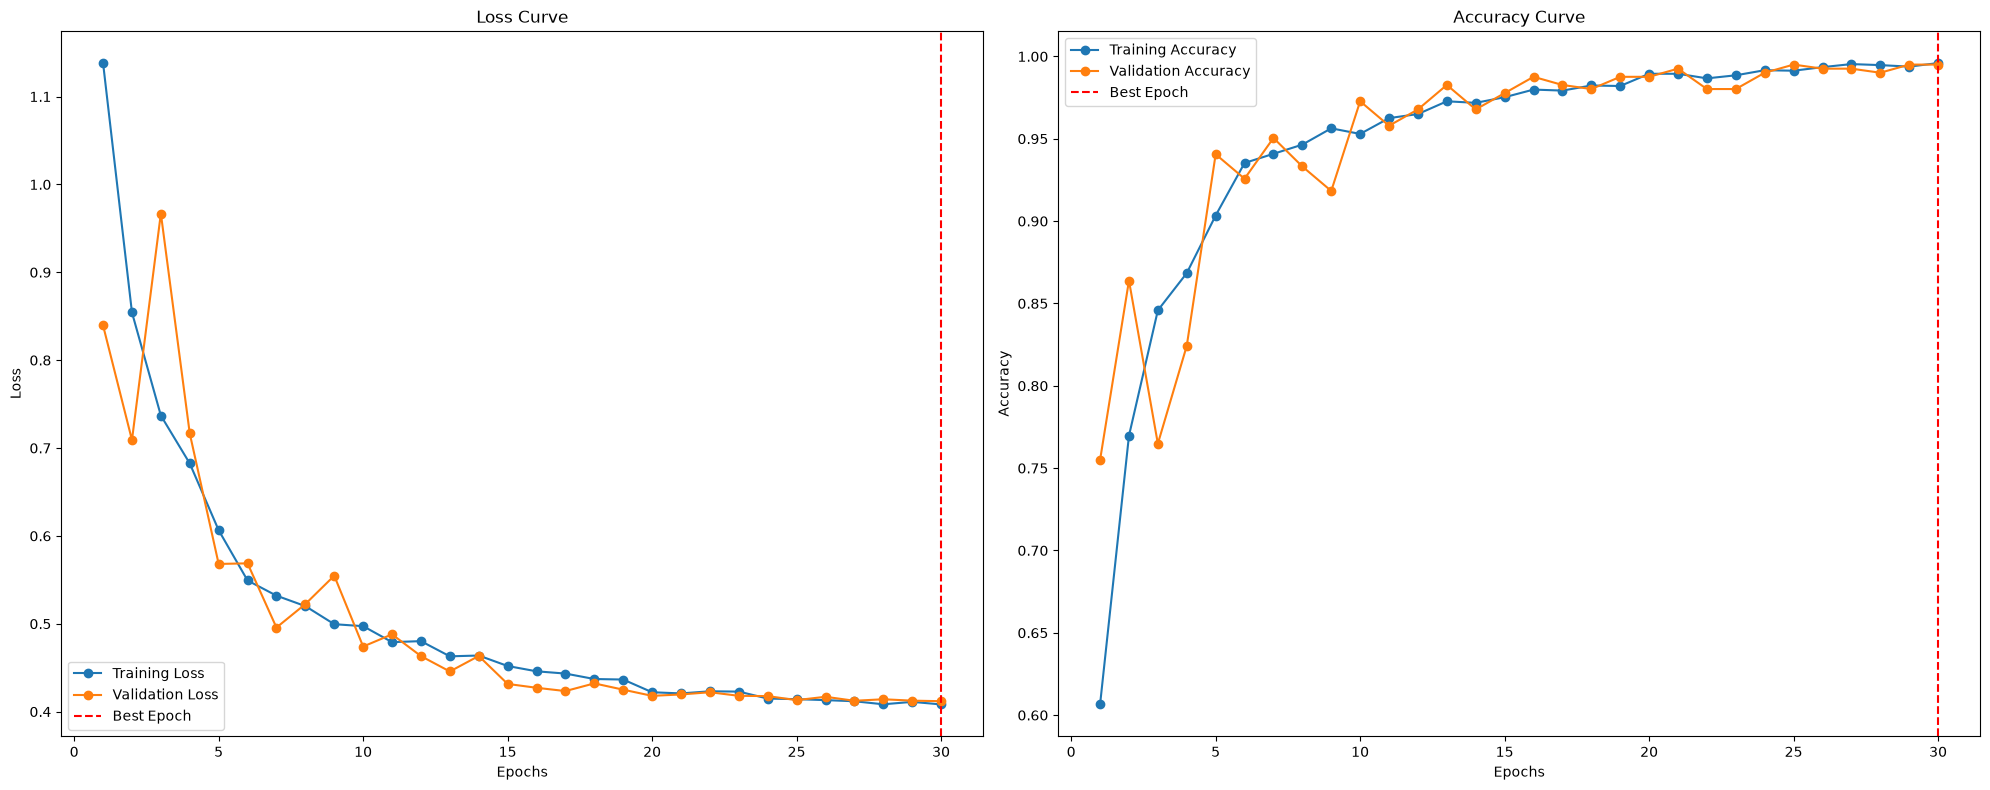


Training Report:
Total training time: 00:12:56
Total epochs run: 30
Best Training Loss: 0.4082 at epoch 30
Best Training Accuracy: 0.9960

Validation Report:
Best Validation Loss: 0.4119 at epoch 30
Best Validation Accuracy: 0.9950
Final Validation Loss: 0.4119
Final Validation Accuracy: 0.9950

Inference Report:
Total Inference Time (Validation only): 00:02:12


In [41]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [15]:
model.load_state_dict(torch.load("ProposedBean2.pth"))

<All keys matched successfully>

In [18]:
torch.cuda.empty_cache()

In [48]:
torch.save(model.state_dict(), "ProposedBean2.pth")

Accuracy: 0.9950
                      precision    recall  f1-score   support

             Healthy       1.00      1.00      1.00        55
       Yellow Mosaic       1.00      1.00      1.00       168
              Insect       1.00      0.98      0.99        41
Cercospora leaf spot       0.97      1.00      0.98        60
        Leaf Crinkle       1.00      0.99      0.99        80

            accuracy                           1.00       404
           macro avg       0.99      0.99      0.99       404
        weighted avg       1.00      1.00      1.00       404



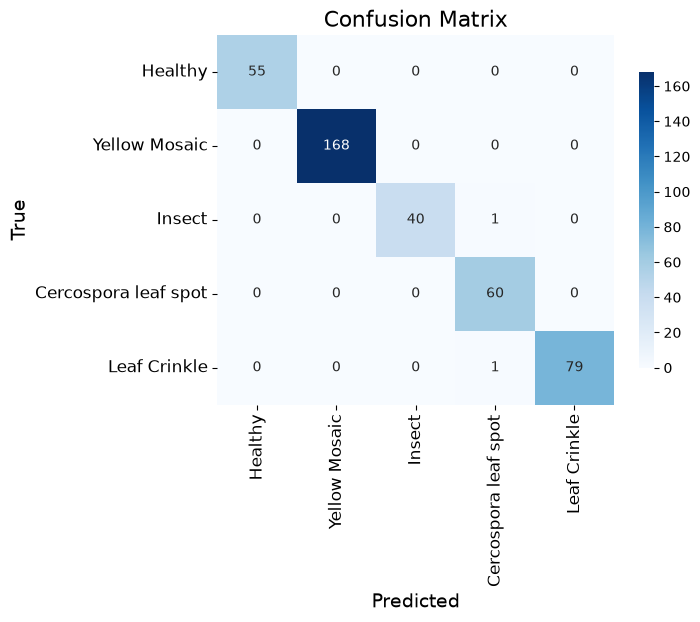

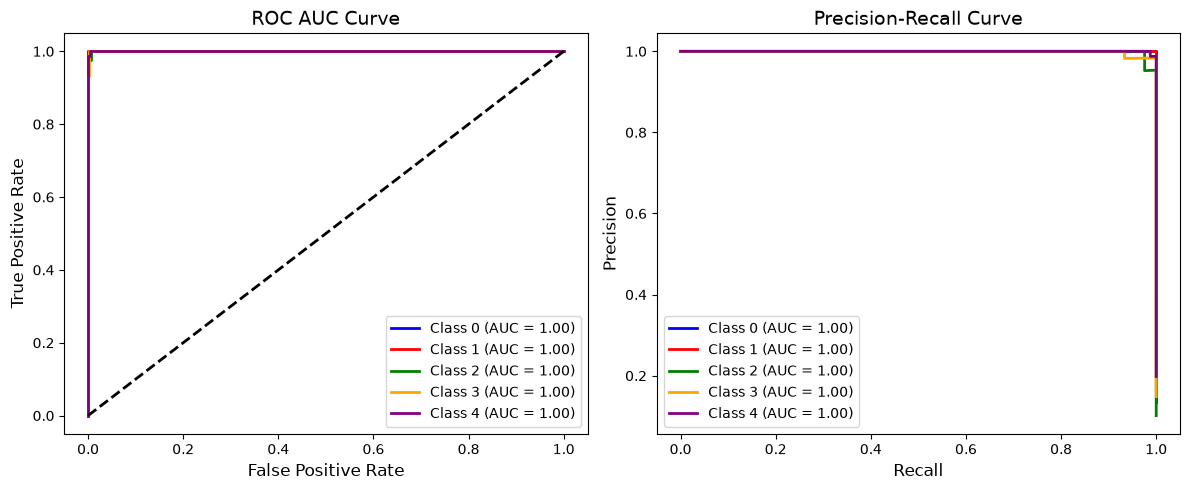

In [21]:
evaluate_model(model, test_loader, label_mapping)

Accuracy: 0.9950
                      precision    recall  f1-score   support

             Healthy       1.00      1.00      1.00        55
       Yellow Mosaic       1.00      0.99      1.00       168
              Insect       1.00      0.98      0.99        41
Cercospora leaf spot       0.98      1.00      0.99        60
        Leaf Crinkle       0.99      1.00      0.99        80

            accuracy                           1.00       404
           macro avg       0.99      0.99      0.99       404
        weighted avg       1.00      1.00      1.00       404



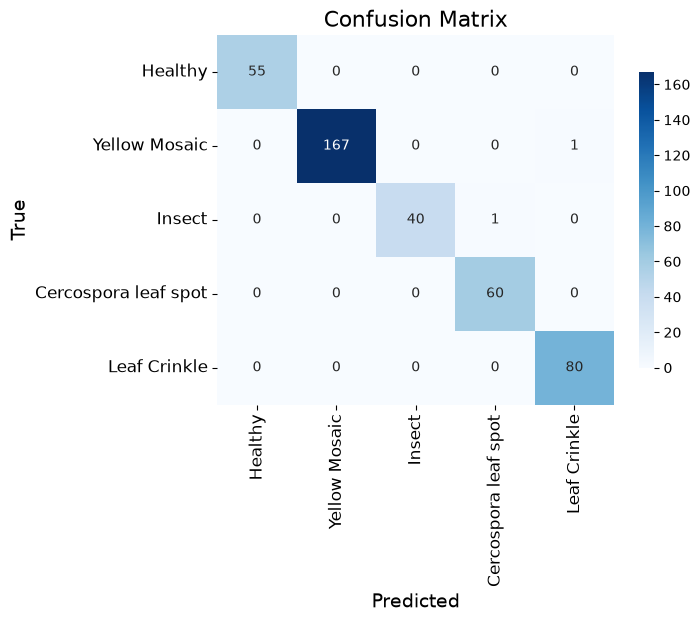

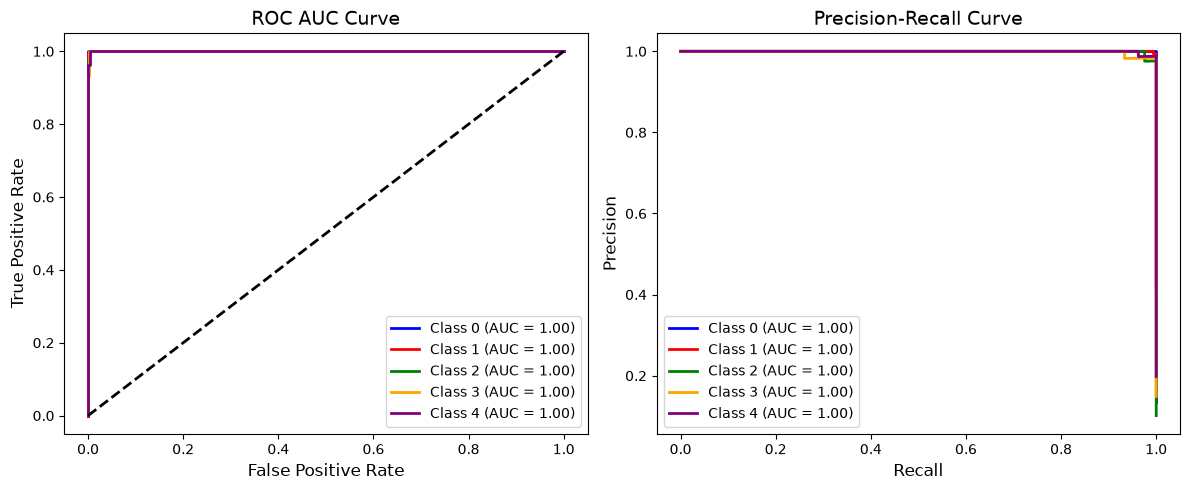

In [47]:
evaluate_model(model, test_loader, label_mapping)

# Baseline Models

In [ ]:
import ssl
import urllib
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import timm

ssl._create_default_https_context = ssl._create_unverified_context

# Target model identification
model_name = 'swinv2_cr_tiny_224'
num_classes = len(label_mapping)

# Create SwinV2 model (Set pretrained=True for massive accuracy gains on small leaf datasets)
model = timm.create_model(model_name, pretrained=False, num_classes=num_classes)

# Modify the head properly according to SwinV2's internal architecture structure
if hasattr(model, 'head') and hasattr(model.head, 'fc'):
    in_features = model.head.fc.in_features
    model.head.fc = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )
elif hasattr(model, 'head') and isinstance(model.head, nn.Linear):
    in_features = model.head.in_features
    model.head = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )

model = model.to(device)

# Loss & optimizer (Kept the same, AdamW is great for Swin architectures)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)

# Scheduler: Cosine Annealing 
scheduler = CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)

# Training execution loop
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)


In [16]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.98020
Recall:      0.98020
Precision:   0.98066
F1 Score:    0.98010
MCC:         0.97327
PR AUC:      0.99623
Kappa:       0.97310
Specificity: 0.99487


In [12]:
import timm

def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)
    
    # Check if the model uses 'classifier' or 'head' as the classification layer
    if hasattr(model, 'classifier'):
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    elif hasattr(model, 'fc'):  # For models like ResNeSt
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    else:
        raise ValueError("Unexpected classifier layer name in model")

    return model


# Number of classes (adjust to your problem)
num_classes = len(label_mapping)  # Replace label_mapping with the actual class labels

# Load EfficientNetV2-M without pre-trained weights
model = load_model("densenet169", num_classes, pretrained=False)

model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
# Define Learning Rate Scheduler (e.g., Cosine Annealing)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20, eta_min=1e-6)


Epoch 1/20
------------------------------


Validation Loss: 0.5040, Validation Accuracy: 0.8342
Training Loss: 0.5322, Training Accuracy: 0.8127

Epoch 2/20
------------------------------


Validation Loss: 0.3978, Validation Accuracy: 0.8465
Training Loss: 0.2930, Training Accuracy: 0.8972

Epoch 3/20
------------------------------


Validation Loss: 0.3989, Validation Accuracy: 0.8490
Training Loss: 0.2493, Training Accuracy: 0.9168
Patience Counter: 1/5

Epoch 4/20
------------------------------


Validation Loss: 0.1140, Validation Accuracy: 0.9653
Training Loss: 0.2014, Training Accuracy: 0.9311

Epoch 5/20
------------------------------


Validation Loss: 0.2188, Validation Accuracy: 0.9233
Training Loss: 0.1574, Training Accuracy: 0.9465
Patience Counter: 1/5

Epoch 6/20
------------------------------


Validation Loss: 1.2208, Validation Accuracy: 0.7426
Training Loss: 0.1350, Training Accuracy: 0.9552
Patience Counter: 2/5

Epoch 7/20
------------------------------


Validation Loss: 0.1196, Validation Accuracy: 0.9554
Training Loss: 0.1239, Training Accuracy: 0.9579
Patience Counter: 3/5

Epoch 8/20
------------------------------


Validation Loss: 0.1653, Validation Accuracy: 0.9455
Training Loss: 0.0967, Training Accuracy: 0.9661
Patience Counter: 4/5

Epoch 9/20
------------------------------


Validation Loss: 0.1413, Validation Accuracy: 0.9604
Training Loss: 0.0951, Training Accuracy: 0.9694
Patience Counter: 5/5
Early stopping triggered at epoch 9.


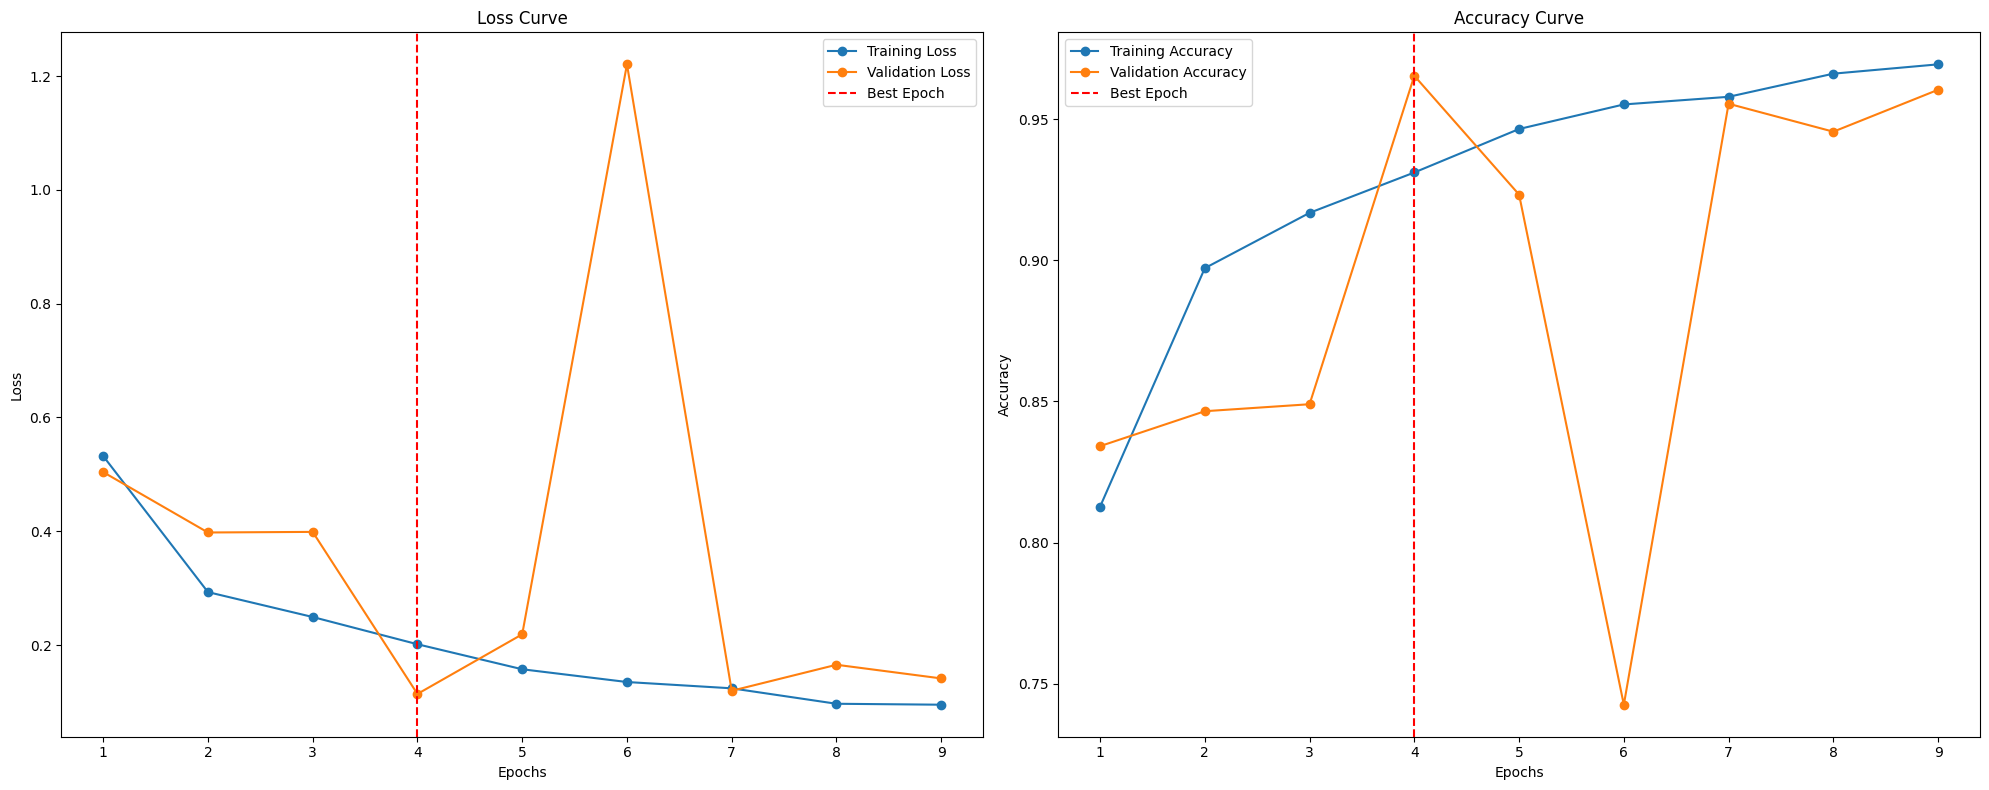


Training Report:
Total training time: 00:08:07
Total epochs run: 9
Best Training Loss: 0.2014 at epoch 4
Best Training Accuracy: 0.9311

Validation Report:
Best Validation Loss: 0.1140 at epoch 4
Best Validation Accuracy: 0.9653
Final Validation Loss: 0.1413
Final Validation Accuracy: 0.9604

Inference Report:
Total Inference Time (Validation only): 00:00:33


In [31]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=20, patience=5, min_delta=0.001)

In [32]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.98020
Recall:      0.98020
Precision:   0.98073
F1 Score:    0.98013
MCC:         0.97321
PR AUC:      0.99786
Kappa:       0.97308
Specificity: 0.99473


In [14]:
torch.cuda.empty_cache()

In [9]:
import ssl, urllib
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import timm

ssl._create_default_https_context = ssl._create_unverified_context

# Create LeViT (pick size: levit_128s / 128 / 192 / 256)
num_classes = len(label_mapping)
model = timm.create_model('efficientvit_m3', pretrained=False, num_classes=num_classes)

if hasattr(model, 'head') and isinstance(model.head, nn.Linear):
    in_features = model.head.in_features
    model.head = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )
    
model = model.to(device)

# Loss & optimizer|
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)

# Scheduler: Cosine Annealing
# T_max = total number of epochs (full cycle)
scheduler = CosineAnnealingLR(optimizer, T_max=20, eta_min=1e-6)



Epoch 1/20
------------------------------


Validation Loss: 0.4605, Validation Accuracy: 0.8193
Training Loss: 0.5241, Training Accuracy: 0.8054

Epoch 2/20
------------------------------


Validation Loss: 0.3693, Validation Accuracy: 0.8639
Training Loss: 0.2583, Training Accuracy: 0.9086

Epoch 3/20
------------------------------


Validation Loss: 0.2838, Validation Accuracy: 0.8960
Training Loss: 0.1745, Training Accuracy: 0.9392

Epoch 4/20
------------------------------


Validation Loss: 0.1373, Validation Accuracy: 0.9505
Training Loss: 0.1166, Training Accuracy: 0.9593

Epoch 5/20
------------------------------


...

Validation Loss: 0.1050, Validation Accuracy: 0.9703
Training Loss: 0.0041, Training Accuracy: 0.9992
Patience Counter: 1/5

Epoch 14/20
------------------------------


Validation Loss: 0.1087, Validation Accuracy: 0.9703
Training Loss: 0.0028, Training Accuracy: 0.9996
Patience Counter: 2/5

Epoch 15/20
------------------------------


Validation Loss: 0.1294, Validation Accuracy: 0.9653
Training Loss: 0.0029, Training Accuracy: 0.9994
Patience Counter: 3/5

Epoch 16/20
------------------------------


Validation Loss: 0.1268, Validation Accuracy: 0.9678
Training Loss: 0.0015, Training Accuracy: 0.9998
Patience Counter: 4/5

Epoch 17/20
------------------------------


Validation Loss: 0.1196, Validation Accuracy: 0.9629
Training Loss: 0.0017, Training Accuracy: 0.9996
Patience Counter: 5/5
Early stopping triggered at epoch 17.


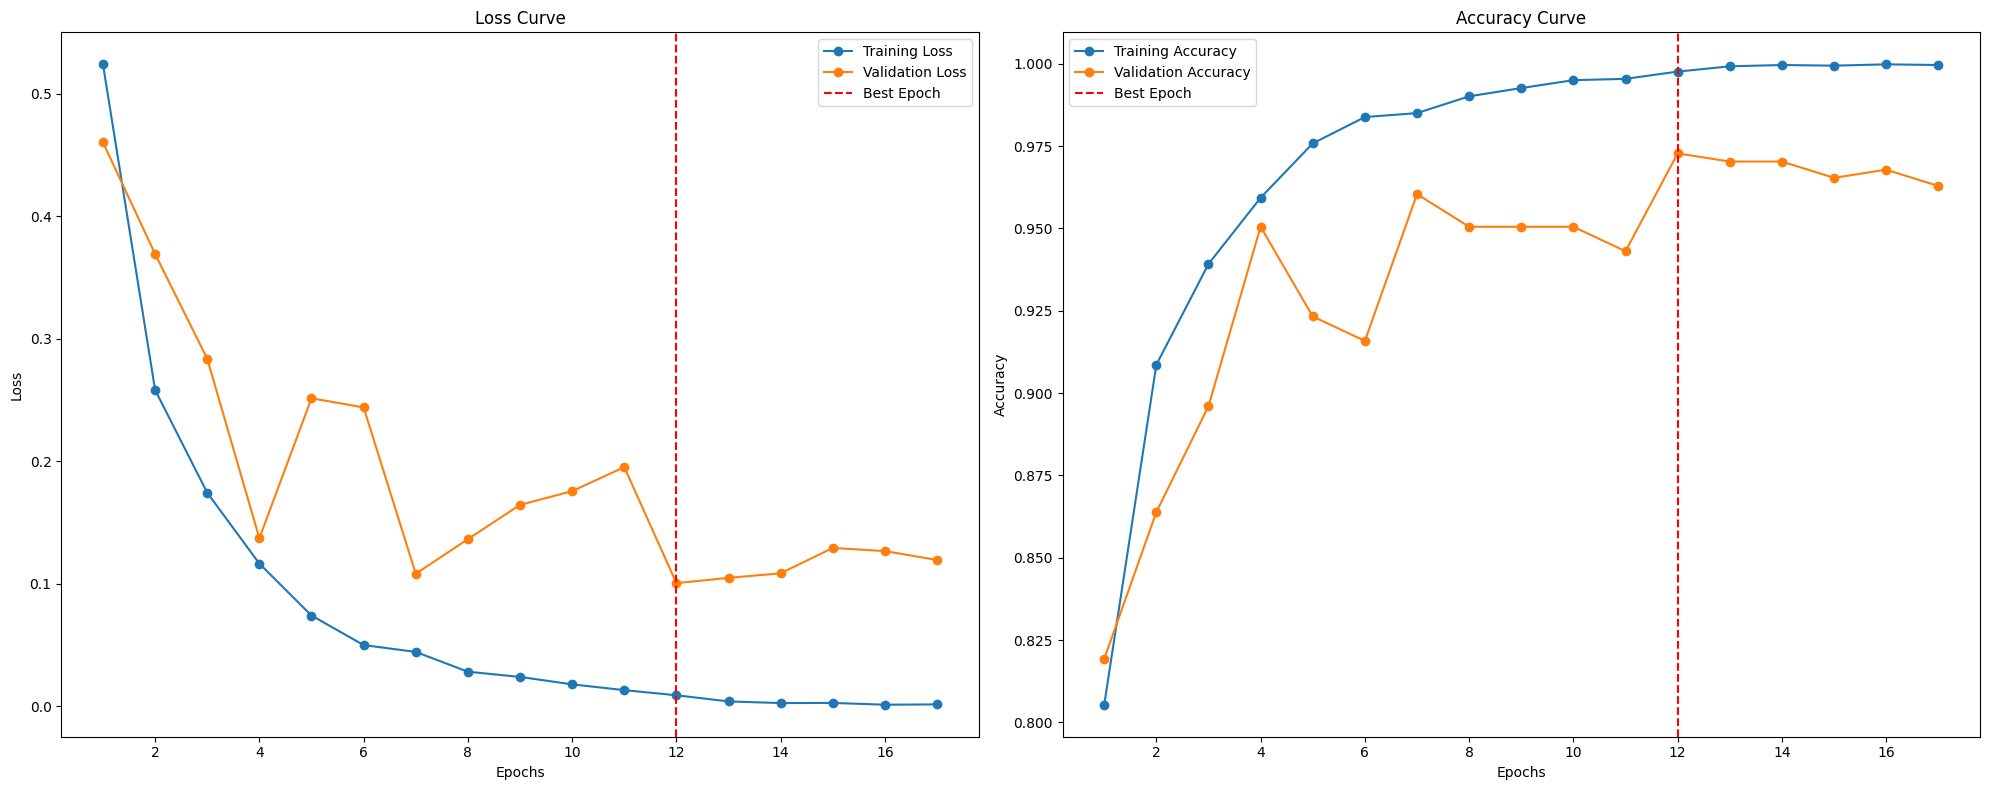


Training Report:
Total training time: 00:08:31
Total epochs run: 17
Best Training Loss: 0.0092 at epoch 12
Best Training Accuracy: 0.9976

Validation Report:
Best Validation Loss: 0.1007 at epoch 12
Best Validation Accuracy: 0.9728
Final Validation Loss: 0.1196
Final Validation Accuracy: 0.9629

Inference Report:
Total Inference Time (Validation only): 00:01:03


In [35]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=20, patience=5, min_delta=0.001)

In [36]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.96040
Recall:      0.96040
Precision:   0.96176
F1 Score:    0.96059
MCC:         0.94669
PR AUC:      0.99130
Kappa:       0.94640
Specificity: 0.99024


In [20]:
torch.cuda.empty_cache()

In [12]:
import timm

def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)
    
    # Check if the model uses 'classifier' or 'head' as the classification layer
    if hasattr(model, 'classifier'):
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    elif hasattr(model, 'fc'):  # For models like ResNeSt
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    else:
        raise ValueError("Unexpected classifier layer name in model")

    return model


# Number of classes (adjust to your problem)
num_classes = len(label_mapping)  # Replace label_mapping with the actual class labels

# Load EfficientNetV2-M without pre-trained weights
model = load_model("resnest50d", num_classes, pretrained=False)

model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
# Define Learning Rate Scheduler (e.g., Cosine Annealing)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)


Epoch 1/30
------------------------------


Validation Loss: 0.6517, Validation Accuracy: 0.7277
Training Loss: 0.6549, Training Accuracy: 0.7588

Epoch 2/30
------------------------------


Validation Loss: 0.6318, Validation Accuracy: 0.7772
Training Loss: 0.3814, Training Accuracy: 0.8734

Epoch 3/30
------------------------------


Validation Loss: 0.3821, Validation Accuracy: 0.8713
Training Loss: 0.3081, Training Accuracy: 0.8895

Epoch 4/30
------------------------------


Validation Loss: 0.1584, Validation Accuracy: 0.9431
Training Loss: 0.2264, Training Accuracy: 0.9214

Epoch 5/30
------------------------------


...

Validation Loss: 0.0549, Validation Accuracy: 0.9777
Training Loss: 0.0444, Training Accuracy: 0.9858
Patience Counter: 1/5

Epoch 20/30
------------------------------


Validation Loss: 0.0624, Validation Accuracy: 0.9777
Training Loss: 0.0464, Training Accuracy: 0.9845
Patience Counter: 2/5

Epoch 21/30
------------------------------


Validation Loss: 0.0490, Validation Accuracy: 0.9827
Training Loss: 0.0334, Training Accuracy: 0.9882
Patience Counter: 3/5

Epoch 22/30
------------------------------


Validation Loss: 0.0605, Validation Accuracy: 0.9827
Training Loss: 0.0361, Training Accuracy: 0.9895
Patience Counter: 4/5

Epoch 23/30
------------------------------


Validation Loss: 0.0494, Validation Accuracy: 0.9876
Training Loss: 0.0254, Training Accuracy: 0.9913
Patience Counter: 5/5
Early stopping triggered at epoch 23.


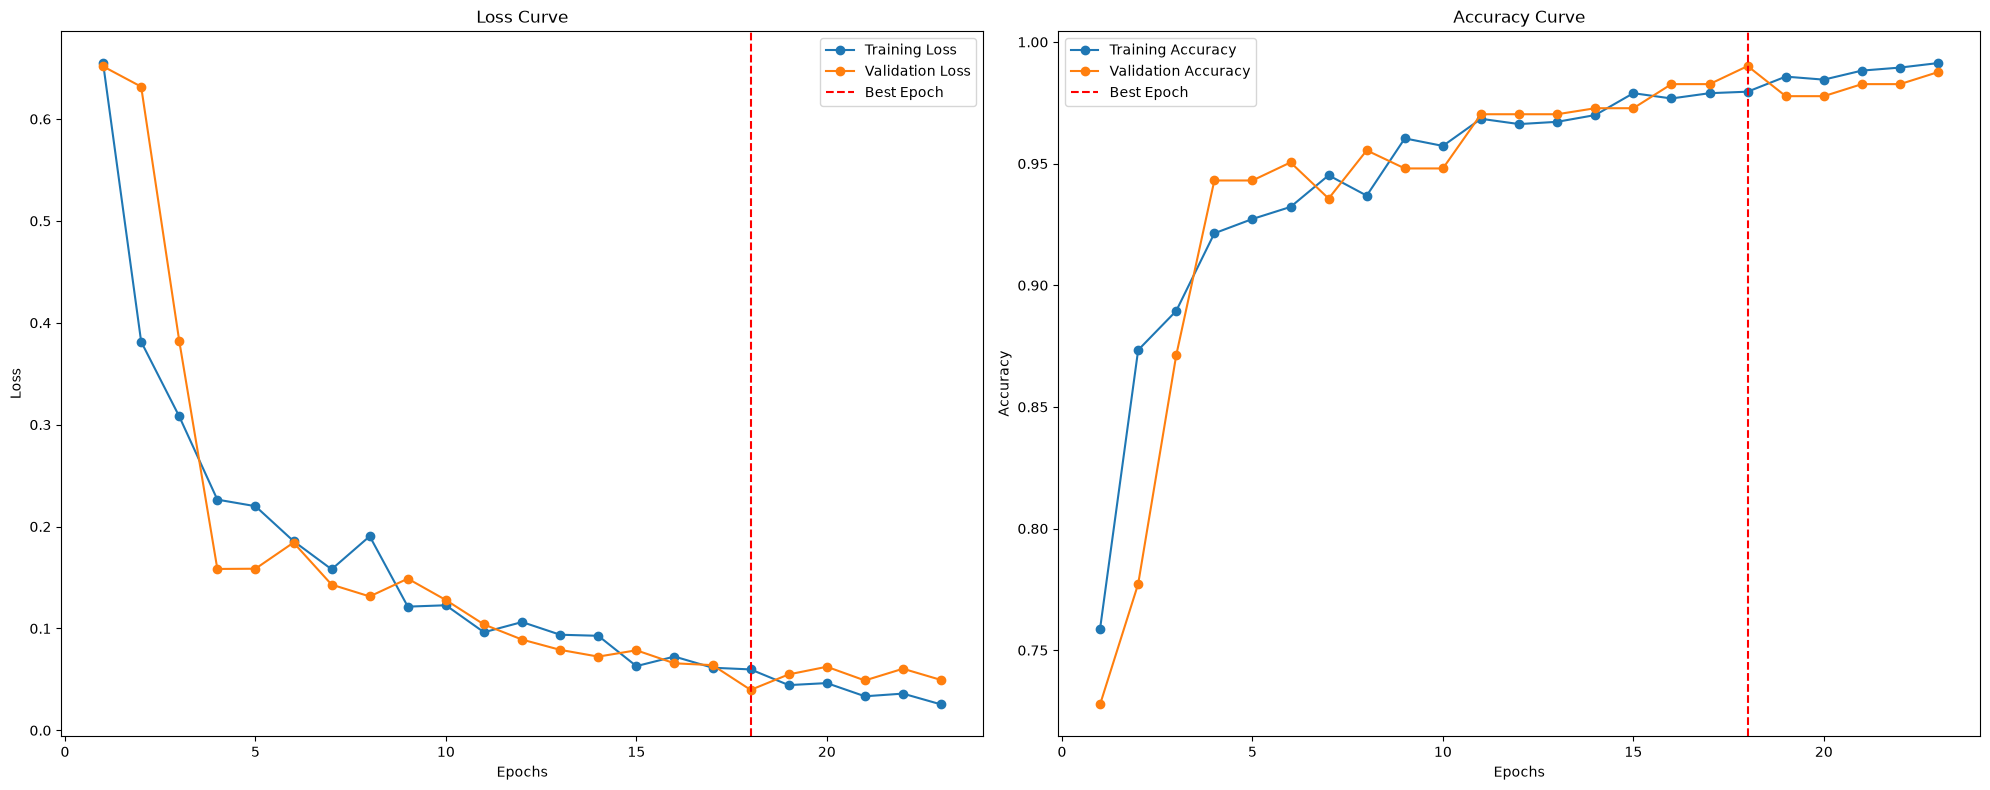


Training Report:
Total training time: 00:11:38
Total epochs run: 23
Best Training Loss: 0.0598 at epoch 18
Best Training Accuracy: 0.9796

Validation Report:
Best Validation Loss: 0.0397 at epoch 18
Best Validation Accuracy: 0.9901
Final Validation Loss: 0.0494
Final Validation Accuracy: 0.9876

Inference Report:
Total Inference Time (Validation only): 00:01:51


In [22]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [23]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.98762
Recall:      0.98762
Precision:   0.98817
F1 Score:    0.98767
MCC:         0.98331
PR AUC:      0.99983
Kappa:       0.98323
Specificity: 0.99716


In [24]:
torch.save(model.state_dict(), "ResnestBean2.pth")

In [9]:
import timm
import torch
import torch.nn as nn

def load_custom_timm_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)
    
    # Get original feature dimension dynamically
    in_features = model.get_classifier().in_features
    
    # Build custom head WITHOUT LogSoftmax
    custom_head = nn.Sequential(
        nn.Linear(in_features, 512),
        nn.BatchNorm1d(512),
        nn.ReLU(),
        nn.Dropout(0.4),
        nn.Linear(512, num_classes)
        # Raw logits output required for CrossEntropyLoss
    )
    
    # Safely assign the custom head using timm's official API
    model.reset_classifier(num_classes=0) # Removes default head
    
    if hasattr(model, 'classifier'):
        model.classifier = custom_head
    elif hasattr(model, 'fc'):
        model.fc = custom_head
    elif hasattr(model, 'head'):
        model.head = custom_head
    else:
        model.reset_classifier(num_classes=num_classes)
        
    return model.to(device)

# Load MobileNetV3-Large 1.0x
model = load_custom_timm_model("mobilenetv4_conv_small", num_classes=len(label_mapping))

# Standard Loss (Outputs raw logits from timm, CrossEntropy handles LogSoftmax internally)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
# Define Learning Rate Scheduler (e.g., Cosine Annealing)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20, eta_min=1e-6)

In [26]:
torch.cuda.empty_cache()


Epoch 1/20
------------------------------


Validation Loss: 0.7205, Validation Accuracy: 0.7203
Training Loss: 0.7690, Training Accuracy: 0.6982

Epoch 2/20
------------------------------


Validation Loss: 0.6063, Validation Accuracy: 0.7847
Training Loss: 0.4581, Training Accuracy: 0.8322

Epoch 3/20
------------------------------


Validation Loss: 0.3227, Validation Accuracy: 0.8713
Training Loss: 0.3434, Training Accuracy: 0.8779

Epoch 4/20
------------------------------


Validation Loss: 0.4861, Validation Accuracy: 0.8416
Training Loss: 0.2735, Training Accuracy: 0.9041
Patience Counter: 1/5

Epoch 5/20
------------------------------


...

Validation Loss: 0.1750, Validation Accuracy: 0.9356
Training Loss: 0.0392, Training Accuracy: 0.9874
Patience Counter: 1/5

Epoch 13/20
------------------------------


Validation Loss: 0.1996, Validation Accuracy: 0.9455
Training Loss: 0.0240, Training Accuracy: 0.9918
Patience Counter: 2/5

Epoch 14/20
------------------------------


Validation Loss: 0.2348, Validation Accuracy: 0.9208
Training Loss: 0.0165, Training Accuracy: 0.9954
Patience Counter: 3/5

Epoch 15/20
------------------------------


Validation Loss: 0.1837, Validation Accuracy: 0.9505
Training Loss: 0.0166, Training Accuracy: 0.9951
Patience Counter: 4/5

Epoch 16/20
------------------------------


Validation Loss: 0.2339, Validation Accuracy: 0.9356
Training Loss: 0.0120, Training Accuracy: 0.9970
Patience Counter: 5/5
Early stopping triggered at epoch 16.


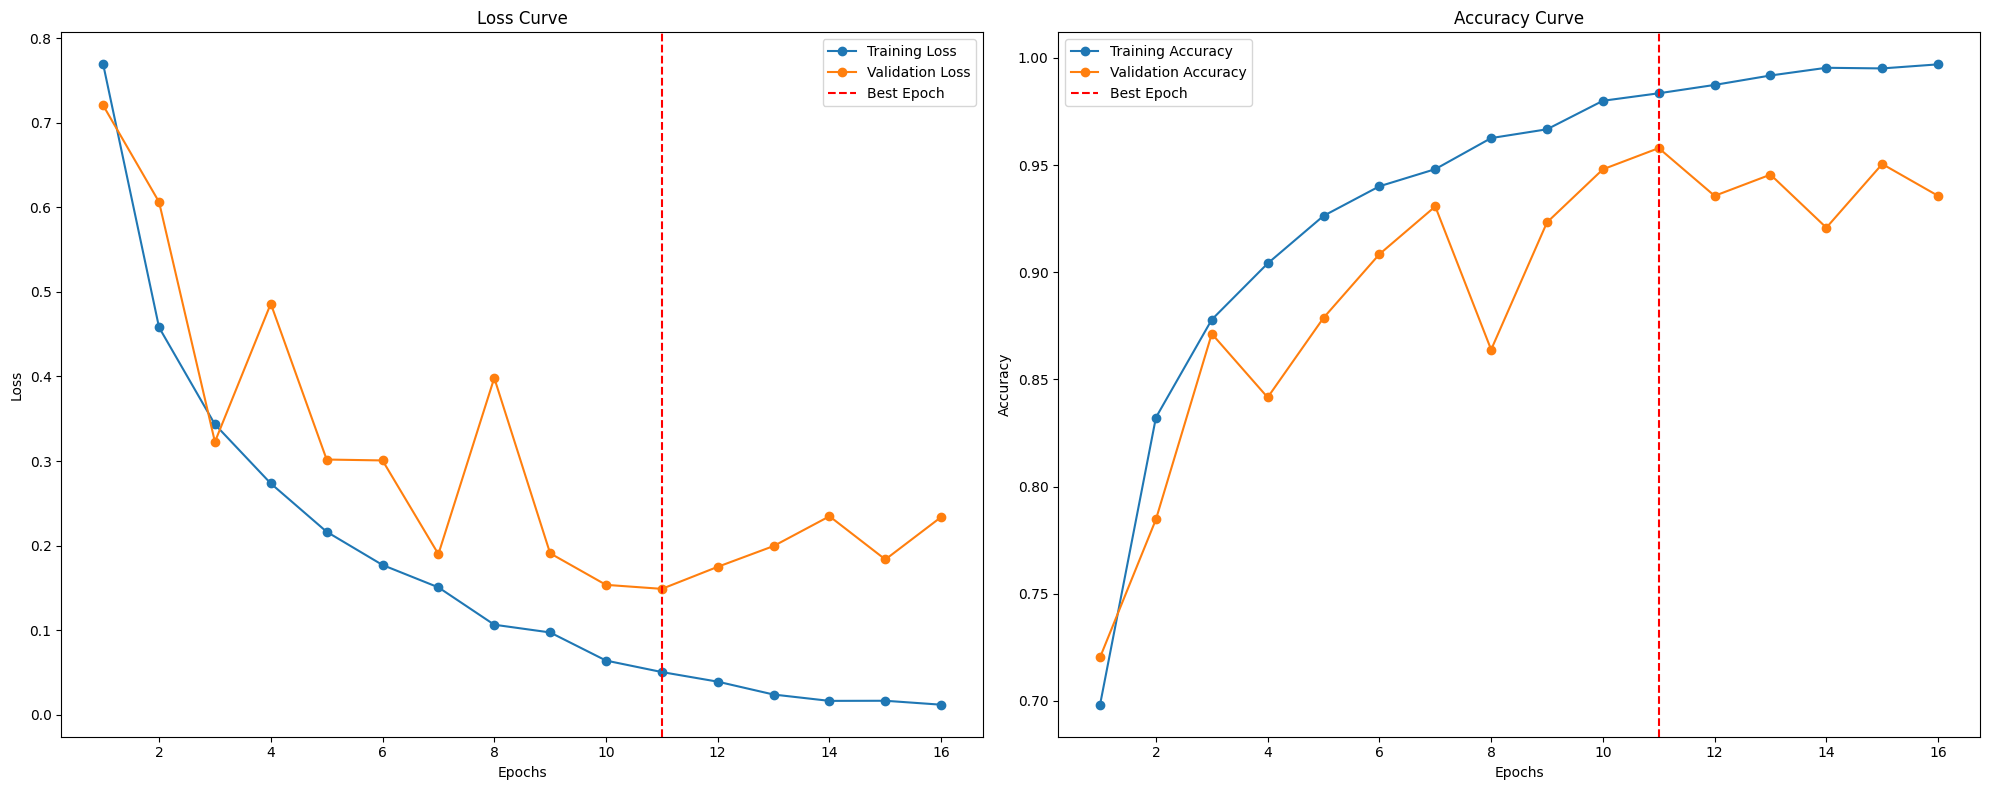


Training Report:
Total training time: 00:07:22
Total epochs run: 16
Best Training Loss: 0.0506 at epoch 11
Best Training Accuracy: 0.9835

Validation Report:
Best Validation Loss: 0.1489 at epoch 11
Best Validation Accuracy: 0.9579
Final Validation Loss: 0.2339
Final Validation Accuracy: 0.9356

Inference Report:
Total Inference Time (Validation only): 00:00:58


In [29]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=20, patience=5, min_delta=0.001)

In [30]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.95792
Recall:      0.95792
Precision:   0.95926
F1 Score:    0.95828
MCC:         0.94330
PR AUC:      0.99420
Kappa:       0.94312
Specificity: 0.98924


In [1]:
import torch
import timm
from fvcore.nn import FlopCountAnalysis

def profile_model(model_name, input_size=(1, 3, 224, 224)):
    """
    Calculates total parameters and GFLOPs for a given timm model name.
    """
    # 1. Initialize model in evaluation mode
    model = timm.create_model(model_name, pretrained=False)
    model.eval()
    
    # 2. Count parameters using native PyTorch
    # Total parameters (including non-trainable ones)
    total_params = sum(p.numel() for p in model.parameters())
    # Trainable parameters only
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    # 3. Create dummy input tensor matching the specified size
    dummy_input = torch.randn(*input_size)
    
    # 4. Calculate FLOPs using fvcore
    flop_analyzer = FlopCountAnalysis(model, dummy_input)
    # Turn off warnings for unsupported operators (like some custom activations)
    flop_analyzer.unsupported_ops_warnings(False) 
    
    total_flops = flop_analyzer.total()
    gflops = total_flops / 1e9 # Convert to GigaFLOPs
    
    # 5. Format outputs for easier reading
    print(f"=== Profile Report for: {model_name} ===")
    print(f"Total Parameters     : {total_params:,} ({total_params / 1e6:.2f} M)")
    print(f"Trainable Parameters : {trainable_params:,} ({trainable_params / 1e6:.2f} M)")
    print(f"Computational Complexity: {gflops:.3f} GFLOPs")
    print("=" * (24 + len(model_name)))
    print()
    
    return {
        "model_name": model_name,
        "params_m": total_params / 1e6,
        "gflops": gflops
    }

# --- Execution Example ---
if __name__ == "__main__":
    # Test it out on a hybrid model
    profile_model('resnest50d')  # Example: ResNet-50 variant
        
        # Test it out on an efficient pure CNN
    profile_model('densenet169')
    
    profile_model('mobilenetv4_conv_small')
    
    profile_model('swinv2_cr_tiny_224')
    
    profile_model('efficientvit_m3')


=== Profile Report for: resnest50d ===
Total Parameters     : 27,483,240 (27.48 M)
Trainable Parameters : 27,483,240 (27.48 M)
Computational Complexity: 5.400 GFLOPs

=== Profile Report for: densenet169 ===
Total Parameters     : 14,149,480 (14.15 M)
Trainable Parameters : 14,149,480 (14.15 M)
Computational Complexity: 3.398 GFLOPs

=== Profile Report for: mobilenetv4_conv_small ===
Total Parameters     : 3,774,024 (3.77 M)
Trainable Parameters : 3,774,024 (3.77 M)
Computational Complexity: 0.190 GFLOPs

=== Profile Report for: swinv2_cr_tiny_224 ===
Total Parameters     : 28,332,124 (28.33 M)
Trainable Parameters : 28,332,124 (28.33 M)
Computational Complexity: 4.659 GFLOPs

=== Profile Report for: efficientvit_m3 ===
Total Parameters     : 6,900,722 (6.90 M)
Trainable Parameters : 6,900,722 (6.90 M)
Computational Complexity: 0.266 GFLOPs



In [60]:
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score,
    matthews_corrcoef, average_precision_score, cohen_kappa_score, confusion_matrix
)
from sklearn.preprocessing import label_binarize
import numpy as np
import torch

def evaluate_model_with_metrics(model, dataloader):
    model.eval()
    all_labels, all_preds, all_probs = [], [], []
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            probs = torch.softmax(outputs, dim=1)
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    accuracy = accuracy_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    mcc = matthews_corrcoef(all_labels, all_preds)

    # PR AUC: needs one-hot labels for multiclass, otherwise this always
    # throws and silently returns NaN
    num_classes = all_probs.shape[1]
    try:
        if num_classes == 2:
            pr_auc = average_precision_score(all_labels, all_probs[:, 1])
        else:
            labels_bin = label_binarize(all_labels, classes=np.arange(num_classes))
            pr_auc = average_precision_score(labels_bin, all_probs, average="weighted")
    except ValueError:
        pr_auc = float('nan')

    kappa = cohen_kappa_score(all_labels, all_preds)

    cm = confusion_matrix(all_labels, all_preds)
    TN, FP = [], []
    for i in range(len(cm)):
        tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
        fp = cm[:, i].sum() - cm[i, i]
        TN.append(tn)
        FP.append(fp)
    specificity_per_class = [TN[i] / (TN[i] + FP[i]) if (TN[i] + FP[i]) > 0 else 0 for i in range(len(cm))]
    specificity = np.average(specificity_per_class)

    print(f"Accuracy:    {accuracy:.5f}")
    print(f"Recall:      {recall:.5f}")
    print(f"Precision:   {precision:.5f}")
    print(f"F1 Score:    {f1:.5f}")
    print(f"MCC:         {mcc:.5f}")
    print(f"PR AUC:      {pr_auc:.5f}")
    print(f"Kappa:       {kappa:.5f}")
    print(f"Specificity: {specificity:.5f}")

    return {
        "accuracy": accuracy,
        "recall": recall,
        "precision": precision,
        "f1": f1,
        "mcc": mcc,
        "pr_auc": pr_auc,
        "kappa": kappa,
        "specificity": specificity,
    }

In [71]:
import torch
from fvcore.nn import FlopCountAnalysis


def profile_model(model, model_name: str, input_size=(1, 3, 224, 224)):
    """
    Calculates total parameters and GFLOPs for any nn.Module.
    Model must return a single tensor in eval mode (no tuple outputs).
    """
    model.eval()
    # Parameters
    total_params     = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    # GFLOPs via fvcore — eval mode ensures single-tensor forward
    dummy_input  = torch.randn(*input_size)
    flop_counter = FlopCountAnalysis(model, dummy_input)
    flop_counter.unsupported_ops_warnings(False)    # suppress softmax/GELU warnings
    flop_counter.uncalled_modules_warnings(False)    # suppress unused-submodule warnings
    gflops = flop_counter.total() / 1e9

    print(f"=== Profile Report for: {model_name} ===")
    print(f"Total Parameters        : {total_params:,} ({total_params / 1e6:.2f} M)")
    print(f"Trainable Parameters    : {trainable_params:,} ({trainable_params / 1e6:.2f} M)")
    print(f"Computational Complexity: {gflops:.3f} GFLOPs")
    print("=" * (24 + len(model_name)))
    print()

    return {
        "model_name": model_name,
        "params_m": total_params / 1e6,
        "trainable_params_m": trainable_params / 1e6,
        "gflops": gflops,
    }


if __name__ == "__main__":
    results = []

    lbf_model = LightBeanFormer(num_classes=5)
    results.append(profile_model(lbf_model, "LightBeanFormer"))


=== Profile Report for: LightBeanFormer ===
Total Parameters        : 4,264,569 (4.26 M)
Trainable Parameters    : 4,264,569 (4.26 M)
Computational Complexity: 0.629 GFLOPs



# CV results

Full dataset: 4038 images across 5 classes
Running 5-fold CV on the entire dataset (no held-out test set)

FOLD 1/5  (train=3230, val=808)

Processing class: Cercospora leaf spot
Original images saved: 478


 79%|███████████████████████████████████████████████████████████████▌                | 380/478 [00:09<00:02, 38.74it/s]


Augmented images created: 1522
Total images in class 'Cercospora leaf spot': 2000

Processing class: Healthy
Original images saved: 436


 89%|███████████████████████████████████████████████████████████████████████▌        | 390/436 [00:09<00:01, 40.19it/s]


Augmented images created: 1564
Total images in class 'Healthy': 2000

Processing class: Insect
Original images saved: 326


...

Validation Loss: 0.4671, Validation Accuracy: 0.9666
Training Loss: 0.4291, Training Accuracy: 0.9857
Patience Counter: 1/5

Epoch 10/30
------------------------------


Validation Loss: 0.5273, Validation Accuracy: 0.9369
Training Loss: 0.4212, Training Accuracy: 0.9892
Patience Counter: 2/5

Epoch 11/30
------------------------------


Validation Loss: 0.4509, Validation Accuracy: 0.9728
Training Loss: 0.4163, Training Accuracy: 0.9921
Patience Counter: 3/5

Epoch 12/30
------------------------------


Validation Loss: 0.5583, Validation Accuracy: 0.9381
Training Loss: 0.4121, Training Accuracy: 0.9933
Patience Counter: 4/5

Epoch 13/30
------------------------------


Validation Loss: 0.4519, Validation Accuracy: 0.9740
Training Loss: 0.4067, Training Accuracy: 0.9957
Patience Counter: 5/5
Early stopping triggered at epoch 13.


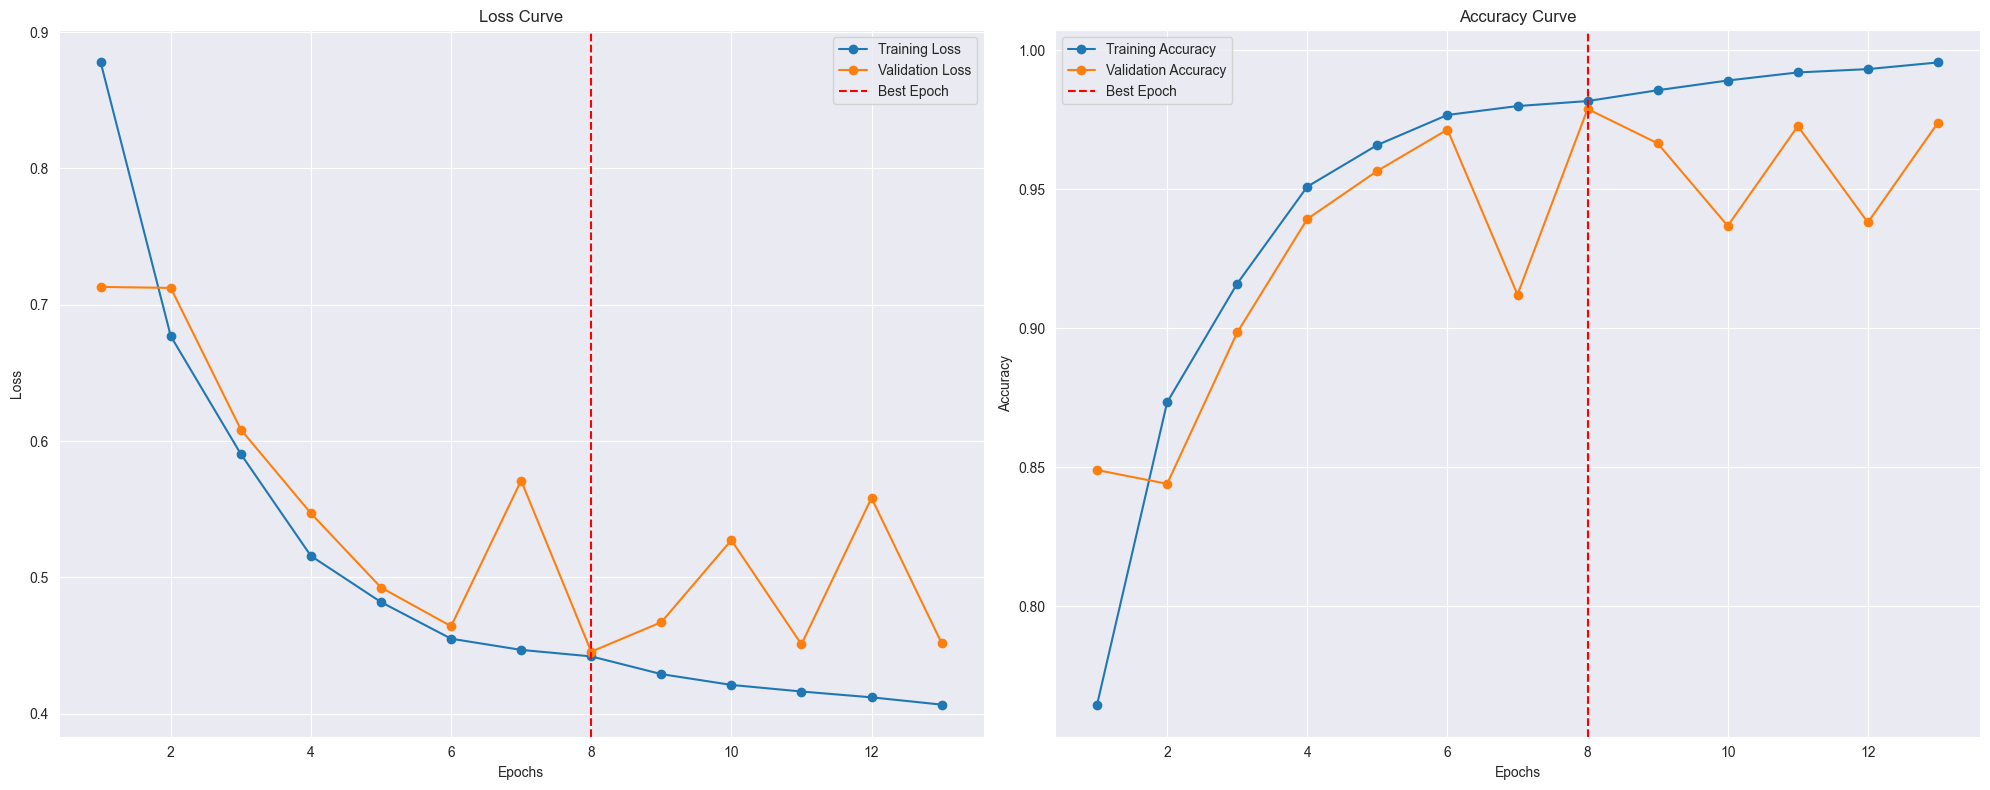


Training Report:
Total training time: 00:10:53
Total epochs run: 13
Best Training Loss: 0.4421 at epoch 8
Best Training Accuracy: 0.9818

Validation Report:
Best Validation Loss: 0.4455 at epoch 8
Best Validation Accuracy: 0.9790
Final Validation Loss: 0.4519
Final Validation Accuracy: 0.9740

Inference Report:
Total Inference Time (Validation only): 00:00:58
Accuracy:    0.97649
Recall:      0.97649
Precision:   0.97691
F1 Score:    0.97641
MCC:         0.96824
PR AUC:      0.98511
Kappa:       0.96811
Specificity: 0.99401
Saved fold 1 checkpoint -> model_fold1.pth

FOLD 2/5  (train=3230, val=808)

Processing class: Cercospora leaf spot
Original images saved: 478


 79%|███████████████████████████████████████████████████████████████▌                | 380/478 [00:08<00:02, 45.14it/s]


Augmented images created: 1522
Total images in class 'Cercospora leaf spot': 2000

Processing class: Healthy
Original images saved: 436


 89%|███████████████████████████████████████████████████████████████████████▌        | 390/436 [00:08<00:01, 45.63it/s]


Augmented images created: 1564
Total images in class 'Healthy': 2000

Processing class: Insect
Original images saved: 327


...

Validation Loss: 0.4273, Validation Accuracy: 0.9814
Training Loss: 0.3933, Training Accuracy: 0.9994
Patience Counter: 1/5

Epoch 21/30
------------------------------


Validation Loss: 0.4217, Validation Accuracy: 0.9851
Training Loss: 0.3927, Training Accuracy: 0.9998
Patience Counter: 2/5

Epoch 22/30
------------------------------


Validation Loss: 0.4158, Validation Accuracy: 0.9876
Training Loss: 0.3955, Training Accuracy: 0.9983
Patience Counter: 3/5

Epoch 23/30
------------------------------


Validation Loss: 0.4186, Validation Accuracy: 0.9864
Training Loss: 0.3930, Training Accuracy: 0.9998
Patience Counter: 4/5

Epoch 24/30
------------------------------


Validation Loss: 0.4144, Validation Accuracy: 0.9889
Training Loss: 0.3923, Training Accuracy: 0.9999
Patience Counter: 5/5
Early stopping triggered at epoch 24.


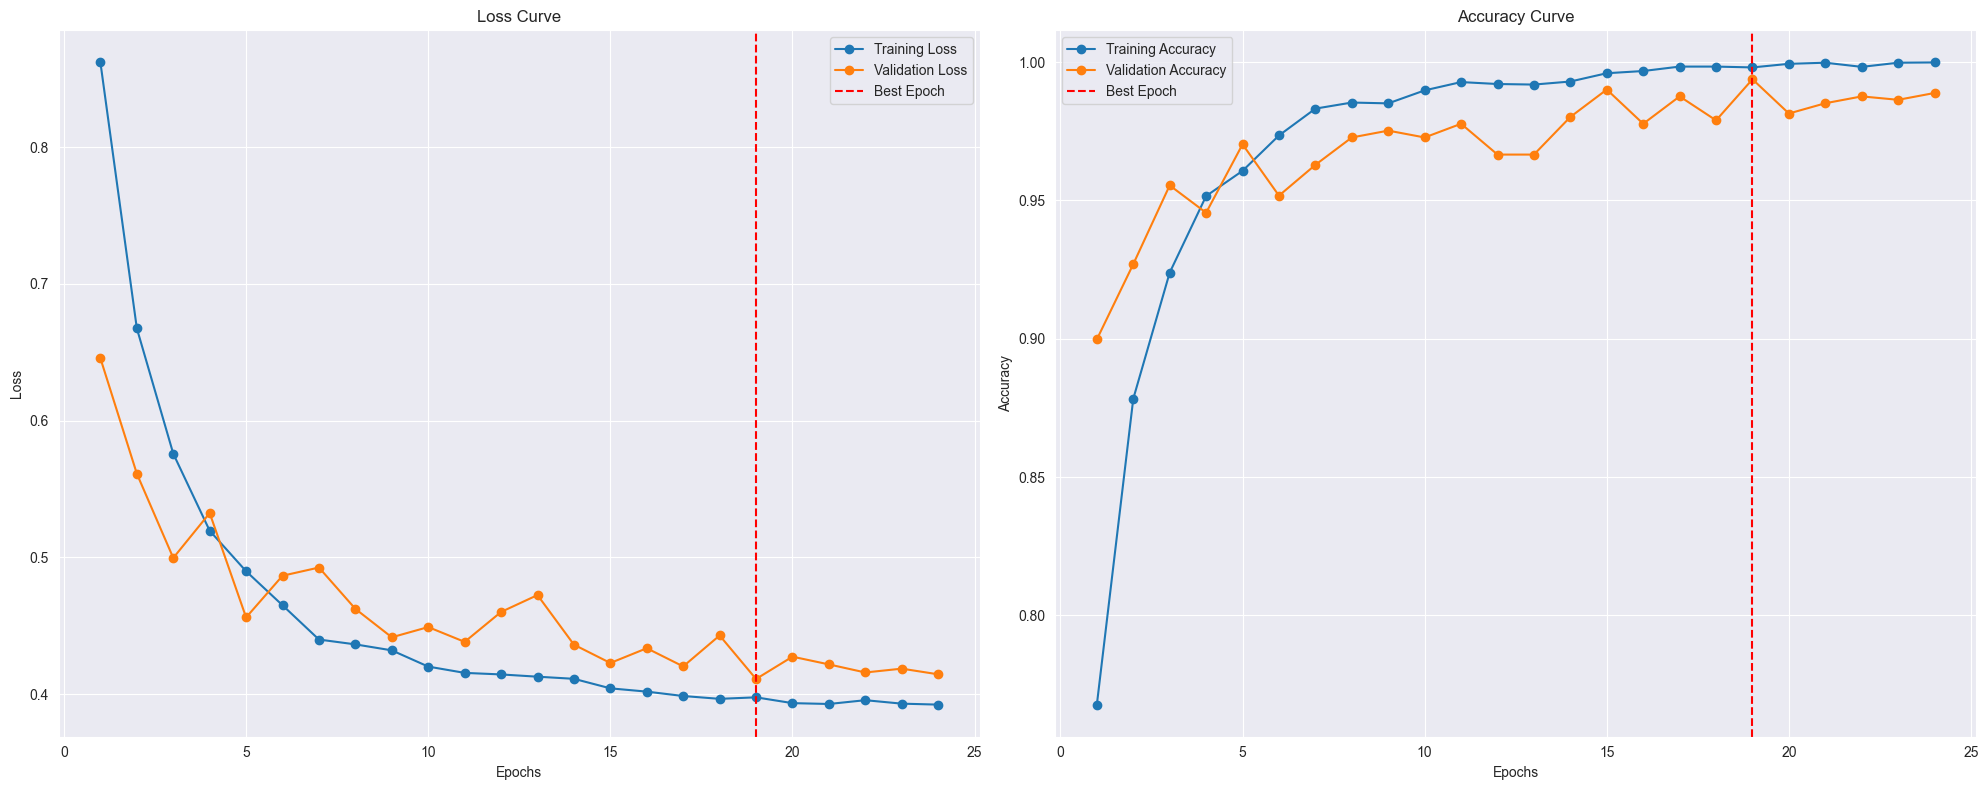


Training Report:
Total training time: 00:19:39
Total epochs run: 24
Best Training Loss: 0.3976 at epoch 19
Best Training Accuracy: 0.9981

Validation Report:
Best Validation Loss: 0.4110 at epoch 19
Best Validation Accuracy: 0.9938
Final Validation Loss: 0.4144
Final Validation Accuracy: 0.9889

Inference Report:
Total Inference Time (Validation only): 00:01:44
Accuracy:    0.98886
Recall:      0.98886
Precision:   0.98892
F1 Score:    0.98886
MCC:         0.98491
PR AUC:      0.99909
Kappa:       0.98490
Specificity: 0.99723
Saved fold 2 checkpoint -> model_fold2.pth

FOLD 3/5  (train=3230, val=808)

Processing class: Cercospora leaf spot
Original images saved: 478


 79%|███████████████████████████████████████████████████████████████▌                | 380/478 [00:08<00:02, 46.09it/s]


Augmented images created: 1522
Total images in class 'Cercospora leaf spot': 2000

Processing class: Healthy
Original images saved: 436


 89%|███████████████████████████████████████████████████████████████████████▌        | 390/436 [00:08<00:00, 46.53it/s]


Augmented images created: 1564
Total images in class 'Healthy': 2000

Processing class: Insect
Original images saved: 327


...

Validation Loss: 0.4669, Validation Accuracy: 0.9653
Training Loss: 0.4179, Training Accuracy: 0.9907
Patience Counter: 1/5

Epoch 12/30
------------------------------


Validation Loss: 0.4615, Validation Accuracy: 0.9715
Training Loss: 0.4192, Training Accuracy: 0.9899
Patience Counter: 2/5

Epoch 13/30
------------------------------


Validation Loss: 0.4719, Validation Accuracy: 0.9653
Training Loss: 0.4164, Training Accuracy: 0.9920
Patience Counter: 3/5

Epoch 14/30
------------------------------


Validation Loss: 0.4970, Validation Accuracy: 0.9517
Training Loss: 0.4062, Training Accuracy: 0.9953
Patience Counter: 4/5

Epoch 15/30
------------------------------


Validation Loss: 0.4336, Validation Accuracy: 0.9802
Training Loss: 0.4019, Training Accuracy: 0.9973
Patience Counter: 5/5
Early stopping triggered at epoch 15.


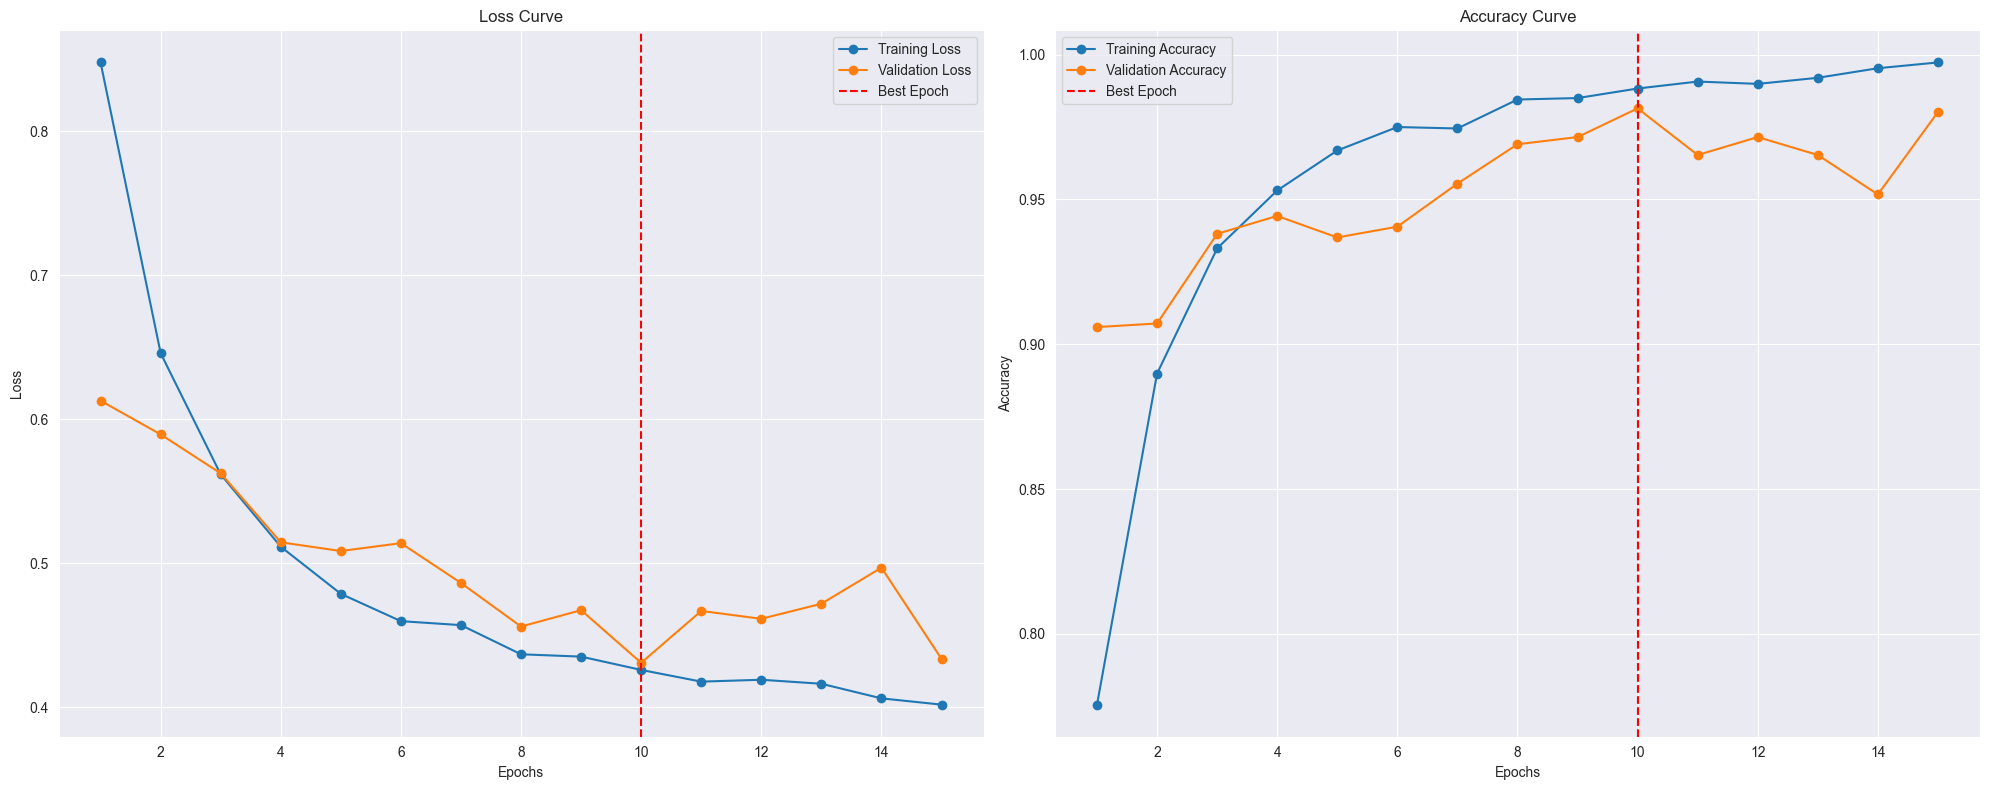


Training Report:
Total training time: 00:12:21
Total epochs run: 15
Best Training Loss: 0.4260 at epoch 10
Best Training Accuracy: 0.9883

Validation Report:
Best Validation Loss: 0.4309 at epoch 10
Best Validation Accuracy: 0.9814
Final Validation Loss: 0.4336
Final Validation Accuracy: 0.9802

Inference Report:
Total Inference Time (Validation only): 00:01:07
Accuracy:    0.98020
Recall:      0.98020
Precision:   0.98088
F1 Score:    0.98031
MCC:         0.97320
PR AUC:      0.99670
Kappa:       0.97310
Specificity: 0.99495
Saved fold 3 checkpoint -> model_fold3.pth

FOLD 4/5  (train=3231, val=807)

Processing class: Cercospora leaf spot
Original images saved: 479


 79%|███████████████████████████████████████████████████████████████▍                | 380/479 [00:08<00:02, 46.20it/s]


Augmented images created: 1521
Total images in class 'Cercospora leaf spot': 2000

Processing class: Healthy
Original images saved: 436


 89%|███████████████████████████████████████████████████████████████████████▌        | 390/436 [00:08<00:00, 46.25it/s]


Augmented images created: 1564
Total images in class 'Healthy': 2000

Processing class: Insect
Original images saved: 326


...

Validation Loss: 0.3997, Validation Accuracy: 0.9963
Training Loss: 0.3919, Training Accuracy: 1.0000

Epoch 27/30
------------------------------


Validation Loss: 0.3991, Validation Accuracy: 0.9950
Training Loss: 0.3920, Training Accuracy: 0.9997
Patience Counter: 1/5

Epoch 28/30
------------------------------


Validation Loss: 0.3986, Validation Accuracy: 0.9950
Training Loss: 0.3916, Training Accuracy: 1.0000

Epoch 29/30
------------------------------


Validation Loss: 0.3997, Validation Accuracy: 0.9950
Training Loss: 0.3915, Training Accuracy: 1.0000
Patience Counter: 1/5

Epoch 30/30
------------------------------


Validation Loss: 0.3999, Validation Accuracy: 0.9950
Training Loss: 0.3920, Training Accuracy: 0.9996
Patience Counter: 2/5


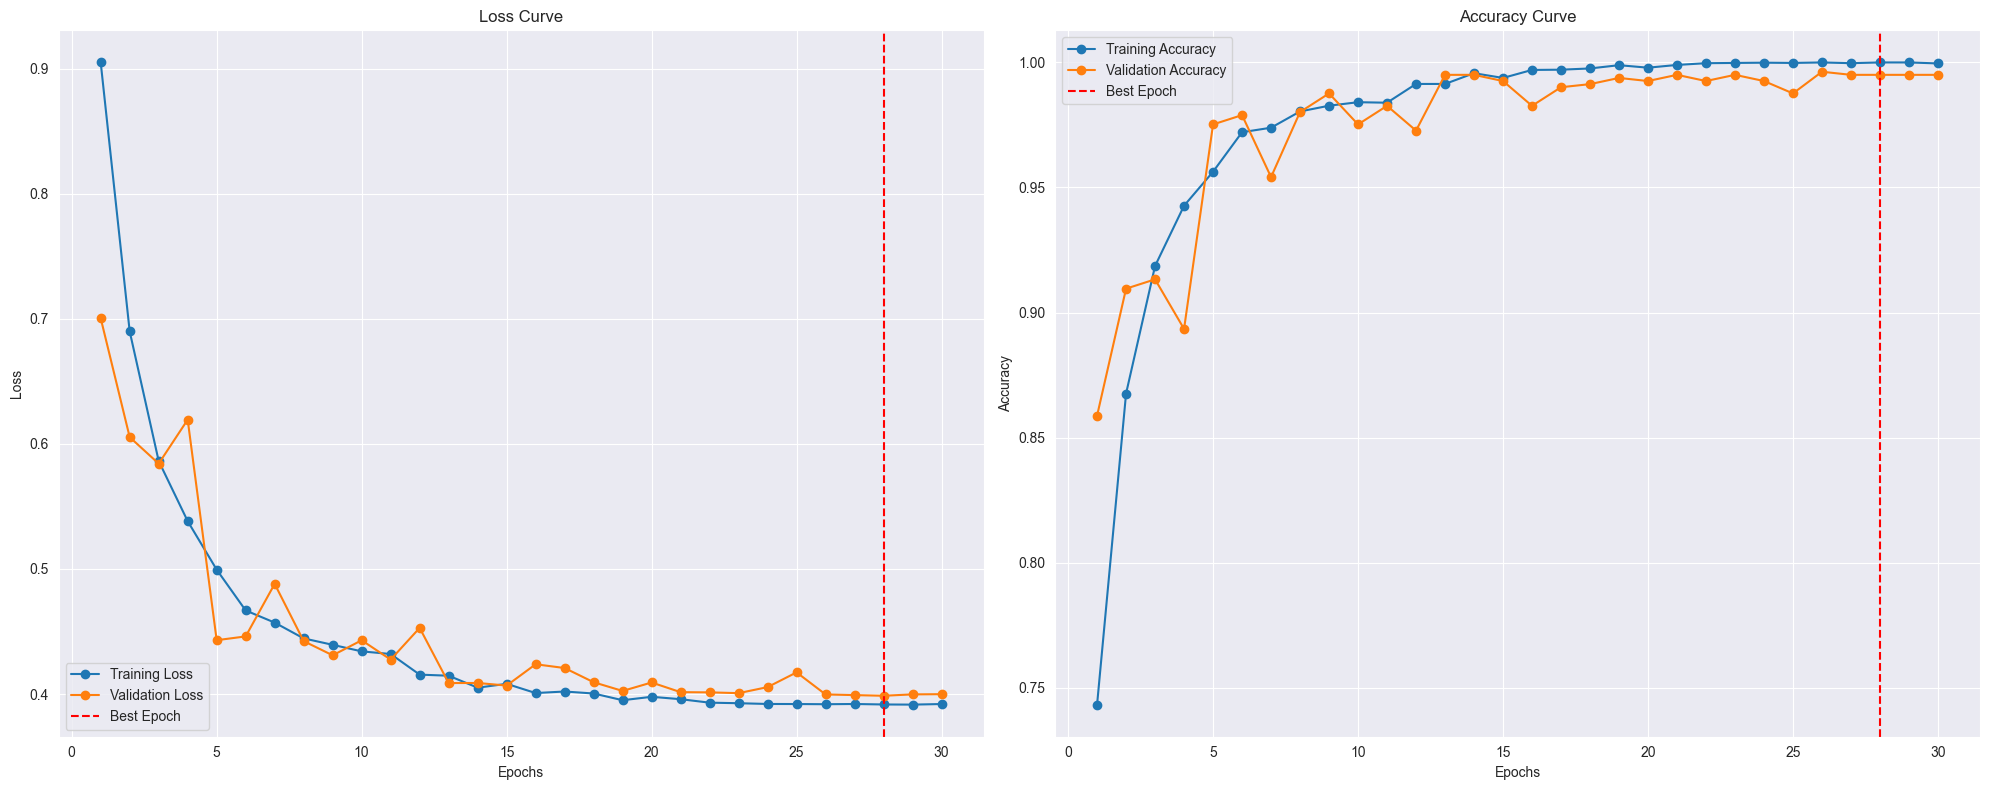


Training Report:
Total training time: 00:24:34
Total epochs run: 30
Best Training Loss: 0.3916 at epoch 28
Best Training Accuracy: 1.0000

Validation Report:
Best Validation Loss: 0.3986 at epoch 28
Best Validation Accuracy: 0.9950
Final Validation Loss: 0.3999
Final Validation Accuracy: 0.9950

Inference Report:
Total Inference Time (Validation only): 00:02:14
Accuracy:    0.99504
Recall:      0.99504
Precision:   0.99508
F1 Score:    0.99504
MCC:         0.99328
PR AUC:      0.99988
Kappa:       0.99327
Specificity: 0.99873
Saved fold 4 checkpoint -> model_fold4.pth

FOLD 5/5  (train=3231, val=807)

Processing class: Cercospora leaf spot
Original images saved: 479


 79%|███████████████████████████████████████████████████████████████▍                | 380/479 [00:08<00:02, 47.20it/s]


Augmented images created: 1521
Total images in class 'Cercospora leaf spot': 2000

Processing class: Healthy
Original images saved: 436


 89%|███████████████████████████████████████████████████████████████████████▌        | 390/436 [00:08<00:00, 46.44it/s]


Augmented images created: 1564
Total images in class 'Healthy': 2000

Processing class: Insect
Original images saved: 326


...

Validation Loss: 0.4162, Validation Accuracy: 0.9888
Training Loss: 0.3937, Training Accuracy: 0.9993
Patience Counter: 1/5

Epoch 23/30
------------------------------


Validation Loss: 0.4190, Validation Accuracy: 0.9864
Training Loss: 0.3950, Training Accuracy: 0.9985
Patience Counter: 2/5

Epoch 24/30
------------------------------


Validation Loss: 0.4256, Validation Accuracy: 0.9851
Training Loss: 0.3922, Training Accuracy: 0.9999
Patience Counter: 3/5

Epoch 25/30
------------------------------


Validation Loss: 0.4249, Validation Accuracy: 0.9851
Training Loss: 0.3917, Training Accuracy: 1.0000
Patience Counter: 4/5

Epoch 26/30
------------------------------


Validation Loss: 0.4241, Validation Accuracy: 0.9839
Training Loss: 0.3917, Training Accuracy: 0.9999
Patience Counter: 5/5
Early stopping triggered at epoch 26.


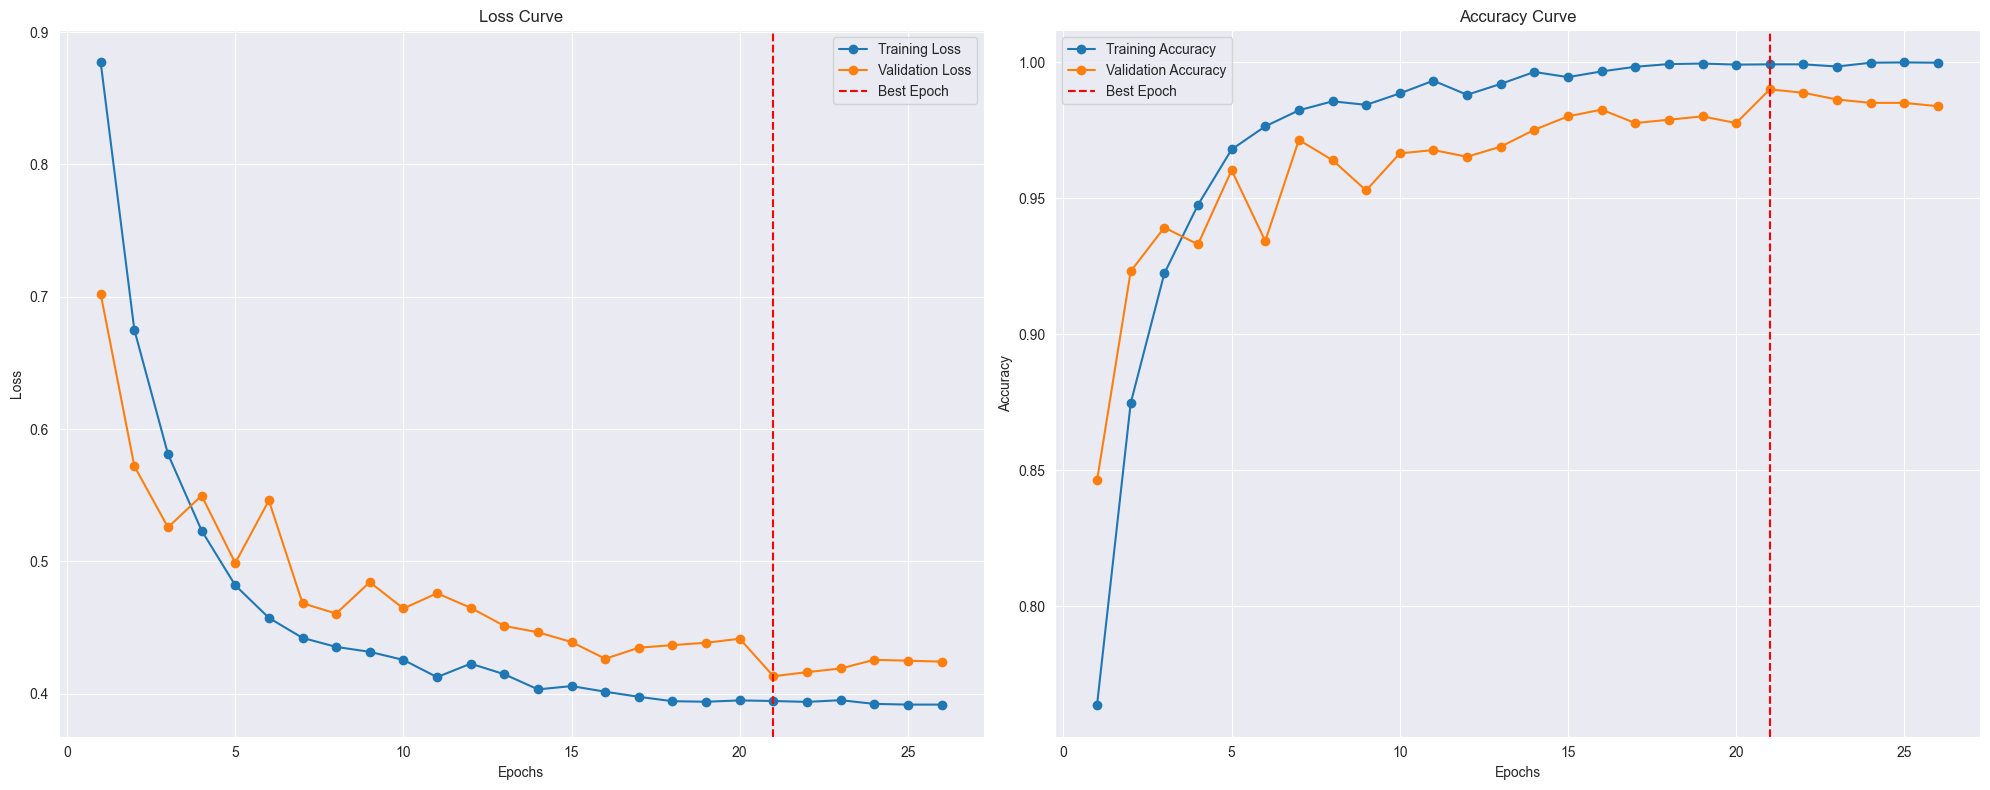


Training Report:
Total training time: 00:20:58
Total epochs run: 26
Best Training Loss: 0.3944 at epoch 21
Best Training Accuracy: 0.9993

Validation Report:
Best Validation Loss: 0.4131 at epoch 21
Best Validation Accuracy: 0.9901
Final Validation Loss: 0.4241
Final Validation Accuracy: 0.9839

Inference Report:
Total Inference Time (Validation only): 00:01:53
Accuracy:    0.98389
Recall:      0.98389
Precision:   0.98394
F1 Score:    0.98390
MCC:         0.97814
PR AUC:      0.99809
Kappa:       0.97814
Specificity: 0.99602
Saved fold 5 checkpoint -> model_fold5.pth

Per-fold results:
      accuracy  recall  precision      f1     mcc  pr_auc   kappa  specificity
fold                                                                          
1       0.9765  0.9765     0.9769  0.9764  0.9682  0.9851  0.9681       0.9940
2       0.9889  0.9889     0.9889  0.9889  0.9849  0.9991  0.9849       0.9972
3       0.9802  0.9802     0.9809  0.9803  0.9732  0.9967  0.9731       0.9949
4       0.

In [ ]:

import os
import gc
import shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR
from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedKFold

from my_dataset import CustomImageDataset

# ──────────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────────
N_FOLDS            = 5
TARGET_PER_CLASS   = 2000
RANDOM_STATE       = 42
BASE_AUG_DIR       = "D:\\Black Gram Leaf\\CV_TrainAug"
CLEANUP_BETWEEN_FOLDS = True       # delete each fold's augmented images after training
                                    # (set False if you want to keep them / ensemble later)
NUM_EPOCHS         = 30
PATIENCE           = 5
MIN_DELTA          = 0.001
WARMUP_EPOCHS      = 3
BASE_LR            = 5e-4
WEIGHT_DECAY       = 0.02
BATCH_SIZE         = 32
NUM_WORKERS        = 4

# ──────────────────────────────────────────────────────────────────────────
# LABEL MAPPING (built once, shared across every fold)
# ──────────────────────────────────────────────────────────────────────────
label_mapping = {label: idx for idx, label in enumerate(df['labels'].unique())}
num_classes = len(label_mapping)

df = df.reset_index(drop=True)
print(f"Full dataset: {len(df)} images across {num_classes} classes")
print(f"Running {N_FOLDS}-fold CV on the entire dataset (no held-out test set)")


# ──────────────────────────────────────────────────────────────────────────
# OPTIMIZER / SCHEDULER BUILDER (fresh instance needed every fold)
# ──────────────────────────────────────────────────────────────────────────
def build_optimizer_scheduler(model):
    param_groups = get_parameter_groups(model, weight_decay=WEIGHT_DECAY)
    optimizer = optim.AdamW(param_groups, lr=BASE_LR)

    warmup_scheduler = LinearLR(
        optimizer, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS
    )
    cosine_scheduler = CosineAnnealingLR(
        optimizer, T_max=NUM_EPOCHS - WARMUP_EPOCHS, eta_min=1e-6
    )
    scheduler = SequentialLR(
        optimizer, schedulers=[warmup_scheduler, cosine_scheduler],
        milestones=[WARMUP_EPOCHS]
    )
    return optimizer, scheduler


# ──────────────────────────────────────────────────────────────────────────
# SINGLE-FOLD ROUTINE: augment -> build loaders -> train -> evaluate
# ──────────────────────────────────────────────────────────────────────────
def run_single_fold(fold_idx, fold_train_df, fold_val_df):
    print(f"\n{'='*70}\nFOLD {fold_idx}/{N_FOLDS}"
          f"  (train={len(fold_train_df)}, val={len(fold_val_df)})\n{'='*70}")

    # ---- offline augmentation, isolated per fold ----
    fold_aug_dir = os.path.join(BASE_AUG_DIR, f"fold_{fold_idx}")
    if os.path.exists(fold_aug_dir):
        shutil.rmtree(fold_aug_dir)  # avoid stale images from a previous run

    offline_augment_train(fold_train_df, fold_aug_dir, target_per_class=TARGET_PER_CLASS)
    fold_train_expanded_df = loading_the_data(fold_aug_dir)

    # ---- datasets / loaders ----
    fold_train_labels = fold_train_expanded_df['labels'].map(label_mapping).values
    fold_val_labels = fold_val_df['labels'].map(label_mapping).values

    fold_train_dataset = CustomImageDataset(
        fold_train_expanded_df['filepaths'].values, fold_train_labels, transform=data_transform
    )
    fold_val_dataset = CustomImageDataset(
        fold_val_df['filepaths'].values, fold_val_labels, transform=data_transform
    )

    fold_train_loader = DataLoader(fold_train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                                    num_workers=NUM_WORKERS, pin_memory=True)
    fold_val_loader = DataLoader(fold_val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                                  num_workers=NUM_WORKERS, pin_memory=True)

    # ---- fresh model, optimizer, scheduler ----
    model = load_custom_model(num_classes, device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer, scheduler = build_optimizer_scheduler(model)

    train_model(model, fold_train_loader, fold_val_loader, criterion, optimizer,
                scheduler, num_epochs=NUM_EPOCHS, patience=PATIENCE, min_delta=MIN_DELTA)

    fold_metrics = evaluate_model_with_metrics(model, fold_val_loader)
    if fold_metrics is None:
        raise ValueError(
            "evaluate_model_with_metrics returned None - make it `return {...}` "
            "a dict of scalar metrics so fold results can be aggregated."
        )

    checkpoint_path = f"model_fold{fold_idx}.pth"
    torch.save(model.state_dict(), checkpoint_path)
    print(f"Saved fold {fold_idx} checkpoint -> {checkpoint_path}")

    # ---- cleanup ----
    if CLEANUP_BETWEEN_FOLDS:
        shutil.rmtree(fold_aug_dir)

    del model, optimizer, scheduler
    gc.collect()
    torch.cuda.empty_cache()

    return fold_metrics


# ──────────────────────────────────────────────────────────────────────────
# MAIN CV LOOP - every image in df is used, each exactly once as validation
# ──────────────────────────────────────────────────────────────────────────
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

fold_results = []
for fold_idx, (train_idx, val_idx) in enumerate(
    skf.split(df['filepaths'], df['labels']), start=1
):
    fold_train_df = df.iloc[train_idx].reset_index(drop=True)
    fold_val_df = df.iloc[val_idx].reset_index(drop=True)

    metrics = run_single_fold(fold_idx, fold_train_df, fold_val_df)
    metrics["fold"] = fold_idx
    fold_results.append(metrics)


# ──────────────────────────────────────────────────────────────────────────
# AGGREGATE RESULTS - this mean ± std IS your CV evaluation result
# ──────────────────────────────────────────────────────────────────────────
def summarize_cv_results(fold_results):
    results_df = pd.DataFrame(fold_results).set_index("fold")
    summary = results_df.agg(['mean', 'std'])

    print("\nPer-fold results:")
    print(results_df.round(4))
    print(f"\nMean ± Std across {len(results_df)} folds:")
    for col in results_df.columns:
        print(f"  {col}: {summary.loc['mean', col]:.4f} ± {summary.loc['std', col]:.4f}")

    return results_df, summary

cv_results_df, cv_summary = summarize_cv_results(fold_results)
cv_results_df.to_csv("cv_fold_results.csv")

Full dataset: 4038 images across 5 classes
Running 5-fold CV with ONLINE Augmentation (no held-out test set)

FOLD 1/5  (train=3230, val=808)

Epoch 1/30
------------------------------


Validation Loss: 0.8532, Validation Accuracy: 0.7673
Training Loss: 1.1139, Training Accuracy: 0.6325

Epoch 2/30
------------------------------


Validation Loss: 0.7297, Validation Accuracy: 0.8317
Training Loss: 0.7939, Training Accuracy: 0.8149

Epoch 3/30
------------------------------


Validation Loss: 0.6537, Validation Accuracy: 0.8923
Training Loss: 0.7325, Training Accuracy: 0.8402

Epoch 4/30
------------------------------


Validation Loss: 0.9207, Validation Accuracy: 0.7351
Training Loss: 0.6666, Training Accuracy: 0.8796
Patience Counter: 1/5

Epoch 5/30
------------------------------


...

Validation Loss: 0.4396, Validation Accuracy: 0.9814
Training Loss: 0.4151, Training Accuracy: 0.9926
Patience Counter: 1/5

Epoch 26/30
------------------------------


Validation Loss: 0.4426, Validation Accuracy: 0.9827
Training Loss: 0.4137, Training Accuracy: 0.9916
Patience Counter: 2/5

Epoch 27/30
------------------------------


Validation Loss: 0.4403, Validation Accuracy: 0.9790
Training Loss: 0.4097, Training Accuracy: 0.9947
Patience Counter: 3/5

Epoch 28/30
------------------------------


Validation Loss: 0.4393, Validation Accuracy: 0.9814
Training Loss: 0.4103, Training Accuracy: 0.9935
Patience Counter: 4/5

Epoch 29/30
------------------------------


Validation Loss: 0.4392, Validation Accuracy: 0.9827
Training Loss: 0.4091, Training Accuracy: 0.9954
Patience Counter: 5/5
Early stopping triggered at epoch 29.


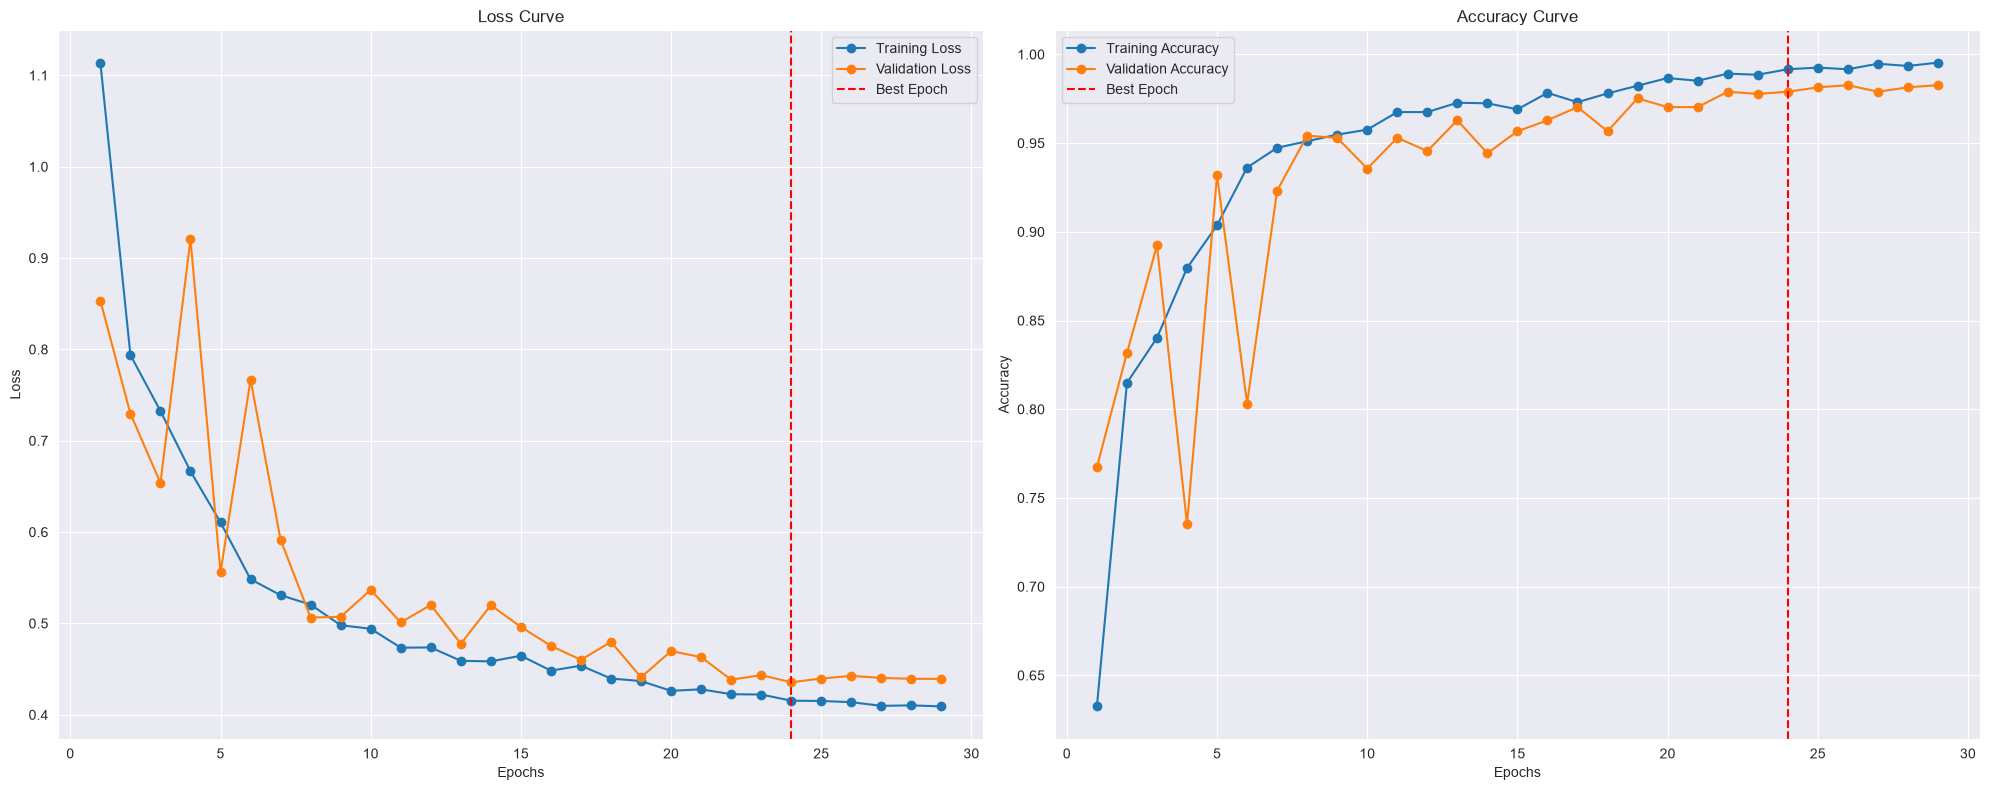


Training Report:
Total training time: 00:13:48
Total epochs run: 29
Best Training Loss: 0.4154 at epoch 24
Best Training Accuracy: 0.9916

Validation Report:
Best Validation Loss: 0.4356 at epoch 24
Best Validation Accuracy: 0.9790
Final Validation Loss: 0.4392
Final Validation Accuracy: 0.9827

Inference Report:
Total Inference Time (Validation only): 00:02:30
Accuracy:    0.98267
Recall:      0.98267
Precision:   0.98282
F1 Score:    0.98261
MCC:         0.97655
PR AUC:      0.98393
Kappa:       0.97648
Specificity: 0.99557
Saved fold 1 checkpoint -> custom_model_fold1.pth

FOLD 2/5  (train=3230, val=808)

Epoch 1/30
------------------------------


Validation Loss: 0.8029, Validation Accuracy: 0.8119
Training Loss: 1.0736, Training Accuracy: 0.6455

Epoch 2/30
------------------------------


Validation Loss: 0.6879, Validation Accuracy: 0.8639
Training Loss: 0.8070, Training Accuracy: 0.8031

Epoch 3/30
------------------------------


Validation Loss: 0.7663, Validation Accuracy: 0.8453
Training Loss: 0.7431, Training Accuracy: 0.8399
Patience Counter: 1/5

Epoch 4/30
------------------------------


Validation Loss: 0.6701, Validation Accuracy: 0.8787
Training Loss: 0.6965, Training Accuracy: 0.8613

Epoch 5/30
------------------------------


...

Validation Loss: 0.4351, Validation Accuracy: 0.9814
Training Loss: 0.4167, Training Accuracy: 0.9904
Patience Counter: 1/5

Epoch 27/30
------------------------------


Validation Loss: 0.4309, Validation Accuracy: 0.9790
Training Loss: 0.4139, Training Accuracy: 0.9920
Patience Counter: 2/5

Epoch 28/30
------------------------------


Validation Loss: 0.4337, Validation Accuracy: 0.9814
Training Loss: 0.4120, Training Accuracy: 0.9950
Patience Counter: 3/5

Epoch 29/30
------------------------------


Validation Loss: 0.4313, Validation Accuracy: 0.9814
Training Loss: 0.4160, Training Accuracy: 0.9916
Patience Counter: 4/5

Epoch 30/30
------------------------------


Validation Loss: 0.4312, Validation Accuracy: 0.9802
Training Loss: 0.4117, Training Accuracy: 0.9929
Patience Counter: 5/5
Early stopping triggered at epoch 30.


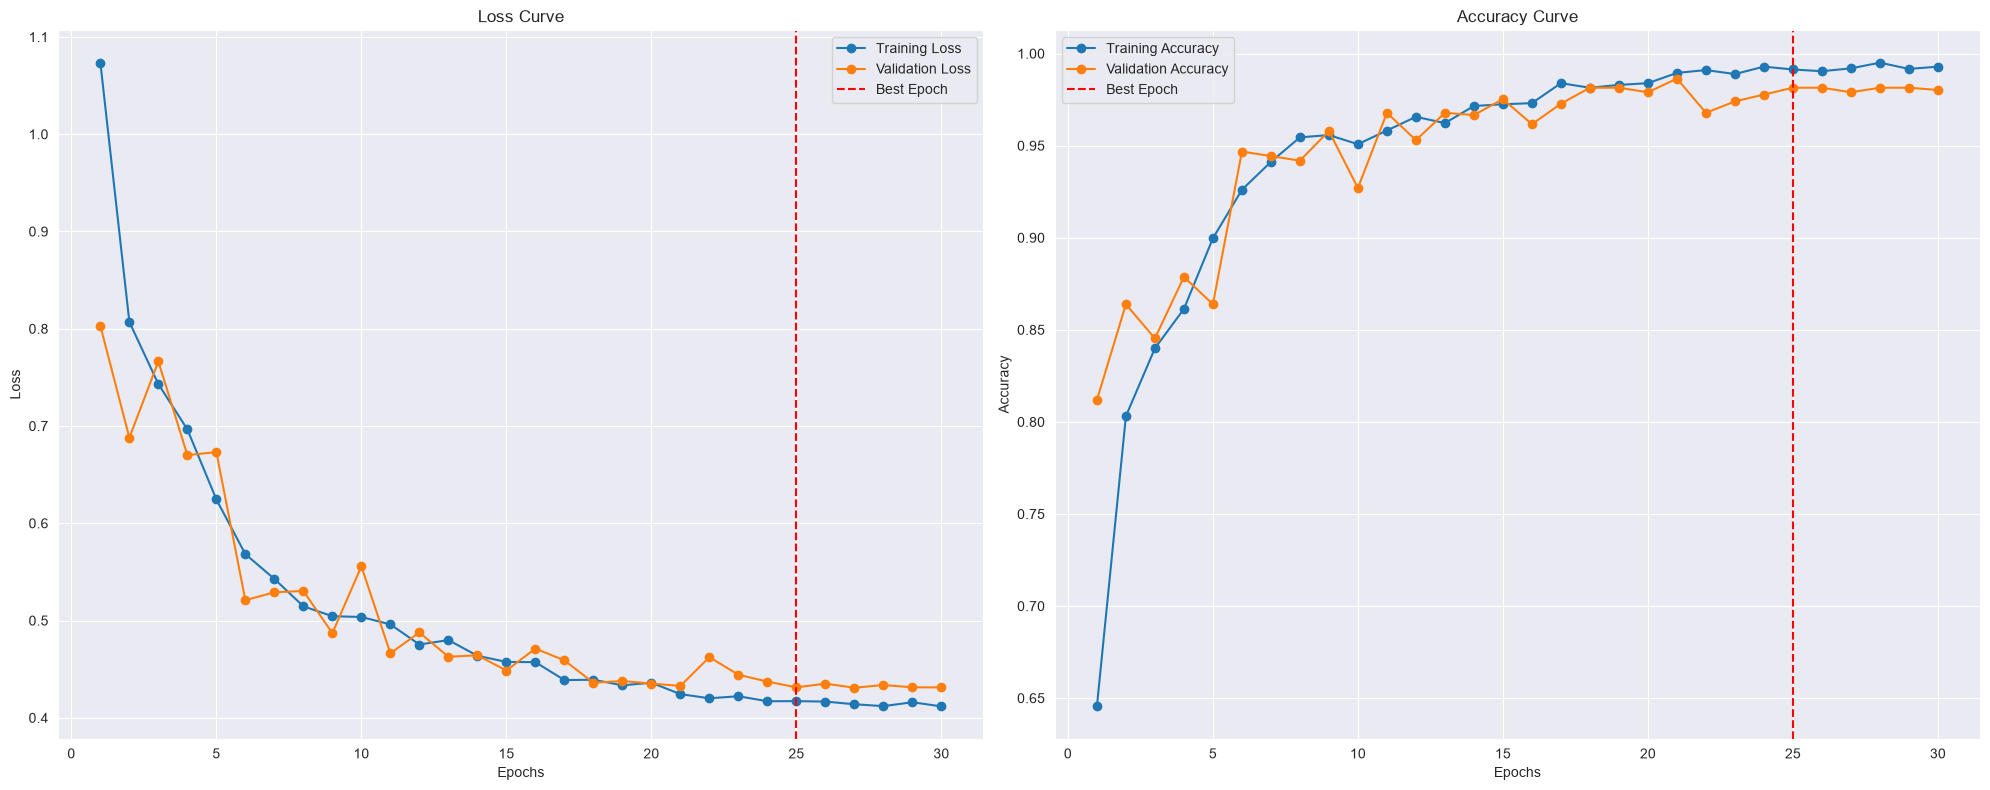


Training Report:
Total training time: 00:13:55
Total epochs run: 30
Best Training Loss: 0.4171 at epoch 25
Best Training Accuracy: 0.9913

Validation Report:
Best Validation Loss: 0.4313 at epoch 25
Best Validation Accuracy: 0.9814
Final Validation Loss: 0.4312
Final Validation Accuracy: 0.9802

Inference Report:
Total Inference Time (Validation only): 00:02:33
Accuracy:    0.98020
Recall:      0.98020
Precision:   0.98026
F1 Score:    0.98020
MCC:         0.97316
PR AUC:      0.99784
Kappa:       0.97314
Specificity: 0.99518
Saved fold 2 checkpoint -> custom_model_fold2.pth

FOLD 3/5  (train=3230, val=808)

Epoch 1/30
------------------------------


Validation Loss: 0.7792, Validation Accuracy: 0.8045
Training Loss: 1.0059, Training Accuracy: 0.6972

Epoch 2/30
------------------------------


Validation Loss: 0.6652, Validation Accuracy: 0.8787
Training Loss: 0.8147, Training Accuracy: 0.7858

Epoch 3/30
------------------------------


Validation Loss: 0.6391, Validation Accuracy: 0.8886
Training Loss: 0.7403, Training Accuracy: 0.8353

Epoch 4/30
------------------------------


Validation Loss: 0.5961, Validation Accuracy: 0.9208
Training Loss: 0.6854, Training Accuracy: 0.8653

Epoch 5/30
------------------------------


...

Validation Loss: 0.4262, Validation Accuracy: 0.9864
Training Loss: 0.4124, Training Accuracy: 0.9954
Patience Counter: 1/5

Epoch 27/30
------------------------------


Validation Loss: 0.4273, Validation Accuracy: 0.9864
Training Loss: 0.4138, Training Accuracy: 0.9929
Patience Counter: 2/5

Epoch 28/30
------------------------------


Validation Loss: 0.4266, Validation Accuracy: 0.9889
Training Loss: 0.4105, Training Accuracy: 0.9947
Patience Counter: 3/5

Epoch 29/30
------------------------------


Validation Loss: 0.4247, Validation Accuracy: 0.9876
Training Loss: 0.4109, Training Accuracy: 0.9944
Patience Counter: 4/5

Epoch 30/30
------------------------------


Validation Loss: 0.4259, Validation Accuracy: 0.9876
Training Loss: 0.4087, Training Accuracy: 0.9963
Patience Counter: 5/5
Early stopping triggered at epoch 30.


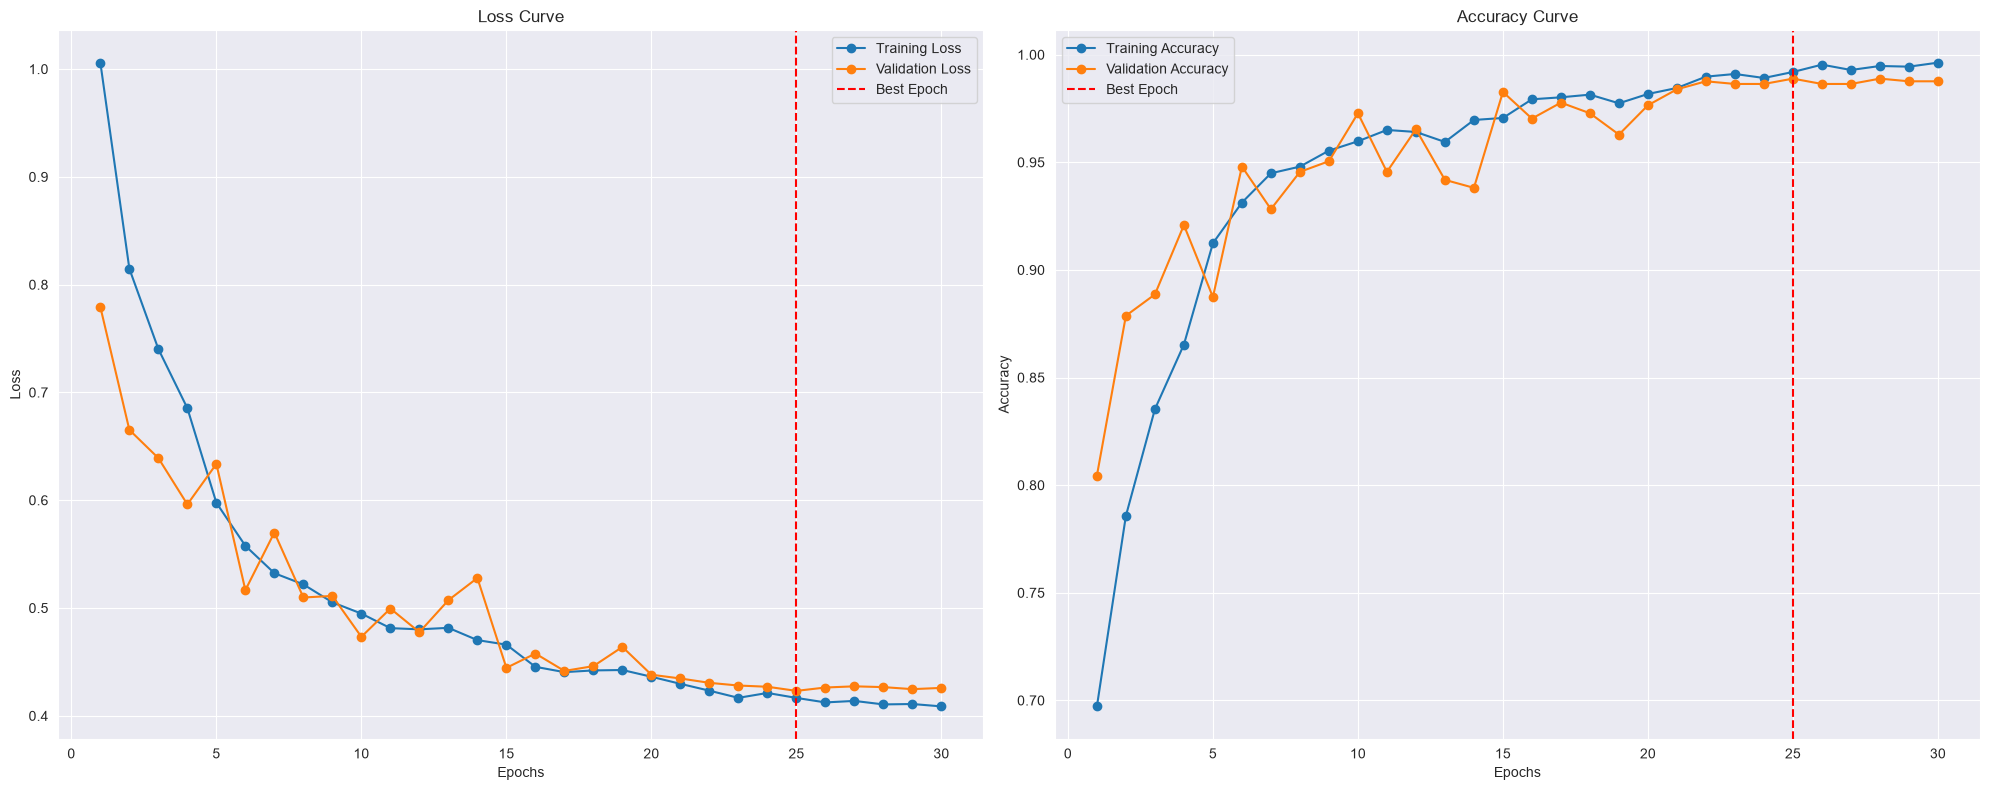


Training Report:
Total training time: 00:13:42
Total epochs run: 30
Best Training Loss: 0.4166 at epoch 25
Best Training Accuracy: 0.9920

Validation Report:
Best Validation Loss: 0.4231 at epoch 25
Best Validation Accuracy: 0.9889
Final Validation Loss: 0.4259
Final Validation Accuracy: 0.9876

Inference Report:
Total Inference Time (Validation only): 00:02:32
Accuracy:    0.98762
Recall:      0.98762
Precision:   0.98769
F1 Score:    0.98763
MCC:         0.98319
PR AUC:      0.99522
Kappa:       0.98318
Specificity: 0.99673
Saved fold 3 checkpoint -> custom_model_fold3.pth

FOLD 4/5  (train=3231, val=807)

Epoch 1/30
------------------------------


Validation Loss: 0.7826, Validation Accuracy: 0.8166
Training Loss: 1.0254, Training Accuracy: 0.6815

Epoch 2/30
------------------------------


Validation Loss: 0.7046, Validation Accuracy: 0.8538
Training Loss: 0.8138, Training Accuracy: 0.8004

Epoch 3/30
------------------------------


Validation Loss: 0.6507, Validation Accuracy: 0.8848
Training Loss: 0.7137, Training Accuracy: 0.8536

Epoch 4/30
------------------------------


Validation Loss: 0.5932, Validation Accuracy: 0.9046
Training Loss: 0.6864, Training Accuracy: 0.8750

Epoch 5/30
------------------------------


...

Validation Loss: 0.4043, Validation Accuracy: 0.9988
Training Loss: 0.4185, Training Accuracy: 0.9910
Patience Counter: 2/5

Epoch 27/30
------------------------------


Validation Loss: 0.4045, Validation Accuracy: 0.9975
Training Loss: 0.4178, Training Accuracy: 0.9895
Patience Counter: 3/5

Epoch 28/30
------------------------------


Validation Loss: 0.4024, Validation Accuracy: 0.9950
Training Loss: 0.4143, Training Accuracy: 0.9926

Epoch 29/30
------------------------------


Validation Loss: 0.4021, Validation Accuracy: 0.9975
Training Loss: 0.4115, Training Accuracy: 0.9941
Patience Counter: 1/5

Epoch 30/30
------------------------------


Validation Loss: 0.4021, Validation Accuracy: 0.9963
Training Loss: 0.4171, Training Accuracy: 0.9910
Patience Counter: 2/5


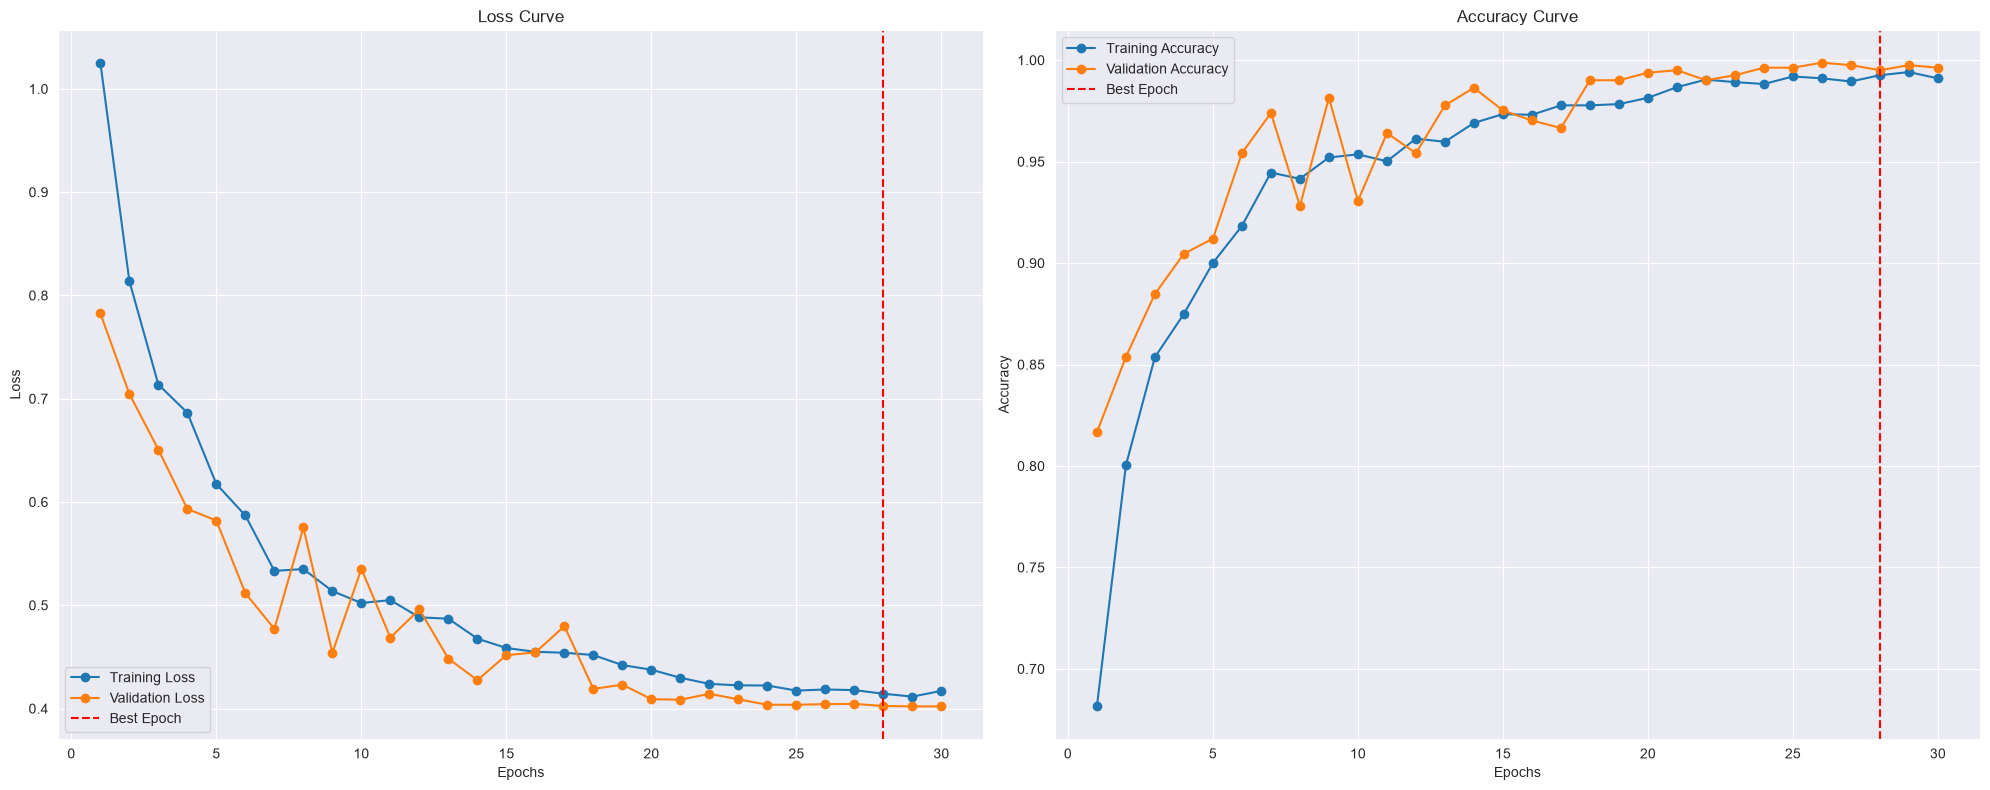


Training Report:
Total training time: 00:13:46
Total epochs run: 30
Best Training Loss: 0.4143 at epoch 28
Best Training Accuracy: 0.9926

Validation Report:
Best Validation Loss: 0.4024 at epoch 28
Best Validation Accuracy: 0.9950
Final Validation Loss: 0.4021
Final Validation Accuracy: 0.9963

Inference Report:
Total Inference Time (Validation only): 00:02:32
Accuracy:    0.99628
Recall:      0.99628
Precision:   0.99633
F1 Score:    0.99629
MCC:         0.99497
PR AUC:      0.99999
Kappa:       0.99496
Specificity: 0.99911
Saved fold 4 checkpoint -> custom_model_fold4.pth

FOLD 5/5  (train=3231, val=807)

Epoch 1/30
------------------------------


Validation Loss: 0.8179, Validation Accuracy: 0.7893
Training Loss: 1.0771, Training Accuracy: 0.6388

Epoch 2/30
------------------------------


Validation Loss: 0.6648, Validation Accuracy: 0.8823
Training Loss: 0.7769, Training Accuracy: 0.8131

Epoch 3/30
------------------------------


Validation Loss: 0.5914, Validation Accuracy: 0.9170
Training Loss: 0.7182, Training Accuracy: 0.8511

Epoch 4/30
------------------------------


Validation Loss: 0.6133, Validation Accuracy: 0.9033
Training Loss: 0.6642, Training Accuracy: 0.8793
Patience Counter: 1/5

Epoch 5/30
------------------------------


...

Validation Loss: 0.4410, Validation Accuracy: 0.9752
Training Loss: 0.4267, Training Accuracy: 0.9855
Patience Counter: 1/5

Epoch 24/30
------------------------------


Validation Loss: 0.4378, Validation Accuracy: 0.9740
Training Loss: 0.4226, Training Accuracy: 0.9882
Patience Counter: 2/5

Epoch 25/30
------------------------------


Validation Loss: 0.4418, Validation Accuracy: 0.9765
Training Loss: 0.4179, Training Accuracy: 0.9920
Patience Counter: 3/5

Epoch 26/30
------------------------------


Validation Loss: 0.4413, Validation Accuracy: 0.9740
Training Loss: 0.4159, Training Accuracy: 0.9920
Patience Counter: 4/5

Epoch 27/30
------------------------------


Validation Loss: 0.4336, Validation Accuracy: 0.9765
Training Loss: 0.4148, Training Accuracy: 0.9910
Patience Counter: 5/5
Early stopping triggered at epoch 27.


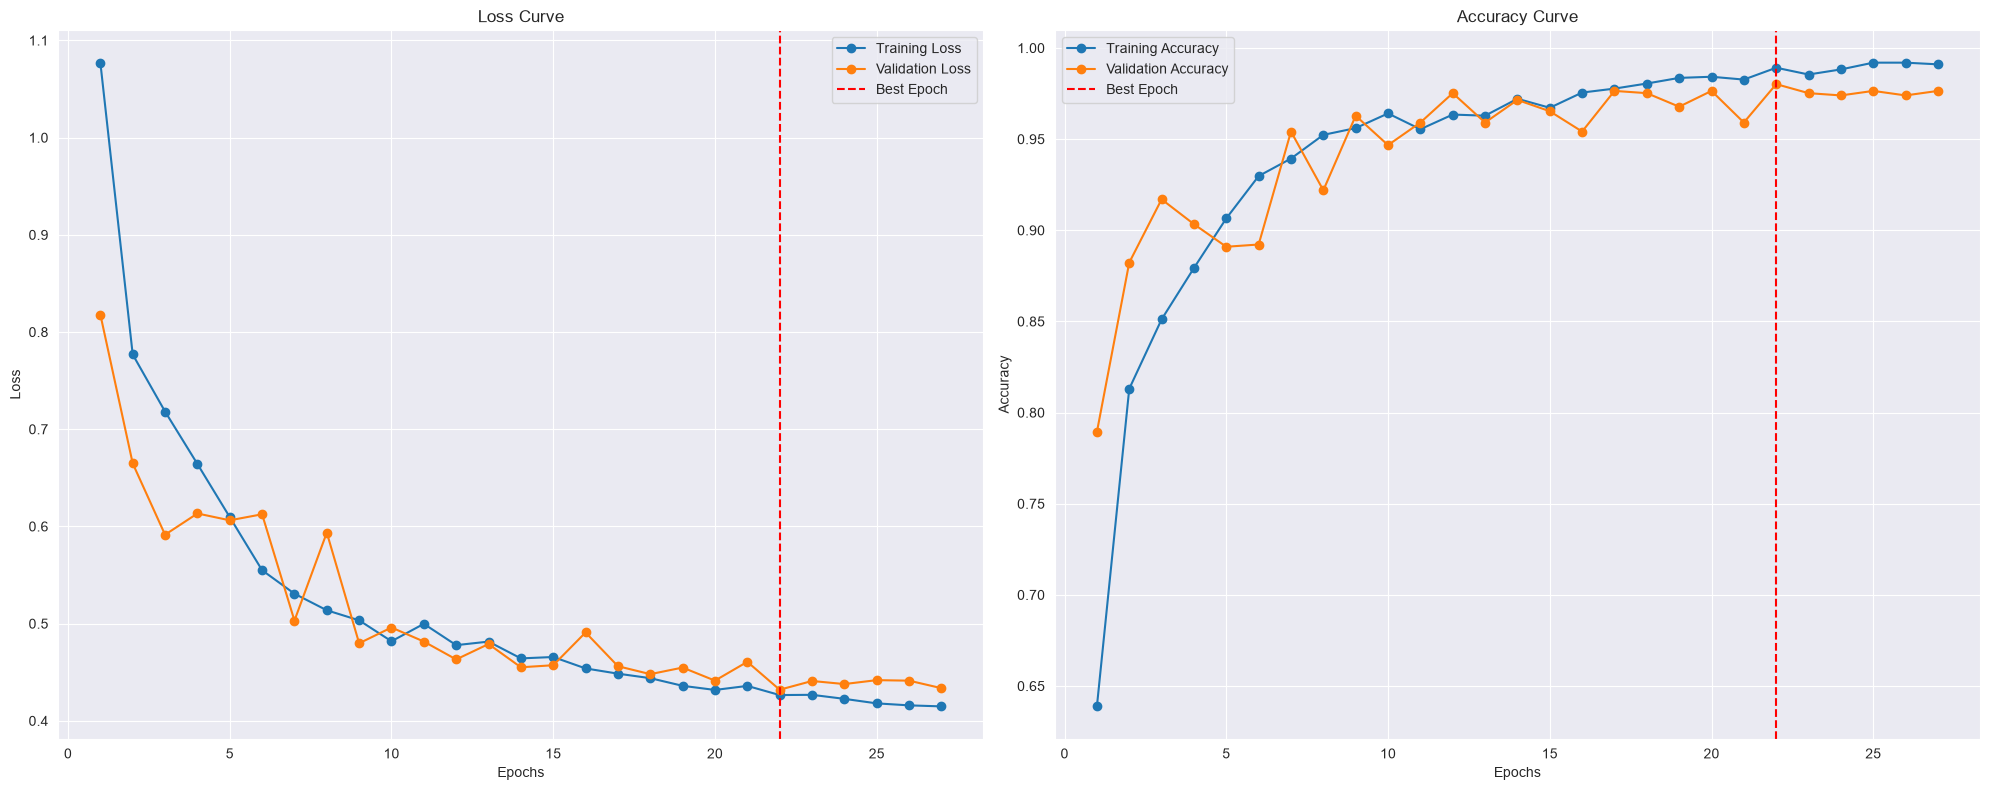


Training Report:
Total training time: 00:12:42
Total epochs run: 27
Best Training Loss: 0.4265 at epoch 22
Best Training Accuracy: 0.9892

Validation Report:
Best Validation Loss: 0.4320 at epoch 22
Best Validation Accuracy: 0.9802
Final Validation Loss: 0.4336
Final Validation Accuracy: 0.9765

Inference Report:
Total Inference Time (Validation only): 00:02:19
Accuracy:    0.97646
Recall:      0.97646
Precision:   0.97667
F1 Score:    0.97652
MCC:         0.96814
PR AUC:      0.99827
Kappa:       0.96811
Specificity: 0.99427
Saved fold 5 checkpoint -> custom_model_fold5.pth

Per-fold results:
      accuracy  recall  precision      f1     mcc  pr_auc   kappa  specificity
fold                                                                          
1       0.9827  0.9827     0.9828  0.9826  0.9765  0.9839  0.9765       0.9956
2       0.9802  0.9802     0.9803  0.9802  0.9732  0.9978  0.9731       0.9952
3       0.9876  0.9876     0.9877  0.9876  0.9832  0.9952  0.9832       0.9967
4  

In [13]:
import os
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR
from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedKFold
import torchvision.transforms as transforms

# Assuming these are available in your workspace
from my_dataset1 import CustomImageDataset


# ──────────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────────
N_FOLDS            = 5
RANDOM_STATE       = 42
NUM_EPOCHS         = 30
PATIENCE           = 5
MIN_DELTA          = 0.001
WARMUP_EPOCHS      = 3
BASE_LR            = 5e-4
WEIGHT_DECAY       = 0.02
BATCH_SIZE         = 32
NUM_WORKERS        = 4
IMAGE_SIZE         = 224 # Adjust if your custom model expects a different size

# ──────────────────────────────────────────────────────────────────────────
# ONLINE AUGMENTATION TRANSFORMS
# ──────────────────────────────────────────────────────────────────────────
# Applied dynamically every time a batch is loaded during training
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomAffine(degrees=[-15, 15], scale=[0.9, 1.1]),
    transforms.ColorJitter(brightness=[1.0, 1.2]),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Strict, deterministic transform for validation (NO random augmentations)
val_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ──────────────────────────────────────────────────────────────────────────
# LABEL MAPPING
# ──────────────────────────────────────────────────────────────────────────
label_mapping = {label: idx for idx, label in enumerate(df['labels'].unique())}
num_classes = len(label_mapping)

df = df.reset_index(drop=True)
print(f"Full dataset: {len(df)} images across {num_classes} classes")
print(f"Running {N_FOLDS}-fold CV with ONLINE Augmentation (no held-out test set)")


# ──────────────────────────────────────────────────────────────────────────
# OPTIMIZER / SCHEDULER BUILDER (fresh instance needed every fold)
# ──────────────────────────────────────────────────────────────────────────
def build_optimizer_scheduler(model):
    param_groups = get_parameter_groups(model, weight_decay=WEIGHT_DECAY)
    optimizer = optim.AdamW(param_groups, lr=BASE_LR)

    warmup_scheduler = LinearLR(
        optimizer, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS
    )
    cosine_scheduler = CosineAnnealingLR(
        optimizer, T_max=NUM_EPOCHS - WARMUP_EPOCHS, eta_min=1e-6
    )
    scheduler = SequentialLR(
        optimizer, schedulers=[warmup_scheduler, cosine_scheduler],
        milestones=[WARMUP_EPOCHS]
    )
    return optimizer, scheduler


# ──────────────────────────────────────────────────────────────────────────
# SINGLE-FOLD ROUTINE
# ──────────────────────────────────────────────────────────────────────────
def run_single_fold(fold_idx, fold_train_df, fold_val_df):
    print(f"\n{'='*70}\nFOLD {fold_idx}/{N_FOLDS}"
          f"  (train={len(fold_train_df)}, val={len(fold_val_df)})\n{'='*70}")

    # ---- datasets / loaders with ONLINE transforms ----
    fold_train_labels = fold_train_df['labels'].map(label_mapping).values
    fold_val_labels = fold_val_df['labels'].map(label_mapping).values

    # Pass train_transform (with online augmentation) to training set
    fold_train_dataset = CustomImageDataset(
        fold_train_df['filepaths'].values, fold_train_labels, transform=train_transform
    )
    
    # Pass val_transform (deterministic) to validation set
    fold_val_dataset = CustomImageDataset(
        fold_val_df['filepaths'].values, fold_val_labels, transform=val_transform
    )

    fold_train_loader = DataLoader(fold_train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                                    num_workers=NUM_WORKERS, pin_memory=True)
    fold_val_loader = DataLoader(fold_val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                                  num_workers=NUM_WORKERS, pin_memory=True)

    # ---- fresh model, optimizer, scheduler for THIS fold ----
    model = load_custom_model(num_classes, device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer, scheduler = build_optimizer_scheduler(model)

    # ---- training ----
    train_model(model, fold_train_loader, fold_val_loader, criterion, optimizer,
                scheduler, num_epochs=NUM_EPOCHS, patience=PATIENCE, min_delta=MIN_DELTA)

    # ---- evaluation ----
    fold_metrics = evaluate_model_with_metrics(model, fold_val_loader)
    if fold_metrics is None:
        raise ValueError(
            "evaluate_model_with_metrics returned None. Ensure it returns a dictionary "
            "of metrics like {'accuracy': 0.95, ...} so they can be aggregated."
        )

    # Save fold checkpoint
    checkpoint_path = f"custom_model_fold{fold_idx}.pth"
    torch.save(model.state_dict(), checkpoint_path)
    print(f"Saved fold {fold_idx} checkpoint -> {checkpoint_path}")

    # ---- cleanup memory ----
    del model, optimizer, scheduler
    gc.collect()
    torch.cuda.empty_cache()

    return fold_metrics


# ──────────────────────────────────────────────────────────────────────────
# MAIN CV LOOP
# ──────────────────────────────────────────────────────────────────────────
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

fold_results = []
for fold_idx, (train_idx, val_idx) in enumerate(
    skf.split(df['filepaths'], df['labels']), start=1
):
    fold_train_df = df.iloc[train_idx].reset_index(drop=True)
    fold_val_df = df.iloc[val_idx].reset_index(drop=True)

    metrics = run_single_fold(fold_idx, fold_train_df, fold_val_df)
    metrics["fold"] = fold_idx
    fold_results.append(metrics)


# ──────────────────────────────────────────────────────────────────────────
# AGGREGATE RESULTS
# ──────────────────────────────────────────────────────────────────────────
def summarize_cv_results(fold_results):
    results_df = pd.DataFrame(fold_results).set_index("fold")
    summary = results_df.agg(['mean', 'std'])

    print("\nPer-fold results:")
    print(results_df.round(4).to_string())  # Using to_string() to avoid tabulate dependency
    print(f"\nMean ± Std across {len(results_df)} folds:")
    for col in results_df.columns:
        print(f"  {col}: {summary.loc['mean', col]:.4f} ± {summary.loc['std', col]:.4f}")

    return results_df, summary

cv_results_df, cv_summary = summarize_cv_results(fold_results)
cv_results_df.to_csv("cv_fold_results_proposed.csv")

Full dataset: 4038 images across 5 classes
Running 5-fold CV with ONLINE Augmentation (no held-out test set)

FOLD 1/5  (train=3230, val=808)

Epoch 1/20
------------------------------


Validation Loss: 0.6085, Validation Accuracy: 0.7896
Training Loss: 0.6503, Training Accuracy: 0.7619

Epoch 2/20
------------------------------


Validation Loss: 0.4410, Validation Accuracy: 0.8540
Training Loss: 0.4159, Training Accuracy: 0.8480

Epoch 3/20
------------------------------


Validation Loss: 0.3680, Validation Accuracy: 0.8750
Training Loss: 0.2986, Training Accuracy: 0.8994

Epoch 4/20
------------------------------


Validation Loss: 0.2369, Validation Accuracy: 0.9233
Training Loss: 0.2731, Training Accuracy: 0.9040

Epoch 5/20
------------------------------


...

Validation Loss: 0.0864, Validation Accuracy: 0.9715
Training Loss: 0.0482, Training Accuracy: 0.9817
Patience Counter: 1/5

Epoch 17/20
------------------------------


Validation Loss: 0.0799, Validation Accuracy: 0.9765
Training Loss: 0.0375, Training Accuracy: 0.9873
Patience Counter: 2/5

Epoch 18/20
------------------------------


Validation Loss: 0.0724, Validation Accuracy: 0.9765
Training Loss: 0.0303, Training Accuracy: 0.9907

Epoch 19/20
------------------------------


Validation Loss: 0.0729, Validation Accuracy: 0.9790
Training Loss: 0.0334, Training Accuracy: 0.9892
Patience Counter: 1/5

Epoch 20/20
------------------------------


Validation Loss: 0.0715, Validation Accuracy: 0.9790
Training Loss: 0.0246, Training Accuracy: 0.9923
Patience Counter: 2/5


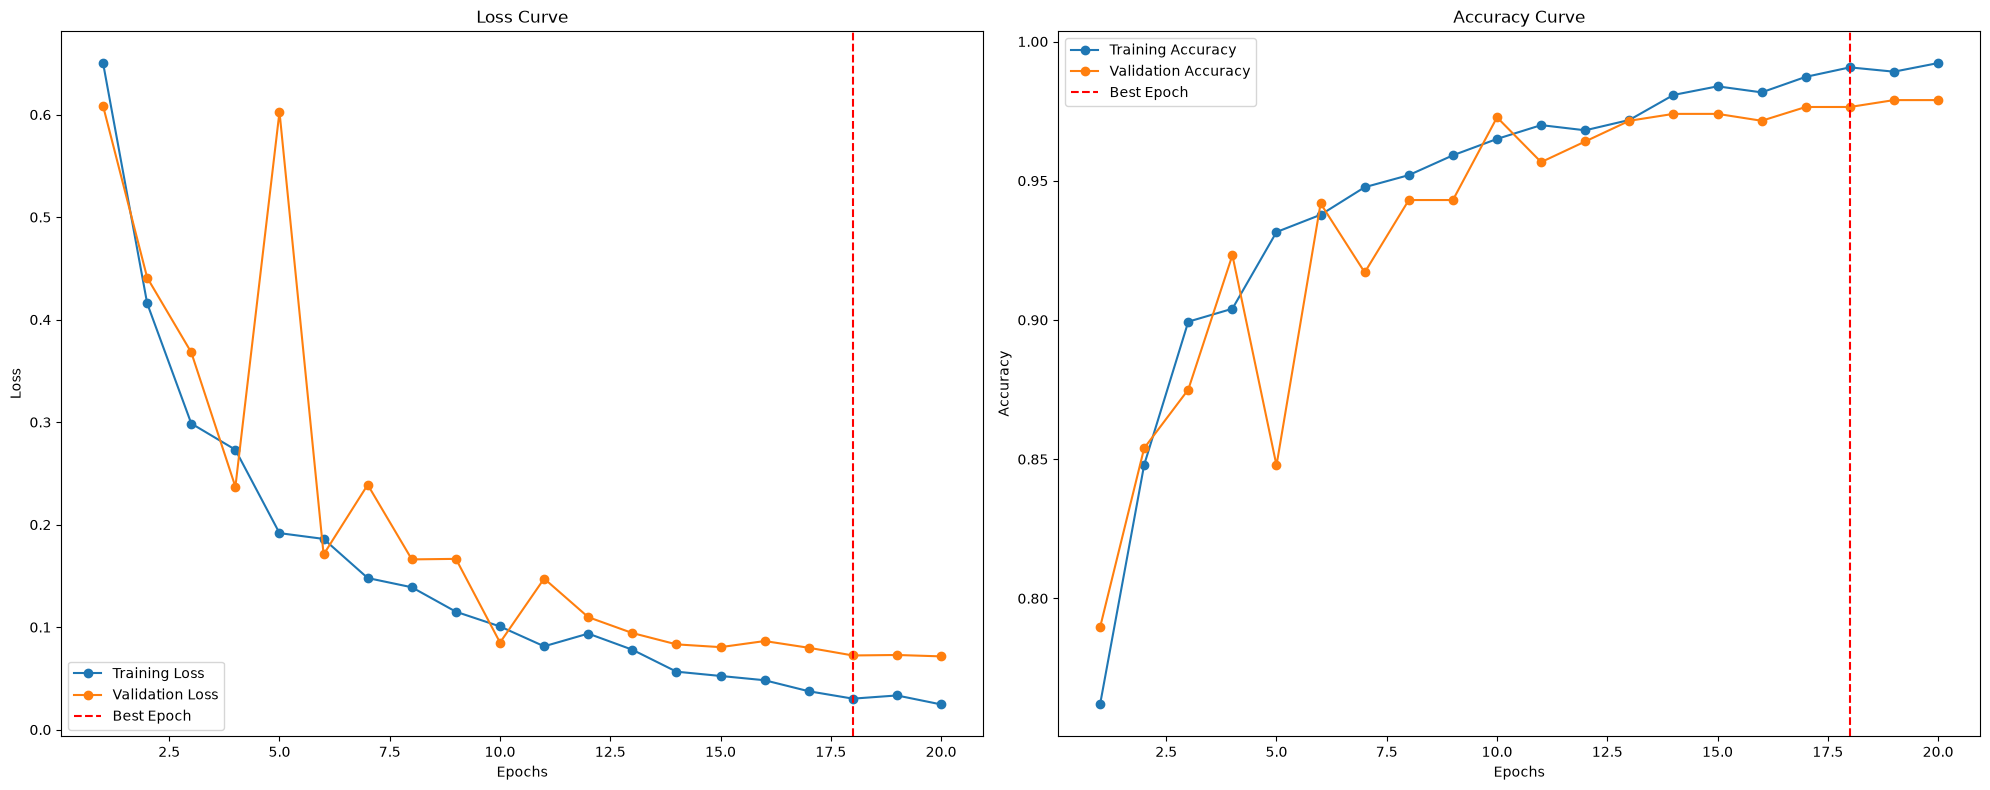


Training Report:
Total training time: 00:09:57
Total epochs run: 20
Best Training Loss: 0.0303 at epoch 18
Best Training Accuracy: 0.9907

Validation Report:
Best Validation Loss: 0.0724 at epoch 18
Best Validation Accuracy: 0.9765
Final Validation Loss: 0.0715
Final Validation Accuracy: 0.9790

Inference Report:
Total Inference Time (Validation only): 00:01:45
Accuracy:    0.97896
Recall:      0.97896
Precision:   0.97902
F1 Score:    0.97896
MCC:         0.97147
PR AUC:      0.99574
Kappa:       0.97146
Specificity: 0.99481
Saved fold 1 checkpoint -> resnest50d_fold1.pth

FOLD 2/5  (train=3230, val=808)

Epoch 1/20
------------------------------


Validation Loss: 0.5178, Validation Accuracy: 0.7958
Training Loss: 0.6664, Training Accuracy: 0.7511

Epoch 2/20
------------------------------


Validation Loss: 0.8567, Validation Accuracy: 0.6782
Training Loss: 0.4070, Training Accuracy: 0.8585
Patience Counter: 1/5

Epoch 3/20
------------------------------


Validation Loss: 0.5334, Validation Accuracy: 0.8502
Training Loss: 0.2957, Training Accuracy: 0.8926
Patience Counter: 2/5

Epoch 4/20
------------------------------


Validation Loss: 0.6737, Validation Accuracy: 0.7884
Training Loss: 0.2465, Training Accuracy: 0.9111
Patience Counter: 3/5

Epoch 5/20
------------------------------


...

Validation Loss: 0.0564, Validation Accuracy: 0.9851
Training Loss: 0.0477, Training Accuracy: 0.9861

Epoch 17/20
------------------------------


Validation Loss: 0.0494, Validation Accuracy: 0.9839
Training Loss: 0.0448, Training Accuracy: 0.9851

Epoch 18/20
------------------------------


Validation Loss: 0.0517, Validation Accuracy: 0.9827
Training Loss: 0.0367, Training Accuracy: 0.9889
Patience Counter: 1/5

Epoch 19/20
------------------------------


Validation Loss: 0.0434, Validation Accuracy: 0.9864
Training Loss: 0.0410, Training Accuracy: 0.9848

Epoch 20/20
------------------------------


Validation Loss: 0.0505, Validation Accuracy: 0.9814
Training Loss: 0.0329, Training Accuracy: 0.9898
Patience Counter: 1/5


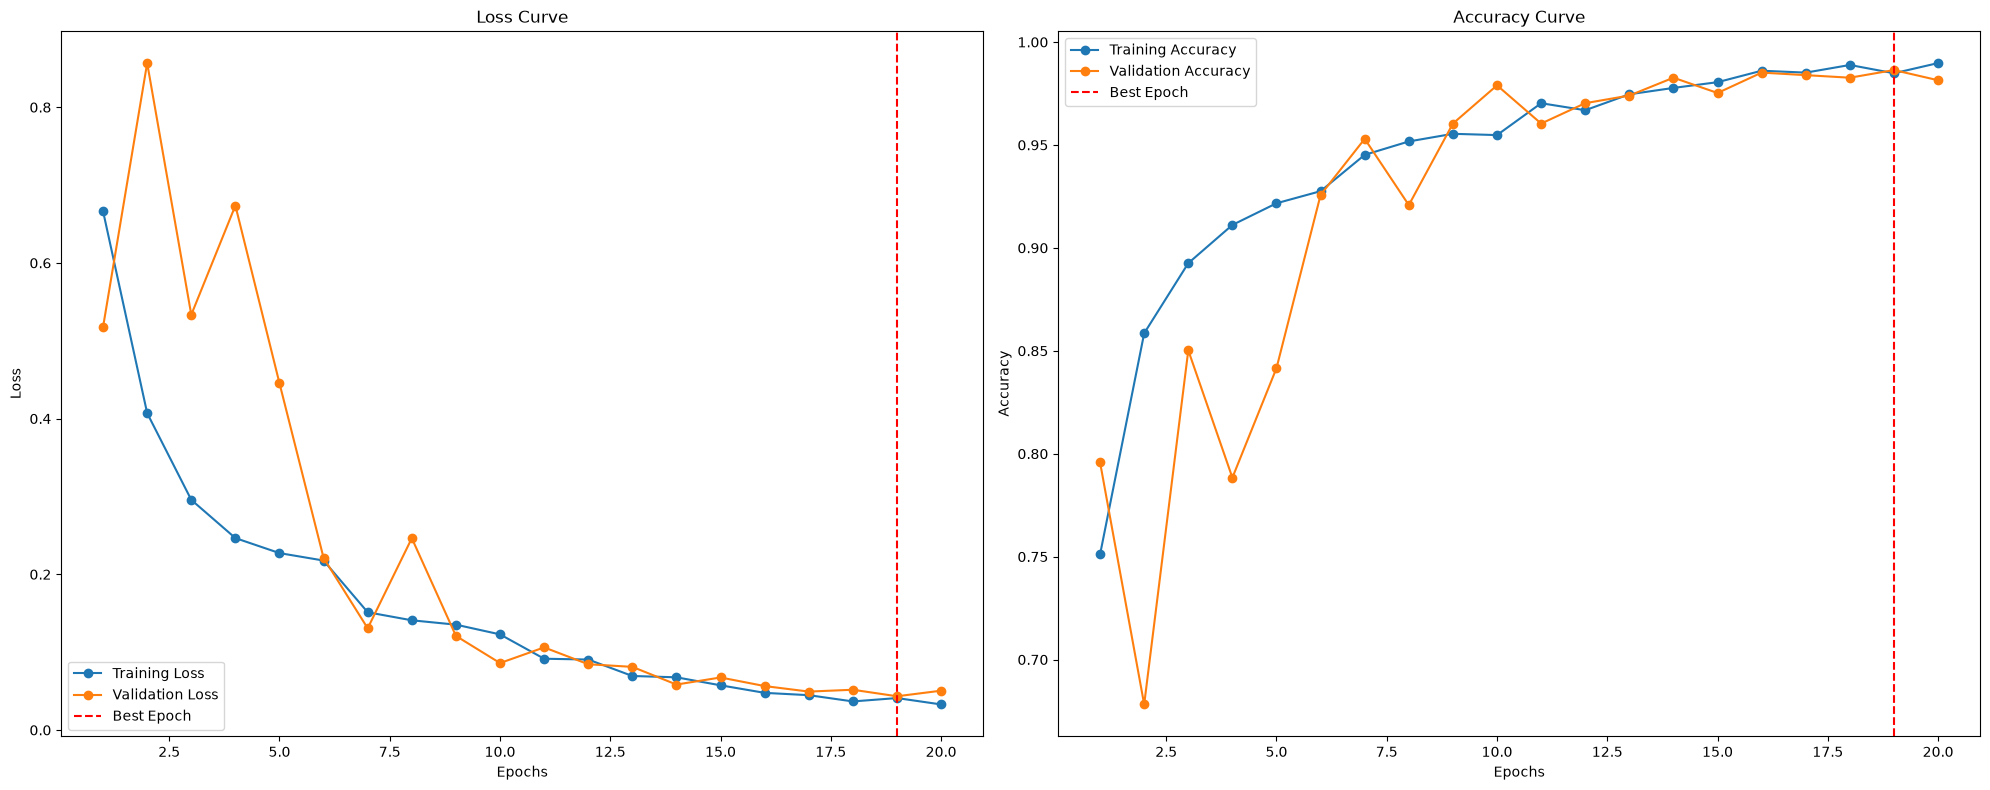


Training Report:
Total training time: 00:09:54
Total epochs run: 20
Best Training Loss: 0.0410 at epoch 19
Best Training Accuracy: 0.9848

Validation Report:
Best Validation Loss: 0.0434 at epoch 19
Best Validation Accuracy: 0.9864
Final Validation Loss: 0.0505
Final Validation Accuracy: 0.9814

Inference Report:
Total Inference Time (Validation only): 00:01:44
Accuracy:    0.98144
Recall:      0.98144
Precision:   0.98173
F1 Score:    0.98149
MCC:         0.97495
PR AUC:      0.99777
Kappa:       0.97488
Specificity: 0.99564
Saved fold 2 checkpoint -> resnest50d_fold2.pth

FOLD 3/5  (train=3230, val=808)

Epoch 1/20
------------------------------


Validation Loss: 0.6284, Validation Accuracy: 0.7760
Training Loss: 0.6703, Training Accuracy: 0.7437

Epoch 2/20
------------------------------


Validation Loss: 0.3209, Validation Accuracy: 0.8886
Training Loss: 0.3940, Training Accuracy: 0.8607

Epoch 3/20
------------------------------


Validation Loss: 0.2971, Validation Accuracy: 0.8886
Training Loss: 0.3346, Training Accuracy: 0.8827

Epoch 4/20
------------------------------


Validation Loss: 0.4039, Validation Accuracy: 0.8725
Training Loss: 0.2492, Training Accuracy: 0.9105
Patience Counter: 1/5

Epoch 5/20
------------------------------


...

Validation Loss: 0.0676, Validation Accuracy: 0.9827
Training Loss: 0.0517, Training Accuracy: 0.9848

Epoch 17/20
------------------------------


Validation Loss: 0.0642, Validation Accuracy: 0.9864
Training Loss: 0.0437, Training Accuracy: 0.9845

Epoch 18/20
------------------------------


Validation Loss: 0.0713, Validation Accuracy: 0.9790
Training Loss: 0.0440, Training Accuracy: 0.9854
Patience Counter: 1/5

Epoch 19/20
------------------------------


Validation Loss: 0.0592, Validation Accuracy: 0.9864
Training Loss: 0.0390, Training Accuracy: 0.9867

Epoch 20/20
------------------------------


Validation Loss: 0.0634, Validation Accuracy: 0.9827
Training Loss: 0.0350, Training Accuracy: 0.9892
Patience Counter: 1/5


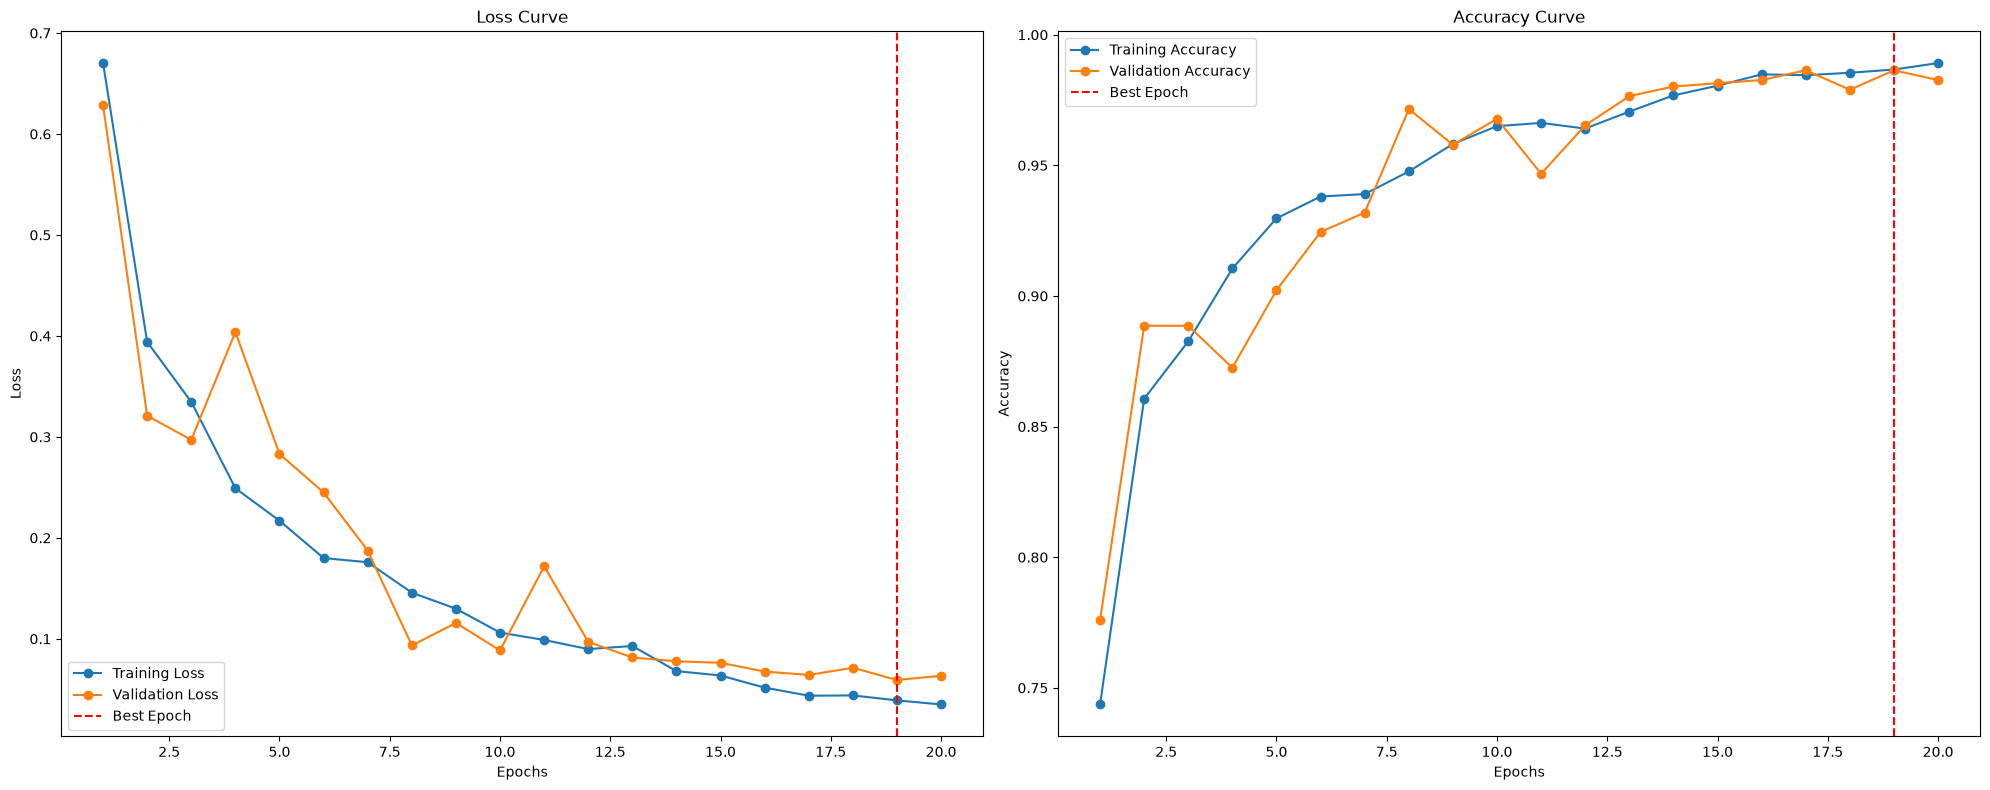


Training Report:
Total training time: 00:09:52
Total epochs run: 20
Best Training Loss: 0.0390 at epoch 19
Best Training Accuracy: 0.9867

Validation Report:
Best Validation Loss: 0.0592 at epoch 19
Best Validation Accuracy: 0.9864
Final Validation Loss: 0.0634
Final Validation Accuracy: 0.9827

Inference Report:
Total Inference Time (Validation only): 00:01:44
Accuracy:    0.98267
Recall:      0.98267
Precision:   0.98307
F1 Score:    0.98274
MCC:         0.97652
PR AUC:      0.99759
Kappa:       0.97647
Specificity: 0.99553
Saved fold 3 checkpoint -> resnest50d_fold3.pth

FOLD 4/5  (train=3231, val=807)

Epoch 1/20
------------------------------


Validation Loss: 0.5085, Validation Accuracy: 0.8079
Training Loss: 0.6920, Training Accuracy: 0.7509

Epoch 2/20
------------------------------


Validation Loss: 1.1266, Validation Accuracy: 0.6320
Training Loss: 0.3942, Training Accuracy: 0.8573
Patience Counter: 1/5

Epoch 3/20
------------------------------


Validation Loss: 0.3650, Validation Accuracy: 0.8662
Training Loss: 0.3299, Training Accuracy: 0.8867

Epoch 4/20
------------------------------


Validation Loss: 0.2325, Validation Accuracy: 0.9219
Training Loss: 0.2222, Training Accuracy: 0.9242

Epoch 5/20
------------------------------


...

Validation Loss: 0.0288, Validation Accuracy: 0.9888
Training Loss: 0.0608, Training Accuracy: 0.9790
Patience Counter: 1/5

Epoch 17/20
------------------------------


Validation Loss: 0.0522, Validation Accuracy: 0.9839
Training Loss: 0.0575, Training Accuracy: 0.9802
Patience Counter: 2/5

Epoch 18/20
------------------------------


Validation Loss: 0.0351, Validation Accuracy: 0.9901
Training Loss: 0.0635, Training Accuracy: 0.9824
Patience Counter: 3/5

Epoch 19/20
------------------------------


Validation Loss: 0.0368, Validation Accuracy: 0.9876
Training Loss: 0.0521, Training Accuracy: 0.9814
Patience Counter: 4/5

Epoch 20/20
------------------------------


Validation Loss: 0.0343, Validation Accuracy: 0.9876
Training Loss: 0.0465, Training Accuracy: 0.9845
Patience Counter: 5/5
Early stopping triggered at epoch 20.


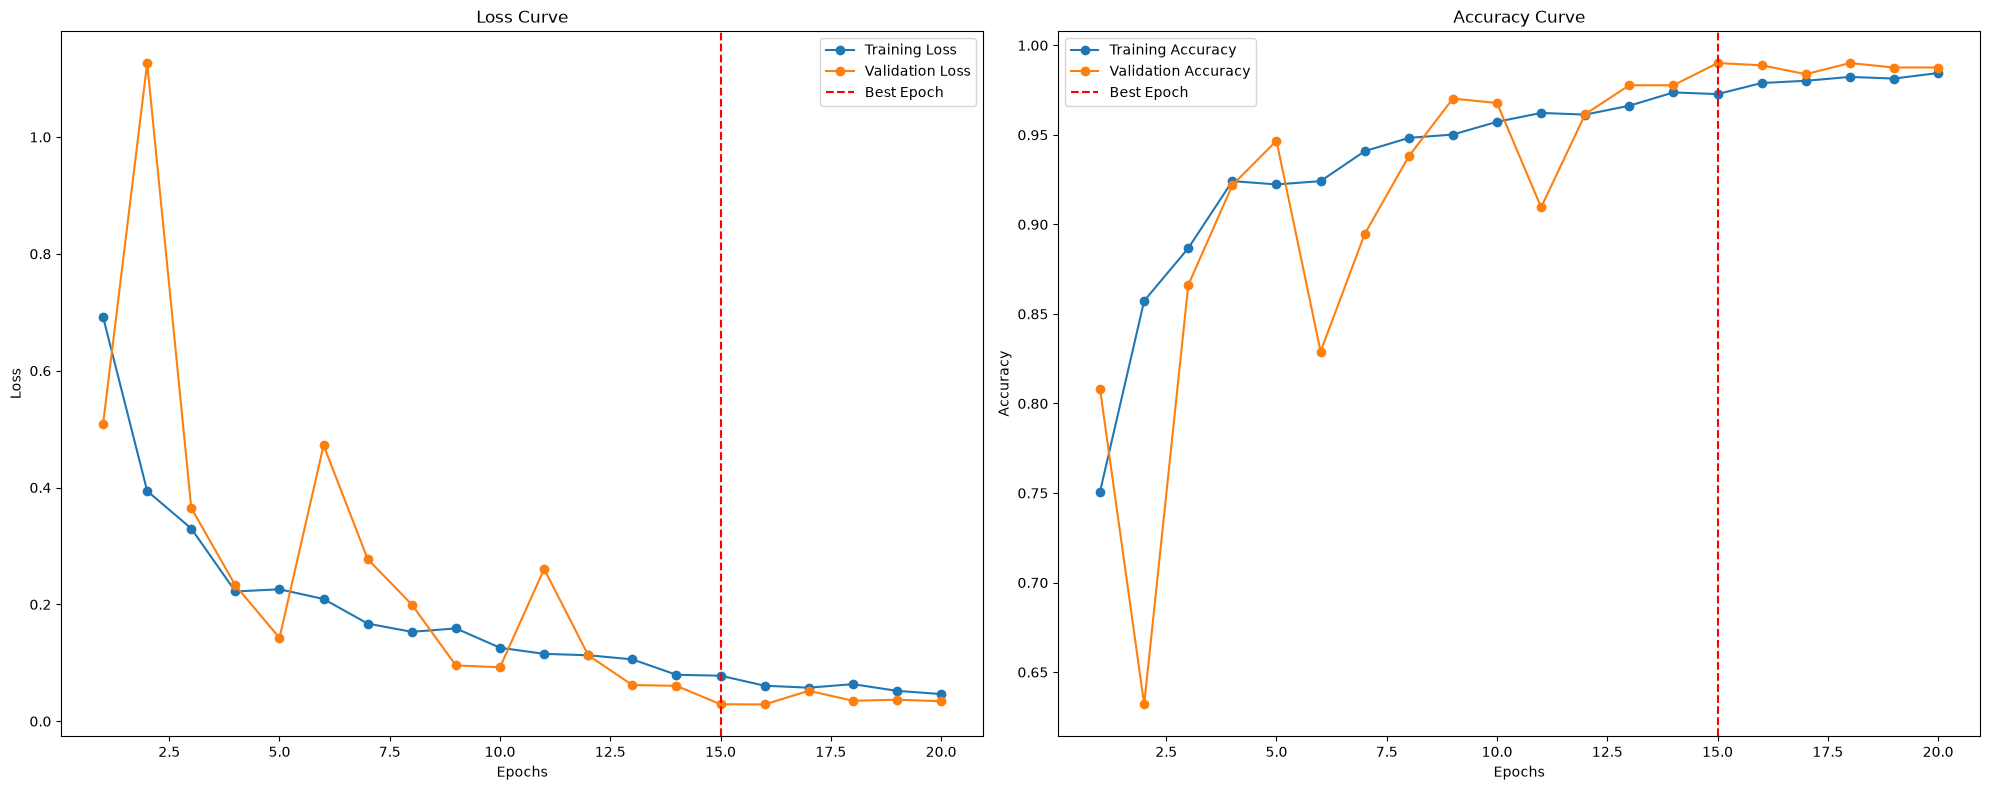


Training Report:
Total training time: 00:09:53
Total epochs run: 20
Best Training Loss: 0.0780 at epoch 15
Best Training Accuracy: 0.9728

Validation Report:
Best Validation Loss: 0.0291 at epoch 15
Best Validation Accuracy: 0.9901
Final Validation Loss: 0.0343
Final Validation Accuracy: 0.9876

Inference Report:
Total Inference Time (Validation only): 00:01:44
Accuracy:    0.98761
Recall:      0.98761
Precision:   0.98769
F1 Score:    0.98758
MCC:         0.98320
PR AUC:      0.99940
Kappa:       0.98318
Specificity: 0.99683
Saved fold 4 checkpoint -> resnest50d_fold4.pth

FOLD 5/5  (train=3231, val=807)

Epoch 1/20
------------------------------


Validation Loss: 0.4263, Validation Accuracy: 0.8476
Training Loss: 0.6991, Training Accuracy: 0.7323

Epoch 2/20
------------------------------


Validation Loss: 0.3771, Validation Accuracy: 0.8662
Training Loss: 0.3548, Training Accuracy: 0.8728

Epoch 3/20
------------------------------


Validation Loss: 0.3636, Validation Accuracy: 0.8748
Training Loss: 0.3138, Training Accuracy: 0.8870

Epoch 4/20
------------------------------


Validation Loss: 0.2129, Validation Accuracy: 0.9281
Training Loss: 0.2822, Training Accuracy: 0.9037

Epoch 5/20
------------------------------


...

Validation Loss: 0.0676, Validation Accuracy: 0.9765
Training Loss: 0.0525, Training Accuracy: 0.9855

Epoch 17/20
------------------------------


Validation Loss: 0.0577, Validation Accuracy: 0.9827
Training Loss: 0.0474, Training Accuracy: 0.9830

Epoch 18/20
------------------------------


Validation Loss: 0.0593, Validation Accuracy: 0.9814
Training Loss: 0.0464, Training Accuracy: 0.9851
Patience Counter: 1/5

Epoch 19/20
------------------------------


Validation Loss: 0.0538, Validation Accuracy: 0.9827
Training Loss: 0.0465, Training Accuracy: 0.9833

Epoch 20/20
------------------------------


Validation Loss: 0.0571, Validation Accuracy: 0.9814
Training Loss: 0.0413, Training Accuracy: 0.9867
Patience Counter: 1/5


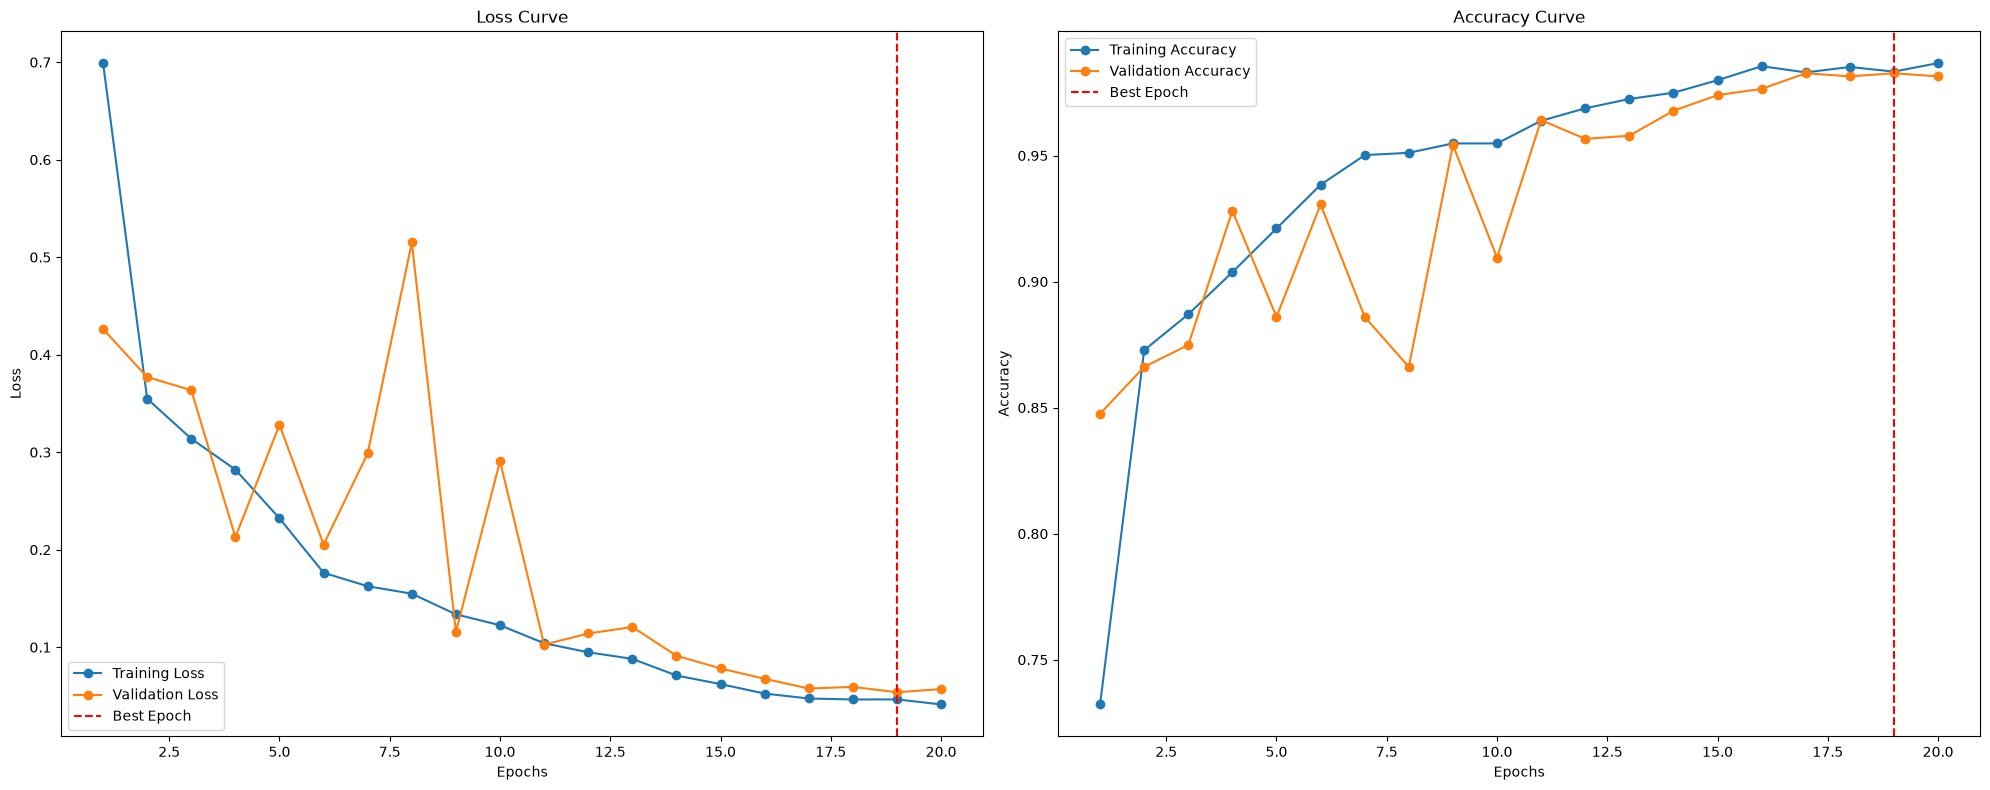


Training Report:
Total training time: 00:09:58
Total epochs run: 20
Best Training Loss: 0.0465 at epoch 19
Best Training Accuracy: 0.9833

Validation Report:
Best Validation Loss: 0.0538 at epoch 19
Best Validation Accuracy: 0.9827
Final Validation Loss: 0.0571
Final Validation Accuracy: 0.9814

Inference Report:
Total Inference Time (Validation only): 00:01:45
Accuracy:    0.98141
Recall:      0.98141
Precision:   0.98182
F1 Score:    0.98147
MCC:         0.97486
PR AUC:      0.99652
Kappa:       0.97479
Specificity: 0.99536
Saved fold 5 checkpoint -> resnest50d_fold5.pth

Per-fold results:
      accuracy  recall  precision      f1     mcc  pr_auc   kappa  specificity
fold                                                                          
1       0.9790  0.9790     0.9790  0.9790  0.9715  0.9957  0.9715       0.9948
2       0.9814  0.9814     0.9817  0.9815  0.9749  0.9978  0.9749       0.9956
3       0.9827  0.9827     0.9831  0.9827  0.9765  0.9976  0.9765       0.9955
4    

In [ ]:
import os
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedKFold
from torchvision import transforms
import timm

from my_dataset1 import CustomImageDataset

# ──────────────────────────────────────────────────────────────────────────
# CONFIG & TRANSFORMS (Online Augmentation)
# ──────────────────────────────────────────────────────────────────────────
N_FOLDS            = 5
RANDOM_STATE       = 42
NUM_EPOCHS         = 20
PATIENCE           = 5
MIN_DELTA          = 0.001
BATCH_SIZE         = 32
NUM_WORKERS        = 4

# Training Pipeline (Applied randomly every epoch)
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomAffine(degrees=[-15, 15], scale=[0.9, 1.1]),
    transforms.ColorJitter(brightness=[1.0, 1.2]),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation Pipeline (Deterministic, no random augmentations)
val_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# ──────────────────────────────────────────────────────────────────────────
# LABEL MAPPING
# ──────────────────────────────────────────────────────────────────────────
label_mapping = {label: idx for idx, label in enumerate(df['labels'].unique())}
num_classes = len(label_mapping)

df = df.reset_index(drop=True)
print(f"Full dataset: {len(df)} images across {num_classes} classes")
print(f"Running {N_FOLDS}-fold CV with ONLINE Augmentation (no held-out test set)")


# ──────────────────────────────────────────────────────────────────────────
# TIMM MODEL BUILDER
# ──────────────────────────────────────────────────────────────────────────
def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)
    
    # Check if the model uses 'classifier' or 'fc' as the classification layer
    if hasattr(model, 'classifier'):
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
            # Removed LogSoftmax because nn.CrossEntropyLoss handles it natively
        )
    elif hasattr(model, 'fc'):  # For models like ResNeSt
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
            # Removed LogSoftmax because nn.CrossEntropyLoss handles it natively
        )
    else:
        raise ValueError("Unexpected classifier layer name in model")

    return model


# ──────────────────────────────────────────────────────────────────────────
# SINGLE-FOLD ROUTINE
# ──────────────────────────────────────────────────────────────────────────
def run_single_fold(fold_idx, fold_train_df, fold_val_df):
    print(f"\n{'='*70}\nFOLD {fold_idx}/{N_FOLDS}"
          f"  (train={len(fold_train_df)}, val={len(fold_val_df)})\n{'='*70}")

    # ---- datasets / loaders with ONLINE transforms ----
    fold_train_labels = fold_train_df['labels'].map(label_mapping).values
    fold_val_labels = fold_val_df['labels'].map(label_mapping).values

    fold_train_dataset = CustomImageDataset(
        fold_train_df['filepaths'].values, fold_train_labels, transform=train_transform
    )
    fold_val_dataset = CustomImageDataset(
        fold_val_df['filepaths'].values, fold_val_labels, transform=val_test_transform
    )

    fold_train_loader = DataLoader(fold_train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                                   num_workers=NUM_WORKERS, pin_memory=True)
    fold_val_loader = DataLoader(fold_val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                                  num_workers=NUM_WORKERS, pin_memory=True)

    # ---- fresh model, criterion, optimizer, scheduler for THIS fold ----
    model = load_model("resnest50d", num_classes, pretrained=False).to(device)
    
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20, eta_min=1e-6)

    # ---- training ----
    train_model(model, fold_train_loader, fold_val_loader, criterion, optimizer,
                scheduler, num_epochs=NUM_EPOCHS, patience=PATIENCE, min_delta=MIN_DELTA)

    # ---- evaluation ----
    fold_metrics = evaluate_model_with_metrics(model, fold_val_loader)
    if fold_metrics is None:
        raise ValueError(
            "evaluate_model_with_metrics returned None. Ensure it returns a dictionary "
            "of metrics like {'accuracy': 0.95, ...} so they can be aggregated."
        )

    # Save fold checkpoint
    checkpoint_path = f"resnest50d_fold{fold_idx}.pth"
    torch.save(model.state_dict(), checkpoint_path)
    print(f"Saved fold {fold_idx} checkpoint -> {checkpoint_path}")

    # ---- cleanup memory ----
    del model, optimizer, scheduler
    gc.collect()
    torch.cuda.empty_cache()

    return fold_metrics


# ──────────────────────────────────────────────────────────────────────────
# MAIN CV LOOP
# ──────────────────────────────────────────────────────────────────────────
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

fold_results = []
for fold_idx, (train_idx, val_idx) in enumerate(
    skf.split(df['filepaths'], df['labels']), start=1
):
    fold_train_df = df.iloc[train_idx].reset_index(drop=True)
    fold_val_df = df.iloc[val_idx].reset_index(drop=True)

    metrics = run_single_fold(fold_idx, fold_train_df, fold_val_df)
    metrics["fold"] = fold_idx
    fold_results.append(metrics)


# ──────────────────────────────────────────────────────────────────────────
# AGGREGATE RESULTS
# ──────────────────────────────────────────────────────────────────────────
def summarize_cv_results(fold_results):
    results_df = pd.DataFrame(fold_results).set_index("fold")
    summary = results_df.agg(['mean', 'std'])

    print("\nPer-fold results:")
    print(results_df.round(4))
    print(f"\nMean ± Std across {len(results_df)} folds:")
    for col in results_df.columns:
        print(f"  {col}: {summary.loc['mean', col]:.4f} ± {summary.loc['std', col]:.4f}")

    return results_df, summary

cv_results_df, cv_summary = summarize_cv_results(fold_results)
cv_results_df.to_csv("cv_fold_results.csv")

In [5]:
import pandas as pd
import io
from scipy.stats import ttest_rel

# 1. Load the data 
resnest_data = """fold,accuracy,recall,precision,f1,mcc,pr_auc,kappa,specificity
1,0.9789603960396039,0.9789603960396039,0.9790164415839381,0.9789567749878436,0.9714703757273677,0.9957364225478983,0.9714561795417944,0.9948113994949628
2,0.9814356435643564,0.9814356435643564,0.9817256688286708,0.9814918283463945,0.9749485926285852,0.9977747439550009,0.9748789026308753,0.9956400374559884
3,0.9826732673267327,0.9826732673267327,0.9830705243251362,0.982743911898314,0.9765191735970842,0.9975889661877542,0.9764683366825181,0.9955301880469231
4,0.9876084262701363,0.9876084262701363,0.9876947595039698,0.9875813765164301,0.9832047923543478,0.9994023967456104,0.9831781428419558,0.9968295273871302
5,0.9814126394052045,0.9814126394052045,0.9818177101715547,0.9814683928244247,0.9748602905624105,0.9965193331874421,0.9747888133559932,0.9953627347638822"""

proposed_data = """fold,accuracy,recall,precision,f1,mcc,pr_auc,kappa,specificity
1,0.9826732673267327,0.9826732673267327,0.9828195889197826,0.9826127352691596,0.9765459575490825,0.9839287323014922,0.9764789054540162,0.9955720884711242
2,0.9888613861386139,0.9888613861386139,0.9889161519642933,0.9888639659458948,0.9849142151048486,0.9990894445624496,0.9848970707960191,0.9972297539076671
3,0.9876237623762376,0.9876237623762376,0.9876869115098706,0.9876316869396427,0.9831946934493796,0.9952182539261538,0.9831823981317476,0.9967269945917302
4,0.9925733705080545,0.9925733705080545,0.9927511958246902,0.9925772974476193,0.9899696477076036,0.9933556481825146,0.9899213553174636,0.9979929497375441
5,0.9950433705080545,0.9950433705080545,0.9950811958246902,0.9950372974476193,0.9932796477076036,0.9998756481825146,0.9932713553174636,0.9987329497375441"""


df_resnest = pd.read_csv(io.StringIO(resnest_data))
df_proposed = pd.read_csv(io.StringIO(proposed_data))
df_resnest = pd.read_csv(io.StringIO(resnest_data))
df_proposed = pd.read_csv(io.StringIO(proposed_data))

# 2. Extract metrics (ignoring the 'fold' column)
metrics = df_resnest.columns.drop('fold')
results = []

# 3. Calculate Paired t-test for each metric
for metric in metrics:
    # ttest_rel compares two related samples
    stat, p_value = ttest_rel(df_proposed[metric], df_resnest[metric])
    
    mean_resnest = df_resnest[metric].mean()
    mean_proposed = df_proposed[metric].mean()
    
    results.append({
        "Metric": metric,
        "ResNeSt Mean": mean_resnest,
        "Proposed Mean": mean_proposed,
        "t-Statistic": stat,
        "p-value": p_value
    })

# 4. Display Results (using .to_string() to avoid tabulate errors)
results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

     Metric  ResNeSt Mean  Proposed Mean  t-Statistic  p-value
   accuracy        0.9824         0.9894       3.9000   0.0175
     recall        0.9824         0.9894       3.9000   0.0175
  precision        0.9827         0.9895       3.9604   0.0167
         f1        0.9824         0.9893       3.8888   0.0177
        mcc        0.9762         0.9856       3.9163   0.0173
     pr_auc        0.9974         0.9943      -1.1505   0.3140
      kappa        0.9762         0.9856       3.8964   0.0176
specificity        0.9956         0.9973       3.5309   0.0242


In [3]:
import pandas as pd
import io

# Load data (using your updated proposed data)
resnest_data = """fold,accuracy,recall,precision,f1,mcc,pr_auc,kappa,specificity
1,0.9789603960396039,0.9789603960396039,0.9790164415839381,0.9789567749878436,0.9714703757273677,0.9957364225478983,0.9714561795417944,0.9948113994949628
2,0.9814356435643564,0.9814356435643564,0.9817256688286708,0.9814918283463945,0.9749485926285852,0.9977747439550009,0.9748789026308753,0.9956400374559884
3,0.9826732673267327,0.9826732673267327,0.9830705243251362,0.982743911898314,0.9765191735970842,0.9975889661877542,0.9764683366825181,0.9955301880469231
4,0.9876084262701363,0.9876084262701363,0.9876947595039698,0.9875813765164301,0.9832047923543478,0.9994023967456104,0.9831781428419558,0.9968295273871302
5,0.9814126394052045,0.9814126394052045,0.9818177101715547,0.9814683928244247,0.9748602905624105,0.9965193331874421,0.9747888133559932,0.9953627347638822"""

proposed_data = """fold,accuracy,recall,precision,f1,mcc,pr_auc,kappa,specificity
1,0.9826732673267327,0.9826732673267327,0.9828195889197826,0.9826127352691596,0.9765459575490825,0.9839287323014922,0.9764789054540162,0.9955720884711242
2,0.9888613861386139,0.9888613861386139,0.9889161519642933,0.9888639659458948,0.9849142151048486,0.9990894445624496,0.9848970707960191,0.9972297539076671
3,0.9876237623762376,0.9876237623762376,0.9876869115098706,0.9876316869396427,0.9831946934493796,0.9952182539261538,0.9831823981317476,0.9967269945917302
4,0.9925733705080545,0.9925733705080545,0.9927511958246902,0.9925772974476193,0.9899696477076036,0.9933556481825146,0.9899213553174636,0.9979929497375441
5,0.9950433705080545,0.9950433705080545,0.9950811958246902,0.9950372974476193,0.9932796477076036,0.9998756481825146,0.9932713553174636,0.9987329497375441"""


df_resnest = pd.read_csv(io.StringIO(resnest_data))
df_proposed = pd.read_csv(io.StringIO(proposed_data))

def get_mean_std_summary(df, model_name):
    # Drop fold column and compute mean and std
    summary = df.drop(columns='fold').agg(['mean', 'std']).T
    summary[model_name] = summary.apply(lambda x: f"{x['mean']:.4f} ± {x['std']:.4f}", axis=1)
    return summary[[model_name]]

# Combine both models into a single comparative summary table
resnest_summary = get_mean_std_summary(df_resnest, "ResNeSt50d")
proposed_summary = get_mean_std_summary(df_proposed, "Proposed Model")

final_table = pd.concat([resnest_summary, proposed_summary], axis=1)
print(final_table.to_string())

                  ResNeSt50d   Proposed Model
accuracy     0.9824 ± 0.0032  0.9894 ± 0.0048
recall       0.9824 ± 0.0032  0.9894 ± 0.0048
precision    0.9827 ± 0.0032  0.9895 ± 0.0047
f1           0.9824 ± 0.0032  0.9893 ± 0.0048
mcc          0.9762 ± 0.0043  0.9856 ± 0.0064
pr_auc       0.9974 ± 0.0014  0.9943 ± 0.0064
kappa        0.9762 ± 0.0043  0.9856 ± 0.0065
specificity  0.9956 ± 0.0007  0.9973 ± 0.0012


# ablation Results

In [59]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# ══════════════════════════════════════════════════════════════════════════════
# 1. Base Utility Modules
# ══════════════════════════════════════════════════════════════════════════════

class DropPath(nn.Module):
    def __init__(self, drop_prob=0.0):
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x):
        if self.drop_prob == 0.0 or not self.training:
            return x
        keep_prob = 1 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = keep_prob + torch.rand(shape, dtype=x.dtype, device=x.device)
        return x.div(keep_prob) * random_tensor.floor_()


class LayerScale(nn.Module):
    def __init__(self, channels: int, init_value: float = 1e-4):
        super().__init__()
        self.gamma = nn.Parameter(init_value * torch.ones(channels))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * self.gamma.view(1, -1, 1, 1)


class LBSA(nn.Module):
    """Local Boundary Spatial Attention"""
    def __init__(self, kernel_size=7):
        super().__init__()
        self.stat_conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        lap = torch.tensor([[0., -1., 0.], [-1., 4., -1.], [0., -1., 0.]]).view(1, 1, 3, 3)
        self.register_buffer("lap_kernel", lap.repeat(1, 2, 1, 1))
        self.boundary_bn = nn.BatchNorm2d(1)
        self.alpha = nn.Parameter(torch.zeros(1))
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_m = torch.mean(x, dim=1, keepdim=True)
        max_m, _ = torch.max(x, dim=1, keepdim=True)
        maps = torch.cat([avg_m, max_m], dim=1)
        stat_map = self.stat_conv(maps)
        bound_map = self.boundary_bn(F.conv2d(maps, self.lap_kernel, padding=1))
        alpha = self.sigmoid(self.alpha)
        return x * self.sigmoid(alpha * stat_map + (1.0 - alpha) * bound_map)


class GLocalHead(nn.Module):
    """Global-Local Hierarchical Classification Head (proposed)"""
    def __init__(self, in_channels, num_classes, dropout=0.3):
        super().__init__()
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.local_pool = nn.AdaptiveAvgPool2d(2)
        self.local_proj = nn.Conv2d(in_channels, in_channels // 4, 1, bias=False)
        self.norm = nn.LayerNorm(in_channels * 2)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(in_channels * 2, num_classes)

    def forward(self, x):
        g = self.gap(x).flatten(1)
        loc = self.local_proj(self.local_pool(x)).flatten(1)
        return self.fc(self.dropout(self.norm(torch.cat([g, loc], dim=1))))


class GAPHead(nn.Module):
    """
    Fallback used only when use_glocal=False.
    Uses GAP without the local spatial branch to isolate its impact.
    """
    def __init__(self, in_channels, num_classes, dropout=0.3):
        super().__init__()
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.norm = nn.LayerNorm(in_channels)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(in_channels, num_classes)

    def forward(self, x):
        g = self.gap(x).flatten(1)
        return self.fc(self.dropout(self.norm(g)))


# ══════════════════════════════════════════════════════════════════════════════
# 2. Toggleable Radix-ASEP Conv
# ══════════════════════════════════════════════════════════════════════════════

class RadixASEPConvAblation(nn.Module):
    def __init__(self, channels, radix=2, stride=1, use_asep=True):
        super().__init__()
        self.radix = radix
        self.use_asep = use_asep
        self.branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(channels, channels, kernel_size=3, stride=stride, padding=1,
                          groups=channels, bias=False),
                nn.BatchNorm2d(channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(channels, channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(channels),
                nn.ReLU(inplace=True)
            ) for _ in range(radix)
        ])

        inter_channels = max(32, channels // 4)
        self.fc1 = nn.Conv2d(channels, inter_channels, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(inter_channels)
        self.fc2 = nn.Conv2d(inter_channels, channels * radix, kernel_size=1)

    def forward(self, x):
        branch_outs = [branch(x) for branch in self.branches]
        U = sum(branch_outs)

        if self.use_asep:
            S = F.adaptive_avg_pool2d(U, 1) + F.adaptive_max_pool2d(U, 1)
        else:
            S = F.adaptive_avg_pool2d(U, 1)

        Z = F.relu(self.bn1(self.fc1(S)), inplace=True)
        weight = self.fc2(Z)

        B, _, H, W = weight.shape
        weight = weight.view(B, self.radix, -1, 1, 1)
        attention_weights = F.softmax(weight, dim=1)

        return sum(branch_outs[i] * attention_weights[:, i] for i in range(self.radix))


# ══════════════════════════════════════════════════════════════════════════════
# 3. Toggleable Block (LayerScale & DropPath integrated)
# ══════════════════════════════════════════════════════════════════════════════

class LightNeStBlockV2Ablation(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, drop_path=0.0,
                 use_asep=True, use_lbsa=True, use_layerscale=True, use_droppath=True):
        super().__init__()
        mid_channels = out_channels // 2

        self.conv1 = nn.Conv2d(in_channels, mid_channels, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(mid_channels)

        self.radix_conv = RadixASEPConvAblation(mid_channels, radix=2, stride=stride, use_asep=use_asep)

        self.conv3 = nn.Conv2d(mid_channels, out_channels, kernel_size=1, bias=False)
        self.bn3 = nn.BatchNorm2d(out_channels)

        # Module toggles with nn.Identity fallbacks
        self.lbsa = LBSA() if use_lbsa else nn.Identity()
        self.ls = LayerScale(out_channels) if use_layerscale else nn.Identity()
        self.drop_path = DropPath(drop_path) if (use_droppath and drop_path > 0.0) else nn.Identity()

        self.downsample = None
        if stride != 1 or in_channels != out_channels:
            if stride != 1:
                self.downsample = nn.Sequential(
                    nn.AvgPool2d(kernel_size=2, stride=stride, ceil_mode=True),
                    nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                    nn.BatchNorm2d(out_channels)
                )
            else:
                self.downsample = nn.Sequential(
                    nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                    nn.BatchNorm2d(out_channels)
                )

    def forward(self, x):
        identity = self.downsample(x) if self.downsample else x

        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.radix_conv(out)
        out = self.bn3(self.conv3(out))
        out = self.lbsa(out)
        out = self.drop_path(self.ls(out))

        return F.relu(out + identity, inplace=True)


# ══════════════════════════════════════════════════════════════════════════════
# 4. Toggleable Model Architecture
# ══════════════════════════════════════════════════════════════════════════════

class LightNeStV2Ablation(nn.Module):
    def __init__(self, num_classes, layers=(3, 4, 6, 3), channels=(96, 192, 384, 576),
                 drop_path_rate=0.1, use_asep=True, use_lbsa=True, use_glocal=True,
                 use_layerscale=True, use_droppath=True):
        super().__init__()
        layers = list(layers)
        channels = list(channels)

        stem_out = channels[0] // 2
        self.stem = nn.Sequential(
            nn.Conv2d(3, stem_out // 2, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(stem_out // 2), nn.ReLU(inplace=True),
            nn.Conv2d(stem_out // 2, stem_out // 2, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(stem_out // 2), nn.ReLU(inplace=True),
            nn.Conv2d(stem_out // 2, stem_out, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(stem_out), nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )

        self.in_channels = stem_out

        # Dynamic Stochastic Depth Rate generation across arbitrary layer setups
        dpr_flat = [x.item() for x in torch.linspace(0, drop_path_rate, sum(layers))]
        dpr_per_stage, idx = [], 0
        for n_blocks in layers:
            dpr_per_stage.append(dpr_flat[idx:idx + n_blocks])
            idx += n_blocks

        self.layer1 = self._make_layer(channels[0], layers[0], 1, dpr_per_stage[0],
                                        use_asep, use_lbsa, use_layerscale, use_droppath)
        self.layer2 = self._make_layer(channels[1], layers[1], 2, dpr_per_stage[1],
                                        use_asep, use_lbsa, use_layerscale, use_droppath)
        self.layer3 = self._make_layer(channels[2], layers[2], 2, dpr_per_stage[2],
                                        use_asep, use_lbsa, use_layerscale, use_droppath)
        self.layer4 = self._make_layer(channels[3], layers[3], 2, dpr_per_stage[3],
                                        use_asep, use_lbsa, use_layerscale, use_droppath)

        self.head = GLocalHead(channels[3], num_classes) if use_glocal else GAPHead(channels[3], num_classes)

    def _make_layer(self, out_channels, blocks, stride, dpr, use_asep, use_lbsa, use_layerscale, use_droppath):
        layer_list = [LightNeStBlockV2Ablation(self.in_channels, out_channels, stride, dpr[0],
                                                use_asep, use_lbsa, use_layerscale, use_droppath)]
        self.in_channels = out_channels
        for i in range(1, blocks):
            layer_list.append(LightNeStBlockV2Ablation(self.in_channels, out_channels, 1, dpr[i],
                                                        use_asep, use_lbsa, use_layerscale, use_droppath))
        return nn.Sequential(*layer_list)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return self.head(x)


# ══════════════════════════════════════════════════════════════════════════════
# 5. Ablation Configurations & Execution Suite
# ══════════════════════════════════════════════════════════════════════════════

ablation_configs = {
    "1. Proposed (Full Model)": {
        "use_asep": True, "use_lbsa": True, "use_glocal": True, "use_layerscale": True, "use_droppath": True
    },
    "2. w/o ASEP (Pool fallback)": {
        "use_asep": False, "use_lbsa": True, "use_glocal": True, "use_layerscale": True, "use_droppath": True
    },
    "3. w/o LBSA (No Boundary Attn)": {
        "use_asep": True, "use_lbsa": False, "use_glocal": True, "use_layerscale": True, "use_droppath": True
    },
    "4. w/o GLocalHead (GAP fallback)": {
        "use_asep": True, "use_lbsa": True, "use_glocal": False, "use_layerscale": True, "use_droppath": True
    },
    "5. w/o LayerScale & DropPath": {
        "use_asep": True, "use_lbsa": True, "use_glocal": True, "use_layerscale": False, "use_droppath": False
    },
    "6. Baseline (All Proposed OFF)": {
        "use_asep": False, "use_lbsa": False, "use_glocal": False, "use_layerscale": False, "use_droppath": False
    }
}


def load_ablation_model(config_name, num_classes=10, **kwargs):
    """Factory function to build a model given a config key."""
    if config_name not in ablation_configs:
        raise ValueError(f"Config '{config_name}' not found. Choose from {list(ablation_configs.keys())}")
    
    cfg = ablation_configs[config_name]
    return LightNeStV2Ablation(num_classes=num_classes, **cfg, **kwargs)


# ══════════════════════════════════════════════════════════════════════════════
# 6. Sanity Test
# ══════════════════════════════════════════════════════════════════════════════

if __name__ == "__main__":
    x = torch.randn(2, 3, 224, 224)
    num_classes = 5
    
    print("Testing Ablation Variants:\n" + "=" * 50)
    for name in ablation_configs:
        model = load_ablation_model(name, num_classes=num_classes)
        out = model(x)
        params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"[{name}] -> Output Shape: {out.shape} | Parameters: {params:,}")

Testing Ablation Variants:
[1. Proposed (Full Model)] -> Output Shape: torch.Size([2, 5]) | Parameters: 3,904,781
[2. w/o ASEP (Pool fallback)] -> Output Shape: torch.Size([2, 5]) | Parameters: 3,904,781
[3. w/o LBSA (No Boundary Attn)] -> Output Shape: torch.Size([2, 5]) | Parameters: 3,903,165
[4. w/o GLocalHead (GAP fallback)] -> Output Shape: torch.Size([2, 5]) | Parameters: 3,817,805
[5. w/o LayerScale & DropPath] -> Output Shape: torch.Size([2, 5]) | Parameters: 3,899,693
[6. Baseline (All Proposed OFF)] -> Output Shape: torch.Size([2, 5]) | Parameters: 3,811,101


Starting Ablation Study on cuda...

🚀 Running Ablation Variant: 3. w/o LBSA (No Boundary Attn)

Epoch 1/30
------------------------------


Validation Loss: 0.8214, Validation Accuracy: 0.8020
Training Loss: 1.1784, Training Accuracy: 0.5845

Epoch 2/30
------------------------------


Validation Loss: 0.6997, Validation Accuracy: 0.8515
Training Loss: 0.8100, Training Accuracy: 0.7991

Epoch 3/30
------------------------------


Validation Loss: 0.7708, Validation Accuracy: 0.8144
Training Loss: 0.7315, Training Accuracy: 0.8381
Patience Counter: 1/5

Epoch 4/30
------------------------------


Validation Loss: 0.6105, Validation Accuracy: 0.8936
Training Loss: 0.6505, Training Accuracy: 0.8858

Epoch 5/30
------------------------------


...

Validation Loss: 0.4510, Validation Accuracy: 0.9777
Training Loss: 0.4713, Training Accuracy: 0.9672
Patience Counter: 1/5

Epoch 15/30
------------------------------


Validation Loss: 0.4495, Validation Accuracy: 0.9703
Training Loss: 0.4593, Training Accuracy: 0.9728
Patience Counter: 2/5

Epoch 16/30
------------------------------


Validation Loss: 0.4713, Validation Accuracy: 0.9678
Training Loss: 0.4492, Training Accuracy: 0.9783
Patience Counter: 3/5

Epoch 17/30
------------------------------


Validation Loss: 0.4534, Validation Accuracy: 0.9728
Training Loss: 0.4616, Training Accuracy: 0.9690
Patience Counter: 4/5

Epoch 18/30
------------------------------


Validation Loss: 0.4468, Validation Accuracy: 0.9653
Training Loss: 0.4456, Training Accuracy: 0.9783
Patience Counter: 5/5
Early stopping triggered at epoch 18.


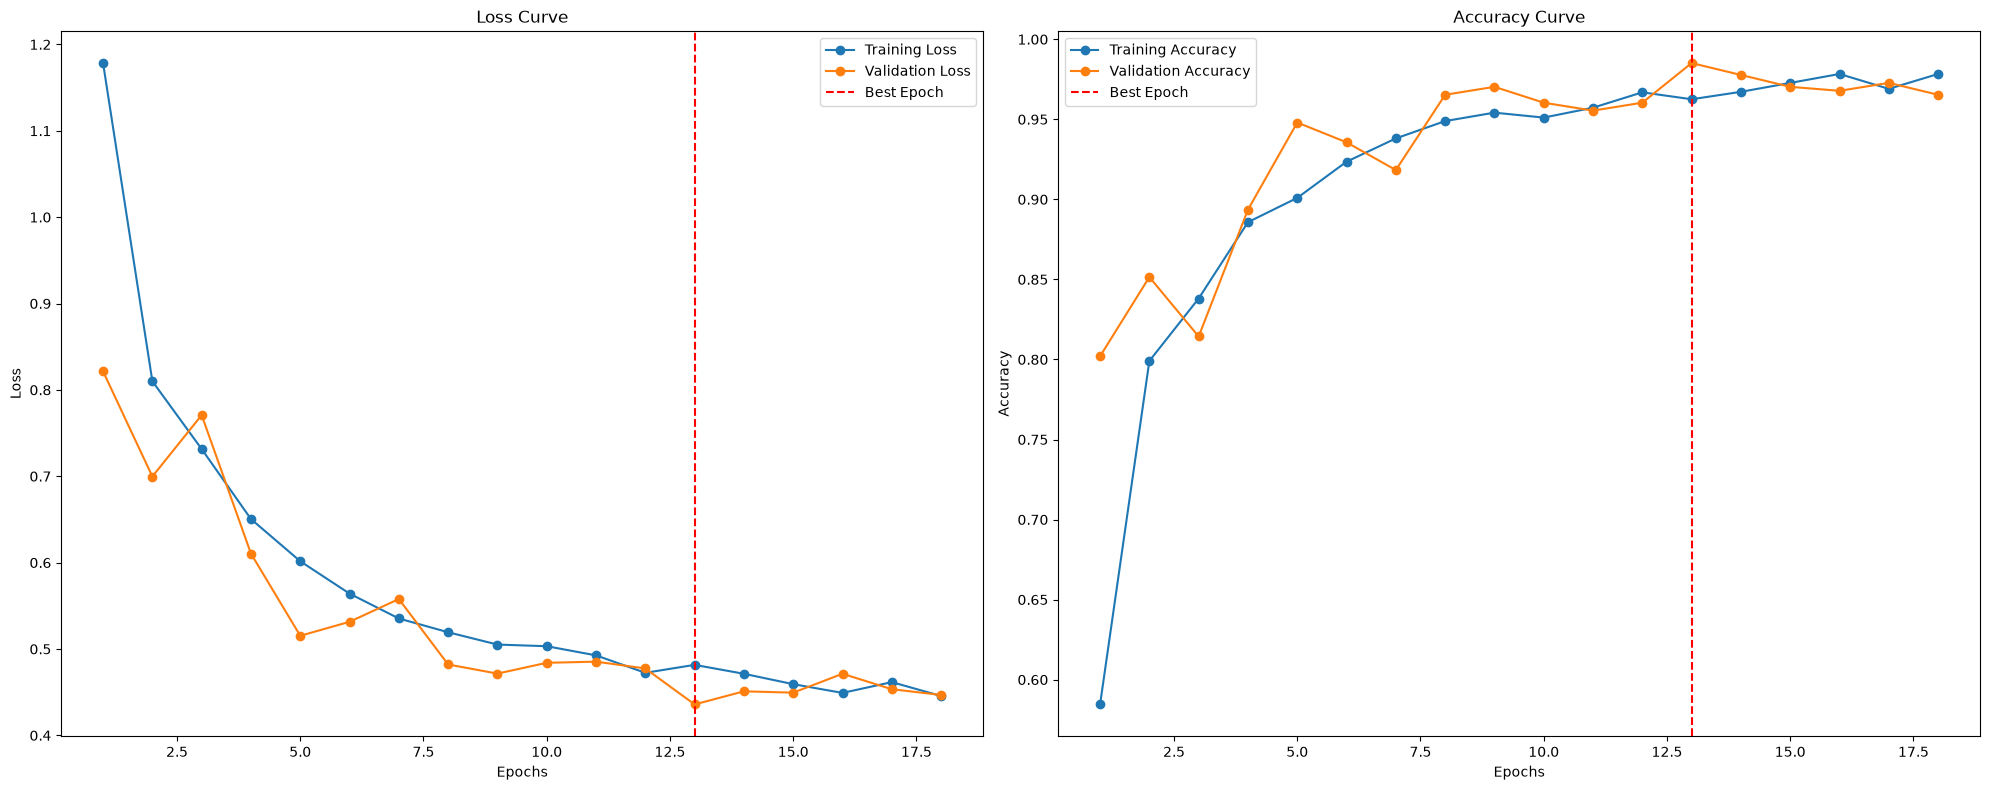


Training Report:
Total training time: 00:06:50
Total epochs run: 18
Best Training Loss: 0.4816 at epoch 13
Best Training Accuracy: 0.9625

Validation Report:
Best Validation Loss: 0.4358 at epoch 13
Best Validation Accuracy: 0.9851
Final Validation Loss: 0.4468
Final Validation Accuracy: 0.9653

Inference Report:
Total Inference Time (Validation only): 00:01:16

Evaluating final metrics for 3. w/o LBSA (No Boundary Attn)...
Accuracy:    0.96535
Recall:      0.95456
Precision:   0.95314
F1 Score:    0.95257
MCC:         0.95335
PR AUC:      0.99699
Kappa:       0.95294
Specificity: 0.99149
✅ Finished 3. w/o LBSA (No Boundary Attn).

🚀 Running Ablation Variant: 4. w/o GLocalHead (GAP fallback)

Epoch 1/30
------------------------------


Validation Loss: 0.8782, Validation Accuracy: 0.7946
Training Loss: 1.1050, Training Accuracy: 0.6300

Epoch 2/30
------------------------------


Validation Loss: 0.7236, Validation Accuracy: 0.8441
Training Loss: 0.8092, Training Accuracy: 0.8028

Epoch 3/30
------------------------------


Validation Loss: 0.6949, Validation Accuracy: 0.8738
Training Loss: 0.6884, Training Accuracy: 0.8641

Epoch 4/30
------------------------------


Validation Loss: 1.1053, Validation Accuracy: 0.6040
Training Loss: 0.6422, Training Accuracy: 0.8876
Patience Counter: 1/5

Epoch 5/30
------------------------------


...

Validation Loss: 0.4189, Validation Accuracy: 0.9901
Training Loss: 0.4148, Training Accuracy: 0.9923
Patience Counter: 2/5

Epoch 27/30
------------------------------


Validation Loss: 0.4134, Validation Accuracy: 0.9926
Training Loss: 0.4146, Training Accuracy: 0.9935

Epoch 28/30
------------------------------


Validation Loss: 0.4175, Validation Accuracy: 0.9901
Training Loss: 0.4169, Training Accuracy: 0.9916
Patience Counter: 1/5

Epoch 29/30
------------------------------


Validation Loss: 0.4161, Validation Accuracy: 0.9901
Training Loss: 0.4128, Training Accuracy: 0.9944
Patience Counter: 2/5

Epoch 30/30
------------------------------


Validation Loss: 0.4161, Validation Accuracy: 0.9901
Training Loss: 0.4170, Training Accuracy: 0.9923
Patience Counter: 3/5


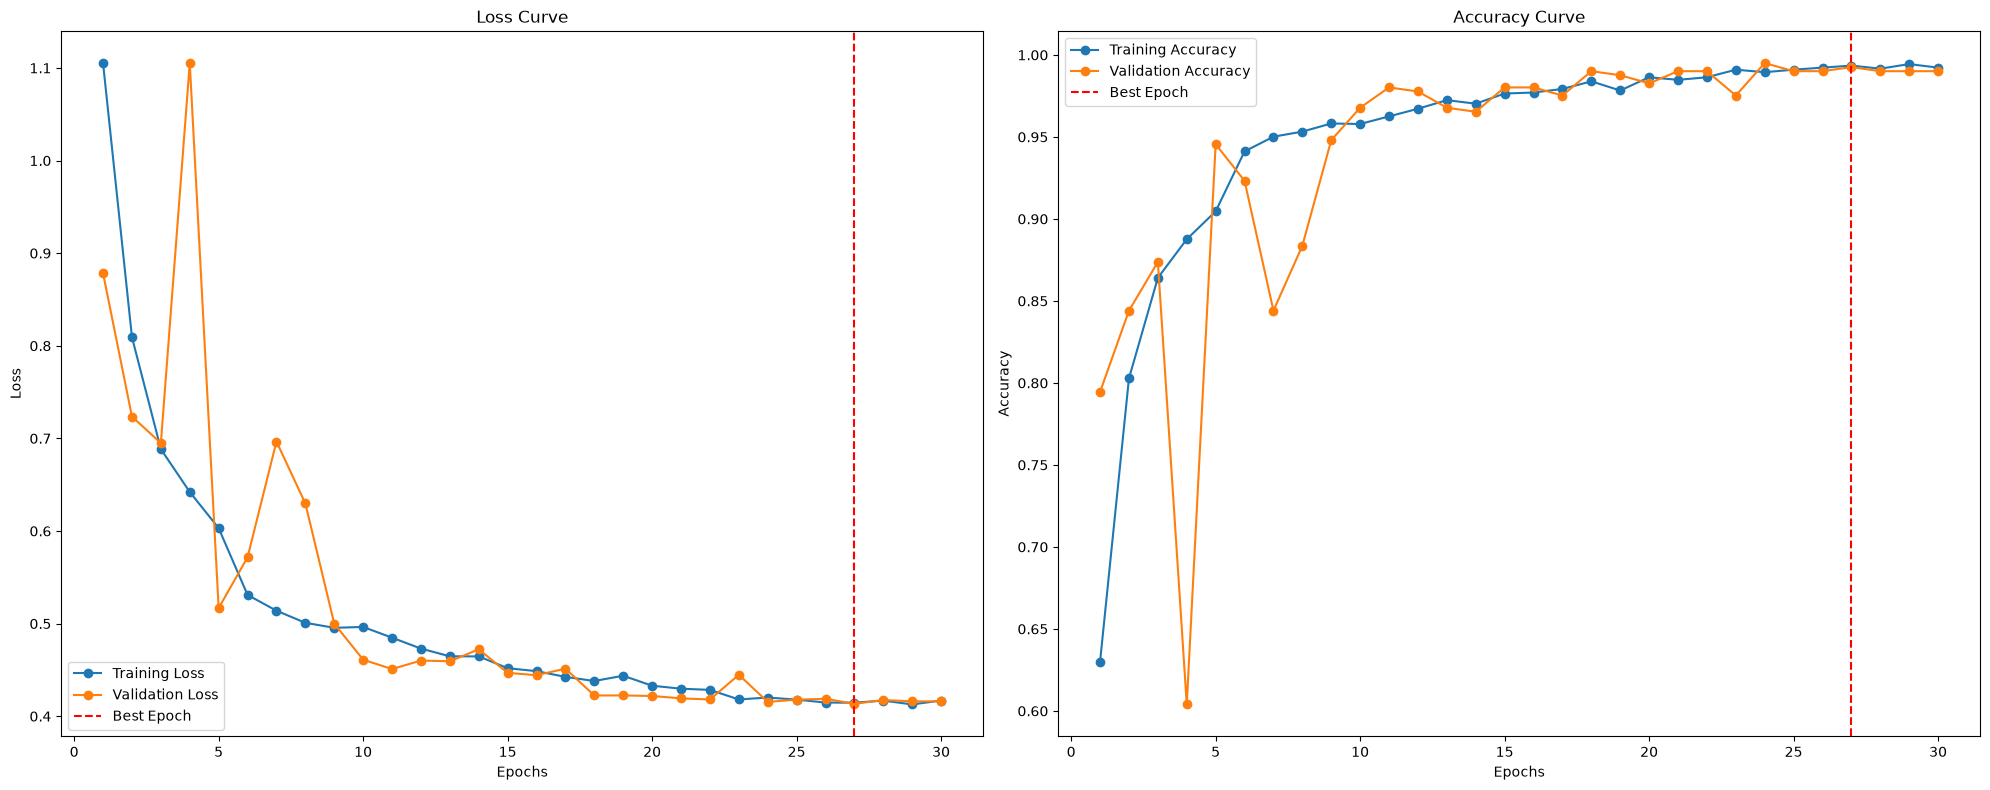


Training Report:
Total training time: 00:13:35
Total epochs run: 30
Best Training Loss: 0.4146 at epoch 27
Best Training Accuracy: 0.9935

Validation Report:
Best Validation Loss: 0.4134 at epoch 27
Best Validation Accuracy: 0.9926
Final Validation Loss: 0.4161
Final Validation Accuracy: 0.9901

Inference Report:
Total Inference Time (Validation only): 00:02:16

Evaluating final metrics for 4. w/o GLocalHead (GAP fallback)...
Accuracy:    0.99010
Recall:      0.98667
Precision:   0.98518
F1 Score:    0.98545
MCC:         0.98666
PR AUC:      0.99896
Kappa:       0.98655
Specificity: 0.99750
✅ Finished 4. w/o GLocalHead (GAP fallback).

🚀 Running Ablation Variant: 5. w/o LayerScale & DropPath

Epoch 1/30
------------------------------


Validation Loss: 1.2500, Validation Accuracy: 0.5941
Training Loss: 1.4851, Training Accuracy: 0.4022

Epoch 2/30
------------------------------


Validation Loss: 0.9419, Validation Accuracy: 0.7327
Training Loss: 1.1027, Training Accuracy: 0.6313

Epoch 3/30
------------------------------


Validation Loss: 0.8123, Validation Accuracy: 0.8119
Training Loss: 0.9308, Training Accuracy: 0.7350

Epoch 4/30
------------------------------


Validation Loss: 0.8412, Validation Accuracy: 0.7599
Training Loss: 0.8337, Training Accuracy: 0.7882
Patience Counter: 1/5

Epoch 5/30
------------------------------


...

Validation Loss: 0.4823, Validation Accuracy: 0.9480
Training Loss: 0.4782, Training Accuracy: 0.9632
Patience Counter: 1/5

Epoch 27/30
------------------------------


Validation Loss: 0.4857, Validation Accuracy: 0.9480
Training Loss: 0.4893, Training Accuracy: 0.9526
Patience Counter: 2/5

Epoch 28/30
------------------------------


Validation Loss: 0.4852, Validation Accuracy: 0.9554
Training Loss: 0.4604, Training Accuracy: 0.9731
Patience Counter: 3/5

Epoch 29/30
------------------------------


Validation Loss: 0.4842, Validation Accuracy: 0.9406
Training Loss: 0.4691, Training Accuracy: 0.9669
Patience Counter: 4/5

Epoch 30/30
------------------------------


Validation Loss: 0.4792, Validation Accuracy: 0.9530
Training Loss: 0.4645, Training Accuracy: 0.9666


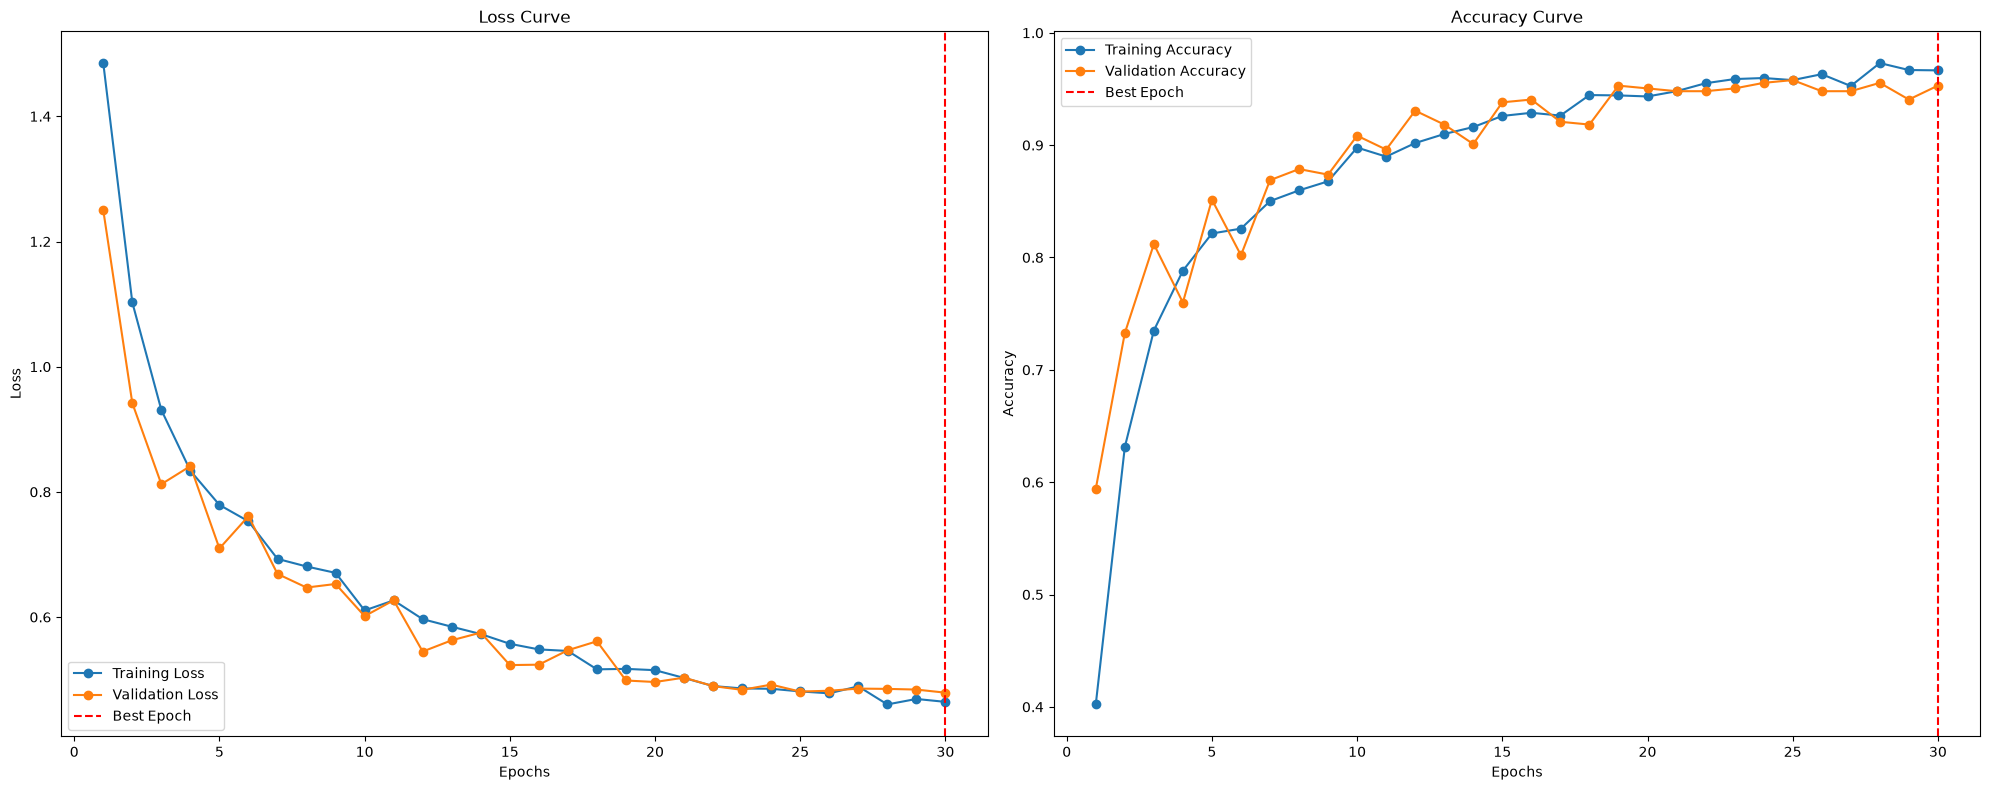


Training Report:
Total training time: 00:11:34
Total epochs run: 30
Best Training Loss: 0.4645 at epoch 30
Best Training Accuracy: 0.9666

Validation Report:
Best Validation Loss: 0.4792 at epoch 30
Best Validation Accuracy: 0.9530
Final Validation Loss: 0.4792
Final Validation Accuracy: 0.9530

Inference Report:
Total Inference Time (Validation only): 00:02:09

Evaluating final metrics for 5. w/o LayerScale & DropPath...
Accuracy:    0.95297
Recall:      0.94610
Precision:   0.94325
F1 Score:    0.94409
MCC:         0.93639
PR AUC:      0.99172
Kappa:       0.93623
Specificity: 0.98809
✅ Finished 5. w/o LayerScale & DropPath.

🎯 ABLATION STUDY SUMMARY REPORT
Variant Name                           | Params (M)
-----------------------------------------------------------------
3. w/o LBSA (No Boundary Attn)         | 3.90M
4. w/o GLocalHead (GAP fallback)       | 3.82M
5. w/o LayerScale & DropPath           | 3.90M


In [61]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR

# ══════════════════════════════════════════════════════════════════════════════
# 1. Helper Functions (Initialization & Parameter Grouping)
# ══════════════════════════════════════════════════════════════════════════════
def init_weights(m):
    if isinstance(m, nn.Conv2d):
        nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, (nn.BatchNorm2d, nn.LayerNorm)):
        nn.init.ones_(m.weight)
        if hasattr(m, 'bias') and m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, nn.Linear):
        nn.init.trunc_normal_(m.weight, std=0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)

def get_parameter_groups(model, weight_decay=1e-2):
    decay = []
    no_decay = []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        # Exclude 1D parameters (LayerScale gamma, BN/LN scale & bias), position bias tables, and biases
        if param.ndim <= 1 or 'relative_position_bias_table' in name or 'bias' in name:
            no_decay.append(param)
        else:
            decay.append(param)
    return [
        {'params': decay, 'weight_decay': weight_decay},
        {'params': no_decay, 'weight_decay': 0.0}
    ]

def load_ablation_model(num_classes, device, kwargs):
    # Initializes the toggleable ablation model with custom kwargs
    model = LightNeStV2Ablation(num_classes=num_classes, **kwargs)
    model.apply(init_weights)
    return model.to(device)

def count_parameters_m(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6

# ══════════════════════════════════════════════════════════════════════════════
# 2. Comprehensive Ablation Configurations (Including LayerScale & DropPath)
# ══════════════════════════════════════════════════════════════════════════════
ablation_configs = {
    "3. w/o LBSA (No Boundary Attn)": {
        "use_asep": True, "use_lbsa": False, "use_glocal": True, "use_layerscale": True, "use_droppath": True
    },
    "4. w/o GLocalHead (GAP fallback)": {
        "use_asep": True, "use_lbsa": True, "use_glocal": False, "use_layerscale": True, "use_droppath": True
    },
    "5. w/o LayerScale & DropPath": {
        "use_asep": True, "use_lbsa": True, "use_glocal": True, "use_layerscale": False, "use_droppath": False
    }
}

# ══════════════════════════════════════════════════════════════════════════════
# 3. Execution Loop
# ══════════════════════════════════════════════════════════════════════════════
num_classes = len(label_mapping)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
total_epochs = 30
warmup_epochs = 3

ablation_results = {}

print(f"Starting Ablation Study on {device}...\n" + "="*65)

for variant_name, kwargs in ablation_configs.items():
    print(f"\n==========================================")
    print(f"🚀 Running Ablation Variant: {variant_name}")
    print(f"==========================================")
    
    # 1. Load Model with current ablation configuration
    model = load_ablation_model(num_classes, device, kwargs)
    
    # 2. Count Trainable Parameters
    params_m = count_parameters_m(model)
    
    # 3. Initialize Loss, Parameter Groups, and Optimizer
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    param_groups = get_parameter_groups(model, weight_decay=0.02)
    optimizer = optim.AdamW(param_groups, lr=5e-4)
    
    # 4. Initialize Warmup + Cosine Annealing Schedulers
    warmup_scheduler = LinearLR(
        optimizer, start_factor=0.1, end_factor=1.0, total_iters=warmup_epochs
    )
    cosine_scheduler = CosineAnnealingLR(
        optimizer, T_max=total_epochs - warmup_epochs, eta_min=1e-6
    )
    scheduler = SequentialLR(
        optimizer,
        schedulers=[warmup_scheduler, cosine_scheduler],
        milestones=[warmup_epochs]
    )
    
    # 5. Train Model using your custom training pipeline
    train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion,
        optimizer=optimizer,
        scheduler=scheduler,
        num_epochs=total_epochs,
        patience=5,
        min_delta=0.001,
    )

    # 6. Evaluate Final Metrics using your custom evaluation function
    print(f"\nEvaluating final metrics for {variant_name}...")
    metrics = evaluate_model_with_metrics(model, val_loader)
    metrics["params_m"] = params_m

    ablation_results[variant_name] = metrics
    print(f"✅ Finished {variant_name}.")


# ══════════════════════════════════════════════════════════════════════════════
# 4. Summary Output Report
# ══════════════════════════════════════════════════════════════════════════════
print("\n" + "="*65)
print("🎯 ABLATION STUDY SUMMARY REPORT")
print("="*65)
print(f"{'Variant Name':<38} | {'Params (M)'}")
print("-" * 65)

for variant_name, res in ablation_results.items():
    print(f"{variant_name:<38} | {res['params_m']:.2f}M")

print("="*65)

In [62]:

header = f"{'Variant':<20} | {'Accuracy':<8}  | {'PR AUC':<8} | {'MCC':<8}| {'Specificity':<8}"
print(header)
print("-" * len(header))

for variant, mets in ablation_results.items():
    print(f"{variant:<20} | "
          f"{mets['accuracy']:.4f}   | "
          f"{mets['pr_auc']:.4f}   | "
          f"{mets['mcc']:.4f} | "
          f"{mets['specificity']:.4f}")

print("-" * len(header))

Variant              | Accuracy  | PR AUC   | MCC     | Specificity
-------------------------------------------------------------------
3. w/o LBSA (No Boundary Attn) | 0.9653   | 0.9970   | 0.9534 | 0.9915
4. w/o GLocalHead (GAP fallback) | 0.9901   | 0.9990   | 0.9867 | 0.9975
5. w/o LayerScale & DropPath | 0.9530   | 0.9917   | 0.9364 | 0.9881
-------------------------------------------------------------------


# Merged Dataset


Epoch 1/30
------------------------------


Validation Loss: 0.8165, Validation Accuracy: 0.8373
Training Loss: 1.0416, Training Accuracy: 0.7208

Epoch 2/30
------------------------------


Validation Loss: 0.6975, Validation Accuracy: 0.8929
Training Loss: 0.8079, Training Accuracy: 0.8403

Epoch 3/30
------------------------------


Validation Loss: 0.6855, Validation Accuracy: 0.8909
Training Loss: 0.7015, Training Accuracy: 0.8923

Epoch 4/30
------------------------------


Validation Loss: 0.6292, Validation Accuracy: 0.9226
Training Loss: 0.6250, Training Accuracy: 0.9257

Epoch 5/30
------------------------------


...

Validation Loss: 0.4781, Validation Accuracy: 0.9881
Training Loss: 0.4494, Training Accuracy: 0.9996
Patience Counter: 1/5

Epoch 23/30
------------------------------


Validation Loss: 0.4843, Validation Accuracy: 0.9841
Training Loss: 0.4495, Training Accuracy: 0.9994
Patience Counter: 2/5

Epoch 24/30
------------------------------


Validation Loss: 0.4836, Validation Accuracy: 0.9861
Training Loss: 0.4500, Training Accuracy: 0.9993
Patience Counter: 3/5

Epoch 25/30
------------------------------


Validation Loss: 0.4766, Validation Accuracy: 0.9861
Training Loss: 0.4483, Training Accuracy: 0.9999
Patience Counter: 4/5

Epoch 26/30
------------------------------


Validation Loss: 0.4747, Validation Accuracy: 0.9881
Training Loss: 0.4483, Training Accuracy: 0.9999
Patience Counter: 5/5
Early stopping triggered at epoch 26.


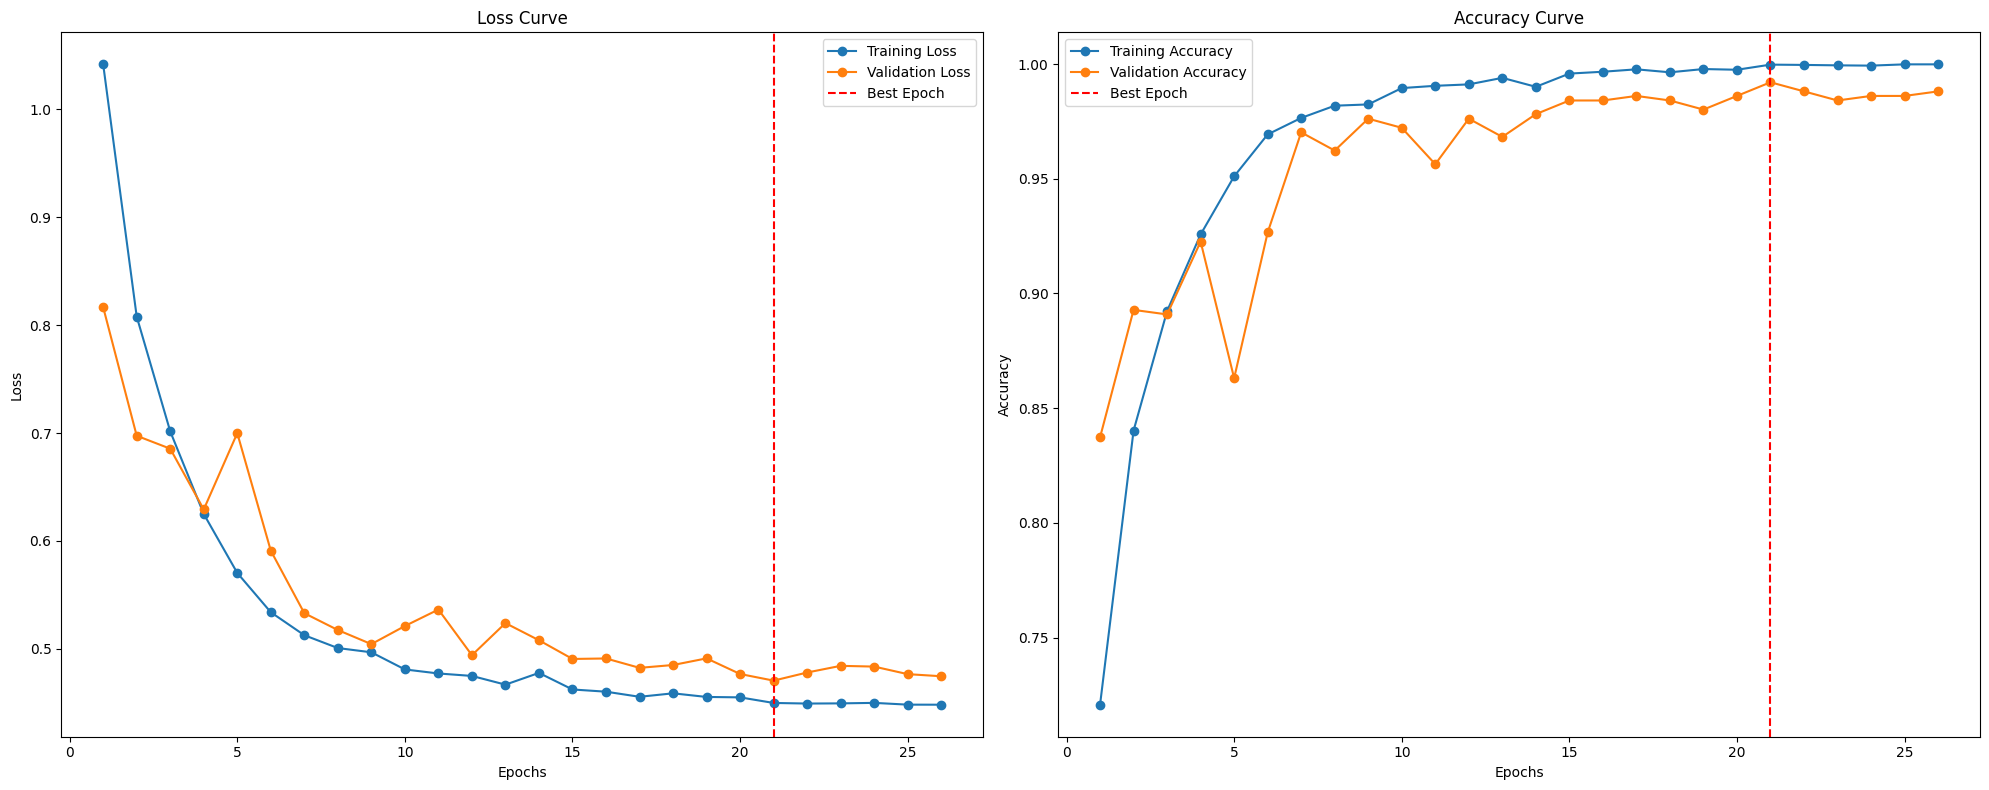


Training Report:
Total training time: 00:31:18
Total epochs run: 26
Best Training Loss: 0.4499 at epoch 21
Best Training Accuracy: 0.9998

Validation Report:
Best Validation Loss: 0.4706 at epoch 21
Best Validation Accuracy: 0.9921
Final Validation Loss: 0.4747
Final Validation Accuracy: 0.9881

Inference Report:
Total Inference Time (Validation only): 00:01:40


In [56]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)


Epoch 1/30
------------------------------


Validation Loss: 0.9835, Validation Accuracy: 0.7619
Training Loss: 1.2923, Training Accuracy: 0.5897

Epoch 2/30
------------------------------


Validation Loss: 0.9285, Validation Accuracy: 0.7758
Training Loss: 1.0052, Training Accuracy: 0.7398

Epoch 3/30
------------------------------


Validation Loss: 0.9789, Validation Accuracy: 0.7560
Training Loss: 0.9073, Training Accuracy: 0.7941
Patience Counter: 1/5

Epoch 4/30
------------------------------


Validation Loss: 0.7628, Validation Accuracy: 0.8651
Training Loss: 0.8603, Training Accuracy: 0.8132

Epoch 5/30
------------------------------


...

Validation Loss: 0.4966, Validation Accuracy: 0.9782
Training Loss: 0.4830, Training Accuracy: 0.9889
Patience Counter: 1/5

Epoch 27/30
------------------------------


Validation Loss: 0.4814, Validation Accuracy: 0.9841
Training Loss: 0.4788, Training Accuracy: 0.9921

Epoch 28/30
------------------------------


Validation Loss: 0.4864, Validation Accuracy: 0.9821
Training Loss: 0.4791, Training Accuracy: 0.9908
Patience Counter: 1/5

Epoch 29/30
------------------------------


Validation Loss: 0.4885, Validation Accuracy: 0.9821
Training Loss: 0.4769, Training Accuracy: 0.9916
Patience Counter: 2/5

Epoch 30/30
------------------------------


Validation Loss: 0.4901, Validation Accuracy: 0.9782
Training Loss: 0.4717, Training Accuracy: 0.9941
Patience Counter: 3/5


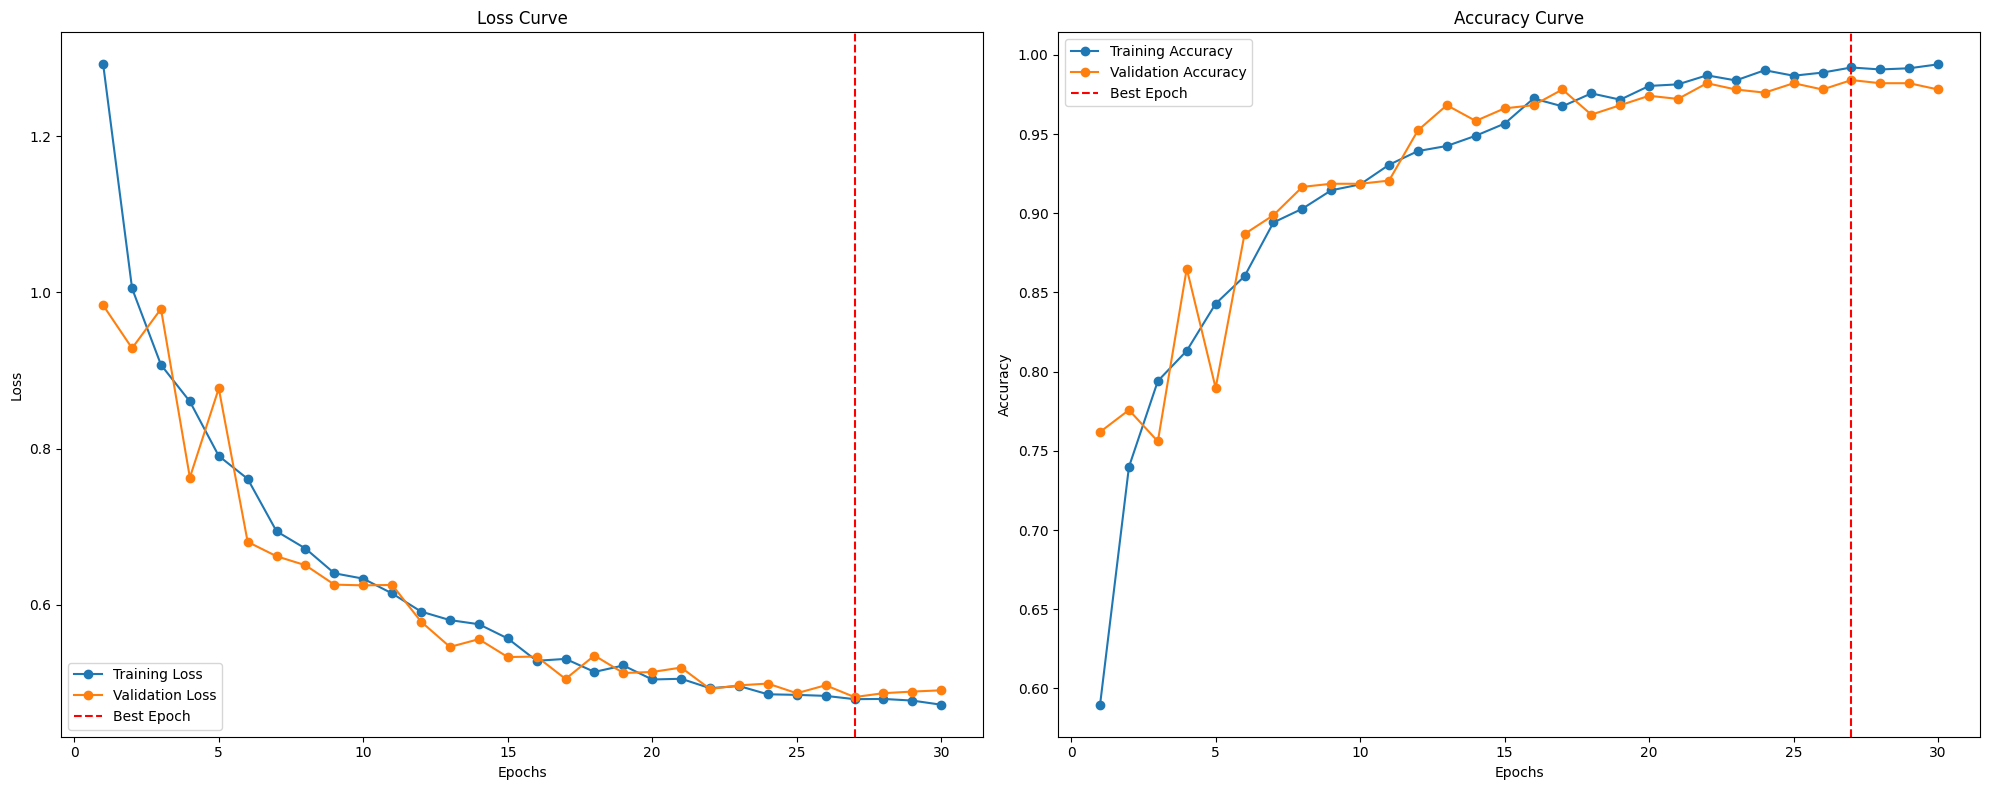


Training Report:
Total training time: 00:13:29
Total epochs run: 30
Best Training Loss: 0.4788 at epoch 27
Best Training Accuracy: 0.9921

Validation Report:
Best Validation Loss: 0.4814 at epoch 27
Best Validation Accuracy: 0.9841
Final Validation Loss: 0.4901
Final Validation Accuracy: 0.9782

Inference Report:
Total Inference Time (Validation only): 00:02:01


In [16]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [17]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.98614
Recall:      0.98614
Precision:   0.98650
F1 Score:    0.98617
MCC:         0.98214
PR AUC:      0.99576
Kappa:       0.98209
Specificity: 0.99758


Accuracy: 0.9861
                      precision    recall  f1-score   support

       Yellow Mosaic       0.99      0.99      0.99       191
        Leaf Crinkle       1.00      0.98      0.99        96
         Anthracnose       1.00      0.96      0.98        23
              Insect       0.98      0.98      0.98        41
Cercospora leaf spot       0.98      0.97      0.97        59
             Healthy       0.95      1.00      0.97        77
      Powdery Mildew       1.00      1.00      1.00        18

            accuracy                           0.99       505
           macro avg       0.99      0.98      0.98       505
        weighted avg       0.99      0.99      0.99       505



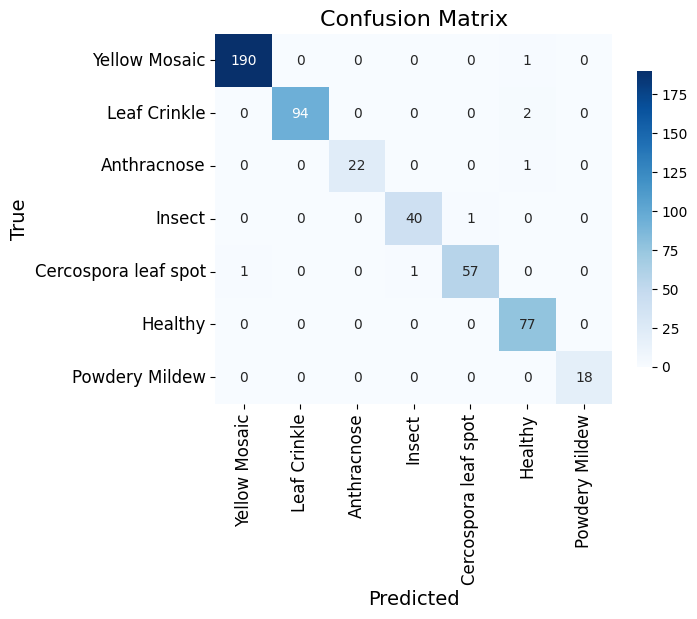

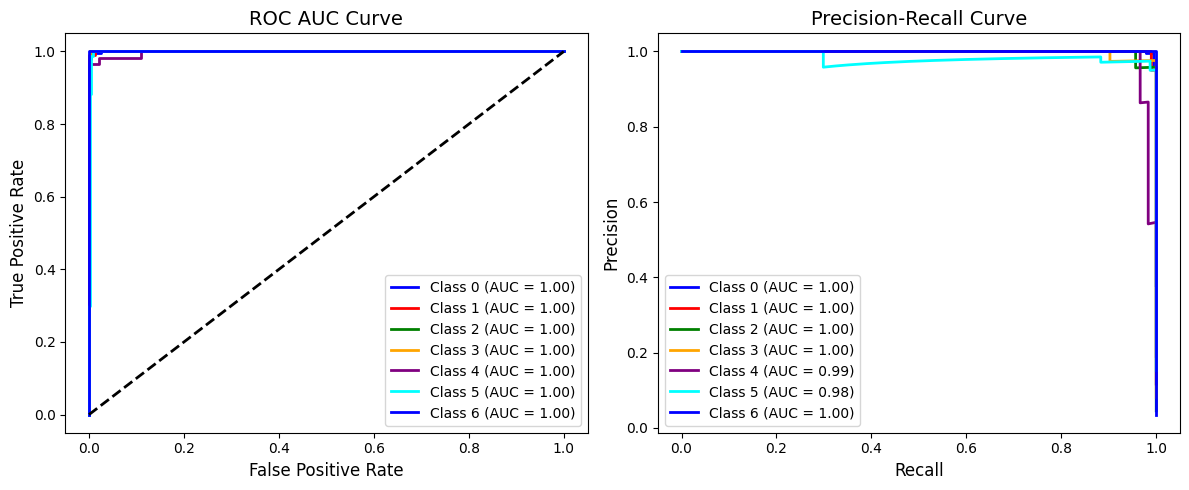

In [18]:
evaluate_model(model, test_loader, label_mapping)


Epoch 1/30
------------------------------


Validation Loss: 1.2528, Validation Accuracy: 0.5317
Training Loss: 1.5036, Training Accuracy: 0.4145

Epoch 2/30
------------------------------


Validation Loss: 0.7748, Validation Accuracy: 0.7242
Training Loss: 0.9947, Training Accuracy: 0.6343

Epoch 3/30
------------------------------


Validation Loss: 0.6641, Validation Accuracy: 0.7639
Training Loss: 0.7075, Training Accuracy: 0.7302

Epoch 4/30
------------------------------


Validation Loss: 0.4966, Validation Accuracy: 0.8214
Training Loss: 0.5770, Training Accuracy: 0.7834

Epoch 5/30
------------------------------


...

Validation Loss: 0.1591, Validation Accuracy: 0.9484
Training Loss: 0.0785, Training Accuracy: 0.9705

Epoch 27/30
------------------------------


Validation Loss: 0.1528, Validation Accuracy: 0.9464
Training Loss: 0.0722, Training Accuracy: 0.9730

Epoch 28/30
------------------------------


Validation Loss: 0.1490, Validation Accuracy: 0.9444
Training Loss: 0.0717, Training Accuracy: 0.9750

Epoch 29/30
------------------------------


Validation Loss: 0.1468, Validation Accuracy: 0.9444
Training Loss: 0.0648, Training Accuracy: 0.9792

Epoch 30/30
------------------------------


Validation Loss: 0.1448, Validation Accuracy: 0.9464
Training Loss: 0.0666, Training Accuracy: 0.9804


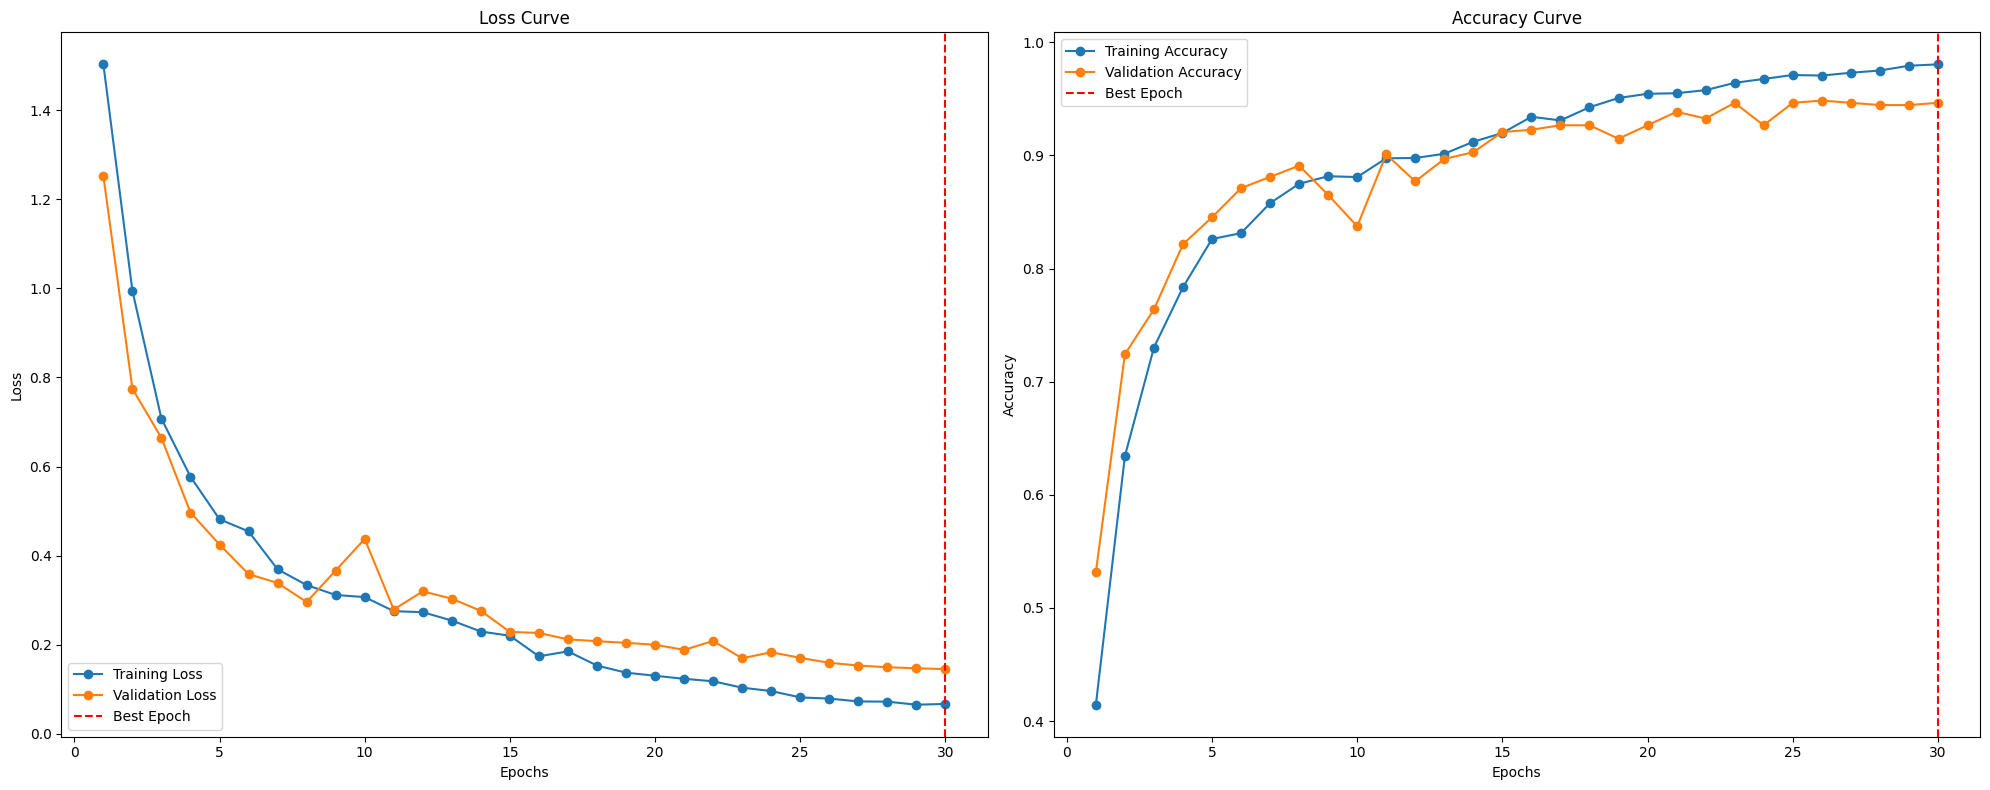


Training Report:
Total training time: 00:16:53
Total epochs run: 30
Best Training Loss: 0.0666 at epoch 30
Best Training Accuracy: 0.9804

Validation Report:
Best Validation Loss: 0.1448 at epoch 30
Best Validation Accuracy: 0.9464
Final Validation Loss: 0.1448
Final Validation Accuracy: 0.9464

Inference Report:
Total Inference Time (Validation only): 00:02:05


In [33]:
import ssl
import urllib
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import timm

ssl._create_default_https_context = ssl._create_unverified_context

# Target model identification
model_name = 'swinv2_cr_tiny_224'
num_classes = len(label_mapping)

# Create SwinV2 model (Set pretrained=True for massive accuracy gains on small leaf datasets)
model = timm.create_model(model_name, pretrained=False, num_classes=num_classes)

# Modify the head properly according to SwinV2's internal architecture structure
if hasattr(model, 'head') and hasattr(model.head, 'fc'):
    in_features = model.head.fc.in_features
    model.head.fc = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )
elif hasattr(model, 'head') and isinstance(model.head, nn.Linear):
    in_features = model.head.in_features
    model.head = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )

model = model.to(device)

# Loss & optimizer (Kept the same, AdamW is great for Swin architectures)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)

# Scheduler: Cosine Annealing 
scheduler = CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)

# Training execution loop
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)


In [35]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.95644
Recall:      0.95644
Precision:   0.95991
F1 Score:    0.95755
MCC:         0.94394
PR AUC:      0.98938
Kappa:       0.94383
Specificity: 0.99282


In [25]:
torch.cuda.empty_cache()


Epoch 1/30
------------------------------


Validation Loss: 0.9830, Validation Accuracy: 0.6310
Training Loss: 0.9709, Training Accuracy: 0.6432

Epoch 2/30
------------------------------


Validation Loss: 0.5100, Validation Accuracy: 0.8036
Training Loss: 0.6315, Training Accuracy: 0.7671

Epoch 3/30
------------------------------


Validation Loss: 0.5186, Validation Accuracy: 0.8115
Training Loss: 0.5346, Training Accuracy: 0.8025
Patience Counter: 1/5

Epoch 4/30
------------------------------


Validation Loss: 0.6254, Validation Accuracy: 0.7698
Training Loss: 0.5022, Training Accuracy: 0.8122
Patience Counter: 2/5

Epoch 5/30
------------------------------


...

Validation Loss: 0.0957, Validation Accuracy: 0.9702
Training Loss: 0.0783, Training Accuracy: 0.9718

Epoch 27/30
------------------------------


Validation Loss: 0.0969, Validation Accuracy: 0.9702
Training Loss: 0.0733, Training Accuracy: 0.9752
Patience Counter: 1/5

Epoch 28/30
------------------------------


Validation Loss: 0.1081, Validation Accuracy: 0.9742
Training Loss: 0.0747, Training Accuracy: 0.9730
Patience Counter: 2/5

Epoch 29/30
------------------------------


Validation Loss: 0.0956, Validation Accuracy: 0.9782
Training Loss: 0.0681, Training Accuracy: 0.9775
Patience Counter: 3/5

Epoch 30/30
------------------------------


Validation Loss: 0.1010, Validation Accuracy: 0.9782
Training Loss: 0.0704, Training Accuracy: 0.9782
Patience Counter: 4/5


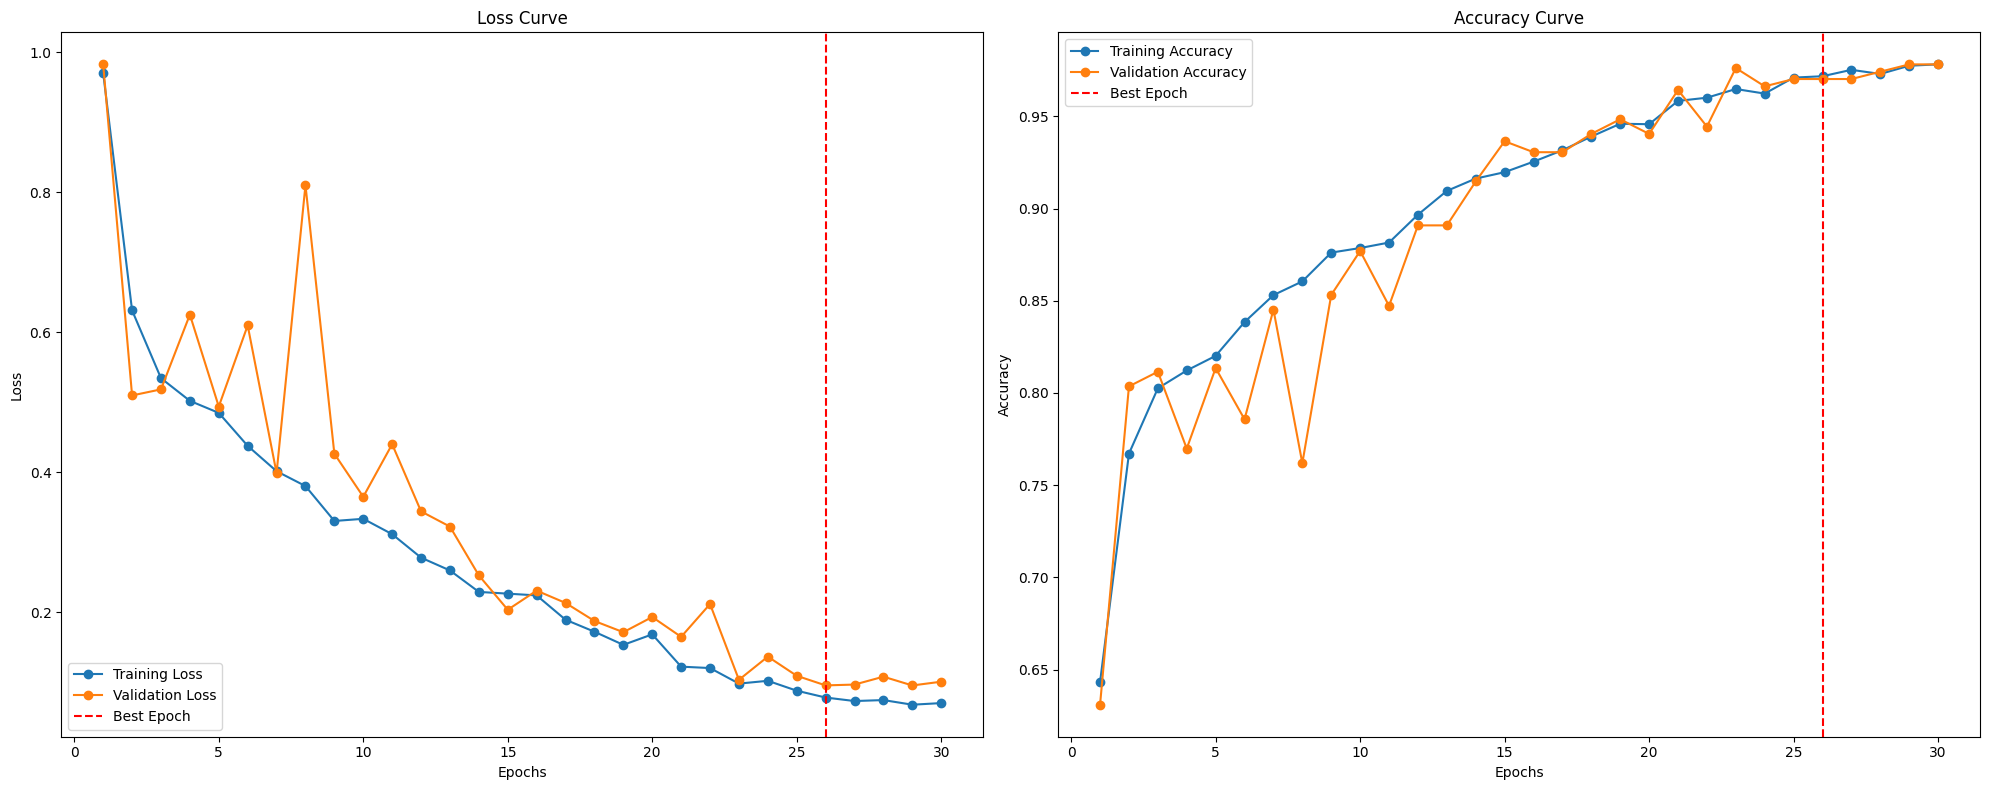


Training Report:
Total training time: 00:14:30
Total epochs run: 30
Best Training Loss: 0.0783 at epoch 26
Best Training Accuracy: 0.9718

Validation Report:
Best Validation Loss: 0.0957 at epoch 26
Best Validation Accuracy: 0.9702
Final Validation Loss: 0.1010
Final Validation Accuracy: 0.9782

Inference Report:
Total Inference Time (Validation only): 00:02:01


In [23]:
import timm

def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)
    
    # Check if the model uses 'classifier' or 'head' as the classification layer
    if hasattr(model, 'classifier'):
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    elif hasattr(model, 'fc'):  # For models like ResNeSt
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    else:
        raise ValueError("Unexpected classifier layer name in model")

    return model


# Number of classes (adjust to your problem)
num_classes = len(label_mapping)  # Replace label_mapping with the actual class labels

# Load EfficientNetV2-M without pre-trained weights
model = load_model("densenet169", num_classes, pretrained=False)

model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
# Define Learning Rate Scheduler (e.g., Cosine Annealing)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)

train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [24]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.97030
Recall:      0.97030
Precision:   0.97091
F1 Score:    0.97045
MCC:         0.96166
PR AUC:      0.99490
Kappa:       0.96162
Specificity: 0.99484



Epoch 1/30
------------------------------


Validation Loss: 0.7672, Validation Accuracy: 0.7004
Training Loss: 0.8683, Training Accuracy: 0.6762

Epoch 2/30
------------------------------


Validation Loss: 0.7866, Validation Accuracy: 0.6964
Training Loss: 0.5344, Training Accuracy: 0.8080
Patience Counter: 1/5

Epoch 3/30
------------------------------


Validation Loss: 0.7608, Validation Accuracy: 0.7242
Training Loss: 0.4785, Training Accuracy: 0.8226

Epoch 4/30
------------------------------


Validation Loss: 0.3042, Validation Accuracy: 0.8948
Training Loss: 0.4280, Training Accuracy: 0.8419

Epoch 5/30
------------------------------


...

Validation Loss: 0.0731, Validation Accuracy: 0.9762
Training Loss: 0.0381, Training Accuracy: 0.9869
Patience Counter: 1/5

Epoch 27/30
------------------------------


Validation Loss: 0.0684, Validation Accuracy: 0.9782
Training Loss: 0.0335, Training Accuracy: 0.9879
Patience Counter: 2/5

Epoch 28/30
------------------------------


Validation Loss: 0.0635, Validation Accuracy: 0.9821
Training Loss: 0.0352, Training Accuracy: 0.9906

Epoch 29/30
------------------------------


Validation Loss: 0.0691, Validation Accuracy: 0.9782
Training Loss: 0.0281, Training Accuracy: 0.9921
Patience Counter: 1/5

Epoch 30/30
------------------------------


Validation Loss: 0.0685, Validation Accuracy: 0.9802
Training Loss: 0.0302, Training Accuracy: 0.9884
Patience Counter: 2/5


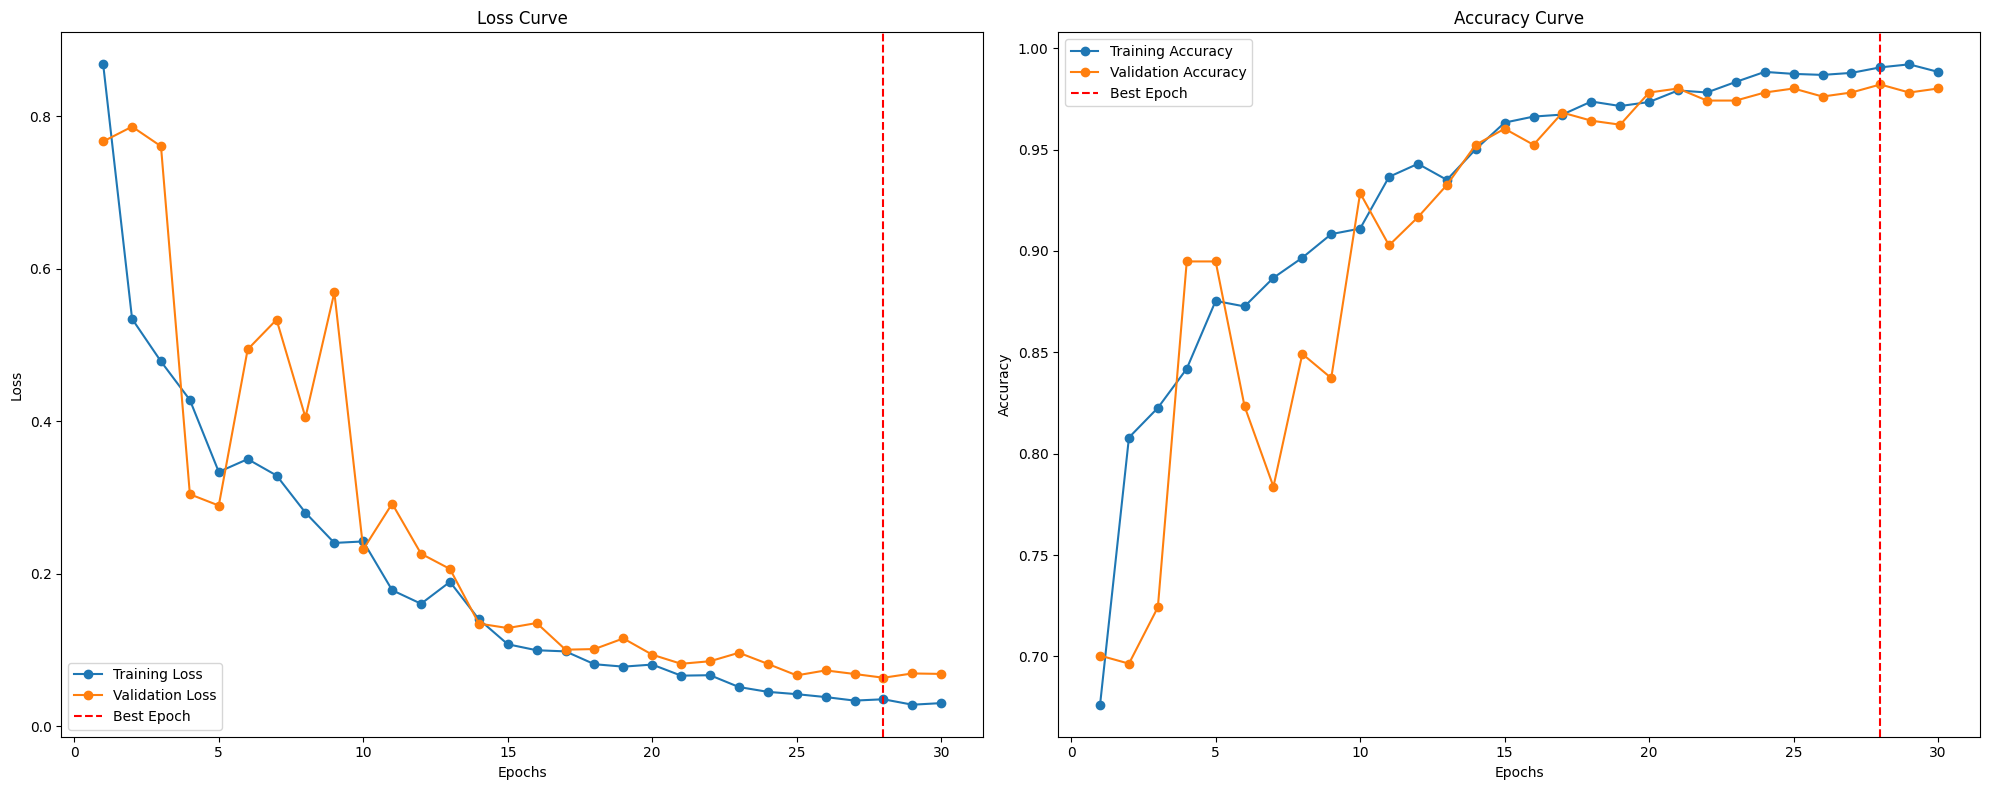


Training Report:
Total training time: 00:15:31
Total epochs run: 30
Best Training Loss: 0.0352 at epoch 28
Best Training Accuracy: 0.9906

Validation Report:
Best Validation Loss: 0.0635 at epoch 28
Best Validation Accuracy: 0.9821
Final Validation Loss: 0.0685
Final Validation Accuracy: 0.9802

Inference Report:
Total Inference Time (Validation only): 00:02:02


In [26]:
import timm

def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)
    
    # Check if the model uses 'classifier' or 'head' as the classification layer
    if hasattr(model, 'classifier'):
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    elif hasattr(model, 'fc'):  # For models like ResNeSt
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1)
        )
    else:
        raise ValueError("Unexpected classifier layer name in model")

    return model


# Number of classes (adjust to your problem)
num_classes = len(label_mapping)  # Replace label_mapping with the actual class labels

# Load EfficientNetV2-M without pre-trained weights
model = load_model("resnest50d", num_classes, pretrained=False)

model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
# Define Learning Rate Scheduler (e.g., Cosine Annealing)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)

train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [27]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.97822
Recall:      0.97822
Precision:   0.97831
F1 Score:    0.97819
MCC:         0.97188
PR AUC:      0.99786
Kappa:       0.97186
Specificity: 0.99623



Epoch 1/30
------------------------------


Validation Loss: 0.7580, Validation Accuracy: 0.6984
Training Loss: 1.1589, Training Accuracy: 0.5491

Epoch 2/30
------------------------------


Validation Loss: 0.7083, Validation Accuracy: 0.7262
Training Loss: 0.8040, Training Accuracy: 0.6866

Epoch 3/30
------------------------------


Validation Loss: 0.6722, Validation Accuracy: 0.7460
Training Loss: 0.7426, Training Accuracy: 0.7178

Epoch 4/30
------------------------------


Validation Loss: 0.6558, Validation Accuracy: 0.7520
Training Loss: 0.6765, Training Accuracy: 0.7351

Epoch 5/30
------------------------------


...

Validation Loss: 0.3366, Validation Accuracy: 0.8810
Training Loss: 0.2512, Training Accuracy: 0.9103
Patience Counter: 1/5

Epoch 26/30
------------------------------


Validation Loss: 0.2990, Validation Accuracy: 0.9008
Training Loss: 0.2351, Training Accuracy: 0.9111
Patience Counter: 2/5

Epoch 27/30
------------------------------


Validation Loss: 0.3036, Validation Accuracy: 0.8929
Training Loss: 0.2290, Training Accuracy: 0.9106
Patience Counter: 3/5

Epoch 28/30
------------------------------


Validation Loss: 0.3358, Validation Accuracy: 0.8810
Training Loss: 0.2311, Training Accuracy: 0.9148
Patience Counter: 4/5

Epoch 29/30
------------------------------


Validation Loss: 0.3063, Validation Accuracy: 0.8929
Training Loss: 0.2102, Training Accuracy: 0.9252
Patience Counter: 5/5
Early stopping triggered at epoch 29.


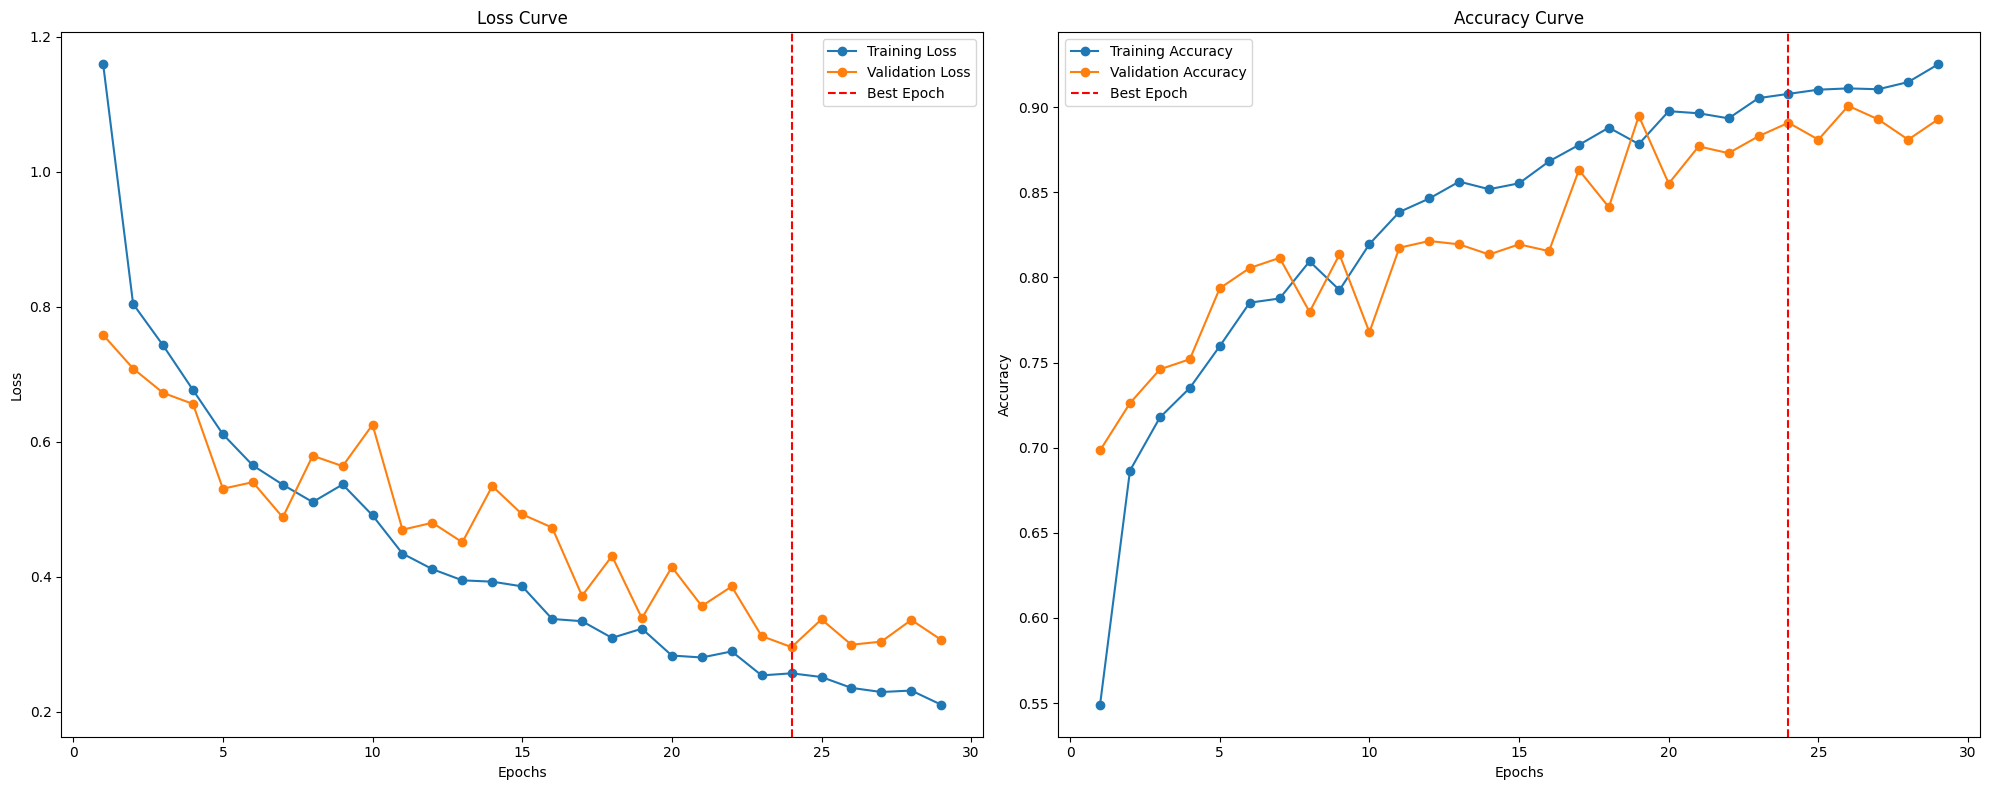


Training Report:
Total training time: 00:08:22
Total epochs run: 29
Best Training Loss: 0.2567 at epoch 24
Best Training Accuracy: 0.9078

Validation Report:
Best Validation Loss: 0.2955 at epoch 24
Best Validation Accuracy: 0.8909
Final Validation Loss: 0.3063
Final Validation Accuracy: 0.8929

Inference Report:
Total Inference Time (Validation only): 00:01:48


In [28]:
import timm
import torch
import torch.nn as nn

def load_custom_timm_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)
    
    # Get original feature dimension dynamically
    in_features = model.get_classifier().in_features
    
    # Build custom head WITHOUT LogSoftmax
    custom_head = nn.Sequential(
        nn.Linear(in_features, 512),
        nn.BatchNorm1d(512),
        nn.ReLU(),
        nn.Dropout(0.4),
        nn.Linear(512, num_classes)
        # Raw logits output required for CrossEntropyLoss
    )
    
    # Safely assign the custom head using timm's official API
    model.reset_classifier(num_classes=0) # Removes default head
    
    if hasattr(model, 'classifier'):
        model.classifier = custom_head
    elif hasattr(model, 'fc'):
        model.fc = custom_head
    elif hasattr(model, 'head'):
        model.head = custom_head
    else:
        model.reset_classifier(num_classes=num_classes)
        
    return model.to(device)

# Load MobileNetV3-Large 1.0x
model = load_custom_timm_model("mobilenetv4_conv_small", num_classes=len(label_mapping))

# Standard Loss (Outputs raw logits from timm, CrossEntropy handles LogSoftmax internally)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
# Define Learning Rate Scheduler (e.g., Cosine Annealing)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)

train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [29]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.91089
Recall:      0.91089
Precision:   0.91730
F1 Score:    0.91172
MCC:         0.88633
PR AUC:      0.97488
Kappa:       0.88536
Specificity: 0.98549



Epoch 1/30
------------------------------


Validation Loss: 0.8381, Validation Accuracy: 0.6845
Training Loss: 1.0206, Training Accuracy: 0.6487

Epoch 2/30
------------------------------


Validation Loss: 0.6168, Validation Accuracy: 0.7579
Training Loss: 0.6391, Training Accuracy: 0.7654

Epoch 3/30
------------------------------


Validation Loss: 0.4854, Validation Accuracy: 0.8155
Training Loss: 0.5557, Training Accuracy: 0.8015

Epoch 4/30
------------------------------


Validation Loss: 0.7052, Validation Accuracy: 0.7341
Training Loss: 0.4714, Training Accuracy: 0.8258
Patience Counter: 1/5

Epoch 5/30
------------------------------


...

Validation Loss: 0.2197, Validation Accuracy: 0.9246
Training Loss: 0.1112, Training Accuracy: 0.9626
Patience Counter: 1/5

Epoch 27/30
------------------------------


Validation Loss: 0.2135, Validation Accuracy: 0.9246
Training Loss: 0.1034, Training Accuracy: 0.9651
Patience Counter: 2/5

Epoch 28/30
------------------------------


Validation Loss: 0.1963, Validation Accuracy: 0.9226
Training Loss: 0.0980, Training Accuracy: 0.9670
Patience Counter: 3/5

Epoch 29/30
------------------------------


Validation Loss: 0.1853, Validation Accuracy: 0.9286
Training Loss: 0.0984, Training Accuracy: 0.9673

Epoch 30/30
------------------------------


Validation Loss: 0.1853, Validation Accuracy: 0.9266
Training Loss: 0.0956, Training Accuracy: 0.9670
Patience Counter: 1/5


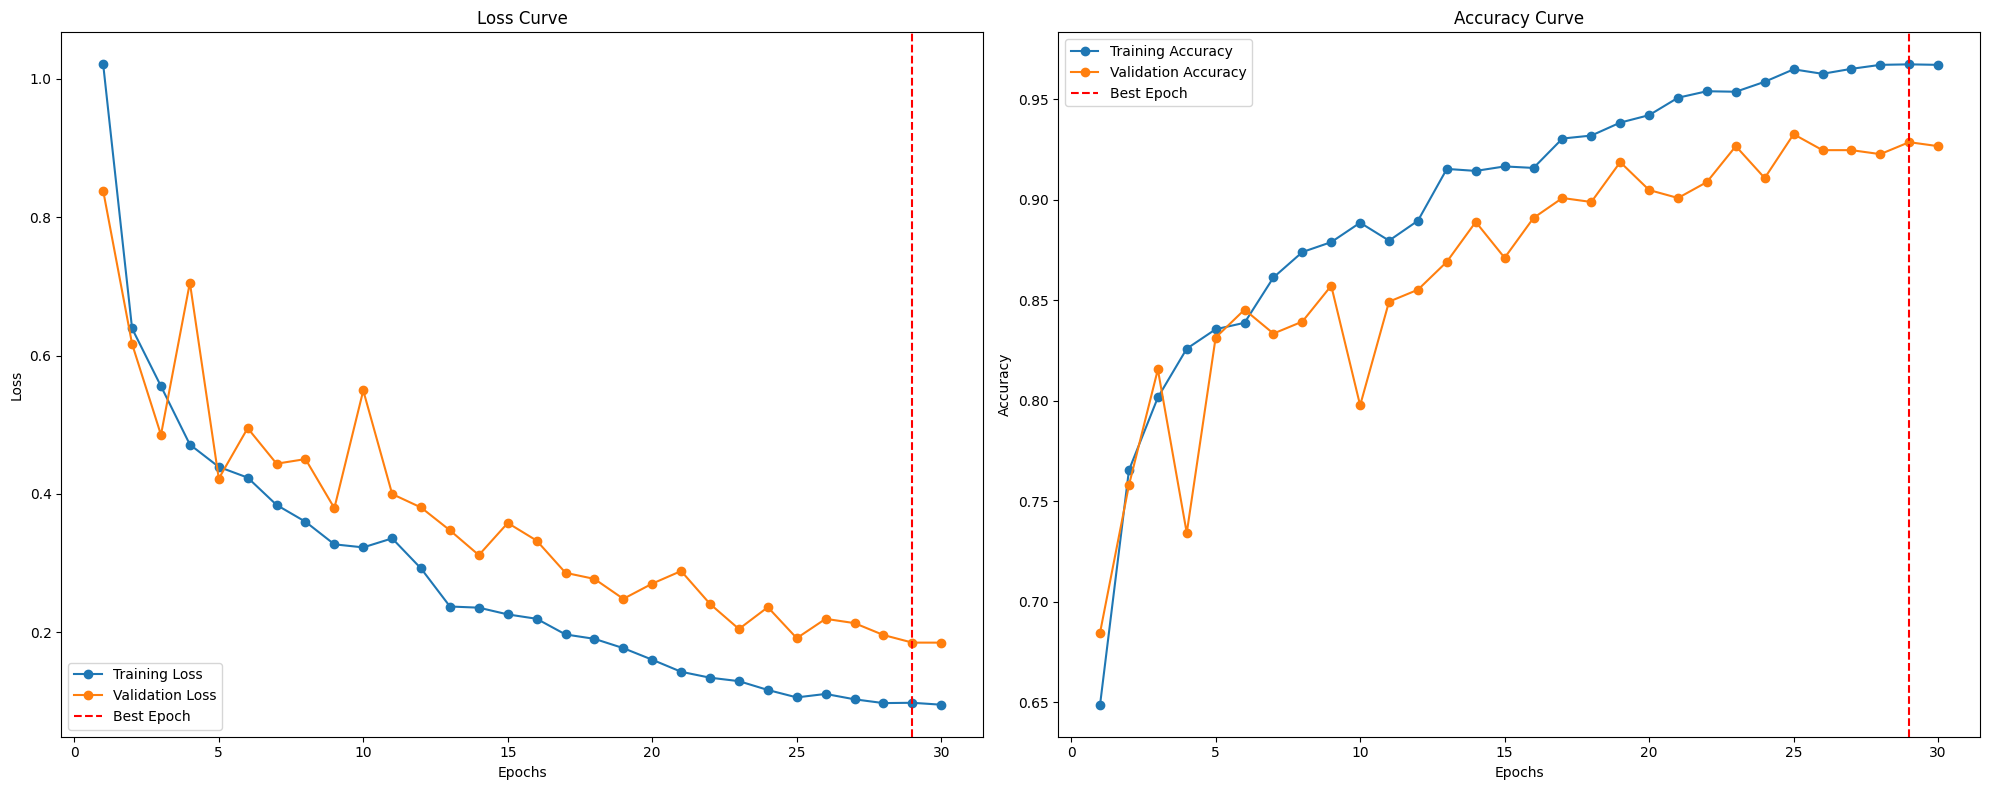


Training Report:
Total training time: 00:09:18
Total epochs run: 30
Best Training Loss: 0.0984 at epoch 29
Best Training Accuracy: 0.9673

Validation Report:
Best Validation Loss: 0.1853 at epoch 29
Best Validation Accuracy: 0.9286
Final Validation Loss: 0.1853
Final Validation Accuracy: 0.9266

Inference Report:
Total Inference Time (Validation only): 00:01:53


In [30]:
import ssl, urllib
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import timm

ssl._create_default_https_context = ssl._create_unverified_context

# Create LeViT (pick size: levit_128s / 128 / 192 / 256)
num_classes = len(label_mapping)
model = timm.create_model('efficientvit_m3', pretrained=False, num_classes=num_classes)

if hasattr(model, 'head') and isinstance(model.head, nn.Linear):
    in_features = model.head.in_features
    model.head = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )
    
model = model.to(device)

# Loss & optimizer|
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)

# Scheduler: Cosine Annealing
# T_max = total number of epochs (full cycle)
scheduler = CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)

train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [32]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.94851
Recall:      0.94851
Precision:   0.95127
F1 Score:    0.94891
MCC:         0.93415
PR AUC:      0.98728
Kappa:       0.93385
Specificity: 0.99161


In [ ]:
model.load_state_dict(torch.load("ProposedBeanModel100.pth"))

In [31]:
model.load_state_dict(torch.load("ProposedBean2.pth"))

<All keys matched successfully>

# Model Calibration result

In [13]:
"""
Model calibration evaluation for journal-quality reporting.

Fixes vs. the original version:
  1. Reports BOTH standard equal-width ECE/MCE (the number almost every
     paper reports, needed for direct comparison with prior work) AND
     adaptive equal-mass ECE/MCE (more robust to sparse high-confidence bins).
  2. Adds bootstrap confidence intervals for ECE, MCE, Brier, and NLL.
  3. Reliability diagram uses the standard stacked-bar style (accuracy bar +
     hatched confidence gap up to the diagonal), which reviewers recognize
     from Guo et al. (2017), shown side-by-side for both binning schemes.
  4. Explicitly documents that this is TOP-LABEL calibration (calibration of
     the arg-max prediction), not full per-class calibration -- state this
     scope in your methods text.
"""

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss


# --------------------------------------------------------------------------
# Core, reusable metric computation (used both for the point estimate and
# for every bootstrap resample, so there is exactly one implementation to
# trust).
# --------------------------------------------------------------------------
def _compute_ece_mce(confidences, accuracies_correct, n_bins=10, mode="standard"):
    """
    confidences: array of top-1 confidence per sample
    accuracies_correct: boolean array, True if the top-1 prediction was correct
    mode: 'standard' (equal-width bins) or 'adaptive' (equal-mass / quantile bins)

    Returns: ece, mce, bin_boundaries, bin_accuracies, bin_confidences, bin_counts
    """
    if mode == "standard":
        bin_boundaries = np.linspace(0.0, 1.0, n_bins + 1)
    elif mode == "adaptive":
        quantiles = np.linspace(0.0, 1.0, n_bins + 1)
        bin_boundaries = np.quantile(confidences, quantiles)
        bin_boundaries = np.unique(bin_boundaries)  # collapse duplicate edges
    else:
        raise ValueError(f"Unknown mode: {mode}")

    n_actual_bins = len(bin_boundaries) - 1
    ece, mce = 0.0, 0.0
    bin_accs, bin_confs, bin_counts = [], [], []

    n = len(confidences)
    for i in range(n_actual_bins):
        lo, hi = bin_boundaries[i], bin_boundaries[i + 1]
        if i == 0:
            in_bin = (confidences >= lo) & (confidences <= hi)
        else:
            in_bin = (confidences > lo) & (confidences <= hi)

        count = in_bin.sum()
        if count == 0:
            continue

        prop_in_bin = count / n
        bin_acc = accuracies_correct[in_bin].mean()
        bin_conf = confidences[in_bin].mean()
        gap = abs(bin_acc - bin_conf)

        ece += gap * prop_in_bin
        mce = max(mce, gap)

        bin_accs.append(bin_acc)
        bin_confs.append(bin_conf)
        bin_counts.append(count)

    return ece, mce, bin_boundaries, np.array(bin_accs), np.array(bin_confs), np.array(bin_counts)


def _bootstrap_ci(values, alpha=0.05):
    lo = np.percentile(values, 100 * alpha / 2)
    hi = np.percentile(values, 100 * (1 - alpha / 2))
    return lo, hi


def bootstrap_calibration_metrics(y_true, y_prob, confidences, y_pred, num_classes,
                                   n_bins=10, n_boot=1000, alpha=0.05, seed=0):
    """
    Bootstrap CIs (percentile method) for ECE (both modes), MCE (both modes),
    Brier score, and NLL. Resamples the test set with replacement n_boot times.
    """
    rng = np.random.default_rng(seed)
    n = len(y_true)
    correct = (y_pred == y_true)

    boot_std_ece, boot_std_mce = [], []
    boot_adp_ece, boot_adp_mce = [], []
    boot_brier, boot_nll = [], []

    y_true_one_hot = np.eye(num_classes)[y_true]

    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)

        ece_s, mce_s, *_ = _compute_ece_mce(confidences[idx], correct[idx], n_bins, "standard")
        ece_a, mce_a, *_ = _compute_ece_mce(confidences[idx], correct[idx], n_bins, "adaptive")
        boot_std_ece.append(ece_s); boot_std_mce.append(mce_s)
        boot_adp_ece.append(ece_a); boot_adp_mce.append(mce_a)

        boot_brier.append(np.mean(np.sum((y_prob[idx] - y_true_one_hot[idx]) ** 2, axis=1)))
        boot_nll.append(log_loss(y_true[idx], y_prob[idx], labels=np.arange(num_classes)))

    def summarize(vals):
        vals = np.array(vals)
        lo, hi = _bootstrap_ci(vals, alpha)
        return {"mean": vals.mean(), "std": vals.std(), "ci_low": lo, "ci_high": hi}

    return {
        "Standard_ECE": summarize(boot_std_ece),
        "Standard_MCE": summarize(boot_std_mce),
        "Adaptive_ECE": summarize(boot_adp_ece),
        "Adaptive_MCE": summarize(boot_adp_mce),
        "Brier_Score": summarize(boot_brier),
        "NLL": summarize(boot_nll),
    }


# --------------------------------------------------------------------------
# Main entry point
# --------------------------------------------------------------------------
def calculate_calibration_and_plot(model, test_loader, num_classes, n_bins=10,
                                    device="cuda", save_path="reliability_diagram.png",
                                    n_boot=1000, seed=0):
    """
    Evaluates TOP-LABEL calibration (calibration of the arg-max prediction).
    Reports standard + adaptive ECE/MCE, Brier score, NLL, each with a
    bootstrap 95% CI, and saves a dual reliability diagram.
    """
    model.eval()

    y_true, y_prob, y_pred, confidences = [], [], [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            probs = F.softmax(logits, dim=1)
            confs, preds = torch.max(probs, dim=1)

            y_true.extend(labels.cpu().numpy())
            y_prob.extend(probs.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            confidences.extend(confs.cpu().numpy())

    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    y_pred = np.array(y_pred)
    confidences = np.array(confidences)
    correct = (y_pred == y_true)

    # Point estimates
    ece_std, mce_std, bounds_std, accs_std, confs_std, counts_std = _compute_ece_mce(
        confidences, correct, n_bins, "standard")
    ece_adp, mce_adp, bounds_adp, accs_adp, confs_adp, counts_adp = _compute_ece_mce(
        confidences, correct, n_bins, "adaptive")

    y_true_one_hot = np.eye(num_classes)[y_true]
    brier_score = np.mean(np.sum((y_prob - y_true_one_hot) ** 2, axis=1))
    nll = log_loss(y_true, y_prob, labels=np.arange(num_classes))

    # Bootstrap CIs
    ci = bootstrap_calibration_metrics(y_true, y_prob, confidences, y_pred, num_classes,
                                        n_bins=n_bins, n_boot=n_boot, seed=seed)

    metrics = {
        "Standard_ECE": ece_std, "Standard_MCE": mce_std,
        "Adaptive_ECE": ece_adp, "Adaptive_MCE": mce_adp,
        "Brier_Score": brier_score, "NLL": nll,
    }

    _plot_dual_reliability_diagram(
        bounds_std, accs_std, confs_std, ece_std, mce_std,
        bounds_adp, accs_adp, confs_adp, ece_adp, mce_adp,
        save_path,
    )

    print("\n--- Calibration Metrics (point estimate | 95% bootstrap CI) ---")
    for k, v in metrics.items():
        c = ci[k]
        print(f"{k}: {v:.4f}  |  95% CI [{c['ci_low']:.4f}, {c['ci_high']:.4f}]  (boot mean {c['mean']:.4f}, std {c['std']:.4f})")

    return {"point_estimates": metrics, "bootstrap": ci}


def _plot_dual_reliability_diagram(bounds_std, accs_std, confs_std, ece_std, mce_std,
                                    bounds_adp, accs_adp, confs_adp, ece_adp, mce_adp,
                                    save_path):
    fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))

    for ax, bounds, accs, confs, ece, mce, title in [
        (axes[0], bounds_std, accs_std, confs_std, ece_std, mce_std, "Standard (Equal-Width) Bins"),
        (axes[1], bounds_adp, accs_adp, confs_adp, ece_adp, mce_adp, "Adaptive (Equal-Mass) Bins"),
    ]:
        ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect Calibration")
        n = len(accs)
        for i in range(n):
            left = bounds[i]
            width = bounds[i + 1] - bounds[i]
            ax.bar(left, accs[i], width=width, align="edge", color="steelblue",
                    alpha=0.85, edgecolor="black", label="Accuracy" if i == 0 else "")
            gap_height = confs[i] - accs[i]
            if gap_height > 0:
                ax.bar(left, gap_height, width=width, align="edge", bottom=accs[i],
                        color="firebrick", alpha=0.4, hatch="//", edgecolor="firebrick",
                        label="Confidence Gap" if i == 0 else "")

        ax.set_xlabel("Confidence")
        ax.set_ylabel("Accuracy")
        ax.set_title(f"{title}\nECE: {ece:.4f} | MCE: {mce:.4f}")
        ax.set_xlim([0.0, 1.0])
        ax.set_ylim([0.0, 1.0])
        ax.legend(loc="upper left", fontsize=9)
        ax.grid(True, linestyle=":", alpha=0.5)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.close()
    print(f"Saved dual reliability diagram to {save_path}")




In [36]:
model.eval()

# 3. Run Calibration Diagnostics
print("\n[ Running Calibration Analysis on Test Set ]")
calibration_metrics = calculate_calibration_and_plot(
    model=model,
    test_loader=test_loader,
    num_classes=num_classes,
    device=device,
    save_path="test_reliability_diagram1.png",
    n_boot=1000,   # set lower (e.g. 200) for a quick check, 1000 for the final paper run
)


[ Running Calibration Analysis on Test Set ]
Saved dual reliability diagram to test_reliability_diagram1.png

--- Calibration Metrics (point estimate | 95% bootstrap CI) ---
Standard_ECE: 0.0108  |  95% CI [0.0056, 0.0240]  (boot mean 0.0134, std 0.0047)
Standard_MCE: 0.1979  |  95% CI [0.1578, 0.7793]  (boot mean 0.4269, std 0.1670)
Adaptive_ECE: 0.0040  |  95% CI [0.0008, 0.0157]  (boot mean 0.0059, std 0.0040)
Adaptive_MCE: 0.0337  |  95% CI [0.0047, 0.1447]  (boot mean 0.0513, std 0.0387)
Brier_Score: 0.0293  |  95% CI [0.0118, 0.0487]  (boot mean 0.0291, std 0.0091)
NLL: 0.0510  |  95% CI [0.0223, 0.0820]  (boot mean 0.0508, std 0.0151)


In [14]:
model.eval()

# 3. Run Calibration Diagnostics
print("\n[ Running Calibration Analysis on Test Set ]")
calibration_metrics = calculate_calibration_and_plot(
    model=model,
    test_loader=test_loader,
    num_classes=num_classes,
    device=device,
    save_path="test_reliability_diagram2.png",
    n_boot=1000,   # set lower (e.g. 200) for a quick check, 1000 for the final paper run
)


[ Running Calibration Analysis on Test Set ]
Saved dual reliability diagram to test_reliability_diagram2.png

--- Calibration Metrics (point estimate | 95% bootstrap CI) ---
Standard_ECE: 0.0057  |  95% CI [0.0037, 0.0162]  (boot mean 0.0092, std 0.0032)
Standard_MCE: 0.5628  |  95% CI [0.2645, 0.8354]  (boot mean 0.5601, std 0.1191)
Adaptive_ECE: 0.0036  |  95% CI [0.0005, 0.0121]  (boot mean 0.0044, std 0.0032)
Adaptive_MCE: 0.0318  |  95% CI [0.0027, 0.1148]  (boot mean 0.0397, std 0.0305)
Brier_Score: 0.0148  |  95% CI [0.0042, 0.0286]  (boot mean 0.0145, std 0.0061)
NLL: 0.0237  |  95% CI [0.0088, 0.0433]  (boot mean 0.0233, std 0.0084)


# Models reliability test under image Corruption

In [44]:
import inspect
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import albumentations as A
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import f1_score, balanced_accuracy_score


# --------------------------------------------------------------------------
# Version-safe Albumentations transform builders
# --------------------------------------------------------------------------
def _build_gauss_noise(std_low, std_high, var_low, var_high, p=1.0):
    params = inspect.signature(A.GaussNoise.__init__).parameters
    if "std_range" in params:
        return A.GaussNoise(std_range=(std_low, std_high), p=p)
    else:
        return A.GaussNoise(var_limit=(var_low, var_high), p=p)


def _build_jpeg_compression(quality, p=1.0):
    params = inspect.signature(A.ImageCompression.__init__).parameters
    if "quality_range" in params:
        return A.ImageCompression(quality_range=(quality, quality), p=p)
    else:
        return A.ImageCompression(quality_lower=quality, quality_upper=quality, p=p)


def _build_motion_blur(blur_limit, p=1.0):
    return A.MotionBlur(blur_limit=blur_limit, p=p)


def _build_gaussian_blur(blur_limit, p=1.0):
    return A.GaussianBlur(blur_limit=(3, blur_limit), p=p)


def _build_brightness(delta, p=1.0):
    params = inspect.signature(A.RandomBrightnessContrast.__init__).parameters
    if "brightness_range" in params:
        val = 1.0 + delta
        return A.RandomBrightnessContrast(brightness_range=(val, val), contrast_range=(1.0, 1.0), p=p)
    elif "brightness_limit" in params:
        return A.RandomBrightnessContrast(brightness_limit=(delta, delta), contrast_limit=0.0, p=p)
    else:
        return A.RandomBrightnessContrast(brightness_limit=(delta, delta), contrast_limit=0.0, p=p)


def get_corruption_transform(name, severity):
    if name == "gaussian_noise":
        return _build_gauss_noise(
            std_low=0.003 * severity, std_high=0.012 * severity,
            var_low=1.0 * severity,   var_high=5.0 * severity,
        )
    elif name == "motion_blur":
        blur_limit = 3 + (severity - 1) * 2
        return _build_motion_blur(blur_limit)
    elif name == "gaussian_blur":
        blur_limit = 3 + (severity - 1) * 2
        return _build_gaussian_blur(blur_limit)
    elif name == "jpeg_compression":
        quality = max(30, 100 - severity * 14)
        return _build_jpeg_compression(quality)
    elif name == "brightness":
        delta = -0.03 * severity
        return _build_brightness(delta)
    else:
        raise ValueError(f"Unknown corruption: {name}")


# --------------------------------------------------------------------------
# Dataset wrapper: denormalize -> corrupt (uint8) -> renormalize
# --------------------------------------------------------------------------
class CorruptedDataset(Dataset):
    def __init__(self, base_dataset, corruption_transform, mean=None, std=None):
        self.base_dataset = base_dataset
        self.transform = corruption_transform
        self.mean = None if mean is None else torch.tensor(mean, dtype=torch.float32).view(-1, 1, 1)
        self.std = None if std is None else torch.tensor(std, dtype=torch.float32).view(-1, 1, 1)

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        image, label = self.base_dataset[idx]

        if self.mean is not None:
            if self.mean.device != image.device or self.mean.dtype != image.dtype:
                self.mean = self.mean.to(device=image.device, dtype=image.dtype)
                self.std = self.std.to(device=image.device, dtype=image.dtype)
            image = image * self.std + self.mean
            
        image = image.clamp(0.0, 1.0)

        image_np = (image.permute(1, 2, 0).cpu().numpy() * 255.0).round().astype(np.uint8)

        if self.transform is not None:
            image_np = self.transform(image=image_np)["image"]

        image_tensor = torch.from_numpy(image_np).float().permute(2, 0, 1) / 255.0

        if self.mean is not None:
            image_tensor = (image_tensor - self.mean) / self.std

        return image_tensor, label


# --------------------------------------------------------------------------
# Benchmark evaluation loop
# --------------------------------------------------------------------------
def evaluate_corruption_benchmark(model, test_dataset, batch_size=128, device="cuda",
                                   mean=None, std=None, corruptions=None, severities=None,
                                   seed=0, num_workers=0):
    if corruptions is None:
        corruptions = ["gaussian_noise", "motion_blur", "gaussian_blur",
                       "jpeg_compression", "brightness"]
    if severities is None:
        severities = [1, 2, 3]

    model.eval()

    def _run_eval(loader):
        correct, total = 0, 0
        all_preds, all_labels = [], []
        with torch.no_grad():
            for images, labels in loader:
                images = images.to(device)
                labels = labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
                all_preds.extend(predicted.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
        acc = correct / total
        bal_acc = balanced_accuracy_score(all_labels, all_preds)
        macro_f1 = f1_score(all_labels, all_preds, average="macro")
        return acc, bal_acc, macro_f1

    # Clean baseline
    clean_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    clean_acc, clean_bal_acc, clean_f1 = _run_eval(clean_loader)
    print(f"[CLEAN] Accuracy: {clean_acc*100:.2f}% | Balanced Acc: {clean_bal_acc*100:.2f}% | Macro-F1: {clean_f1:.4f}\n")

    results = {"clean": {"accuracy": clean_acc, "balanced_accuracy": clean_bal_acc, "macro_f1": clean_f1}}

    for corr in corruptions:
        results[corr] = {}
        for sev in severities:
            random.seed(seed + hash((corr, sev)) % (2**31))
            np.random.seed(seed + hash((corr, sev)) % (2**31))
            torch.manual_seed(seed + hash((corr, sev)) % (2**31))

            transform = get_corruption_transform(corr, sev)
            corrupted_ds = CorruptedDataset(test_dataset, transform, mean=mean, std=std)
            loader = DataLoader(corrupted_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers)

            acc, bal_acc, macro_f1 = _run_eval(loader)
            results[corr][sev] = {"accuracy": acc, "balanced_accuracy": bal_acc, "macro_f1": macro_f1}
            print(f"Corruption: {corr.upper():<18} | Severity {sev} | "
                  f"Acc: {acc*100:6.2f}% | Bal.Acc: {bal_acc*100:6.2f}% | Macro-F1: {macro_f1:.4f}")

    # Summary calculations
    clean_err = 1.0 - clean_acc
    per_corruption_ce = {}
    for corr in corruptions:
        mean_err = np.mean([1.0 - results[corr][s]["accuracy"] for s in severities])
        ce = mean_err / clean_err if clean_err > 0 else mean_err
        per_corruption_ce[corr] = ce

    mce = float(np.mean(list(per_corruption_ce.values())))
    overall_mean_acc = float(np.mean([results[c][s]["accuracy"] for c in corruptions for s in severities]))
    overall_mean_bal_acc = float(np.mean([results[c][s]["balanced_accuracy"] for c in corruptions for s in severities]))

    summary = {
        "clean_accuracy": clean_acc,
        "overall_mean_corrupted_accuracy": overall_mean_acc,
        "overall_mean_corrupted_balanced_accuracy": overall_mean_bal_acc,
        "relative_accuracy_drop": (clean_acc - overall_mean_acc) / clean_acc if clean_acc > 0 else float("nan"),
        "per_corruption_CE": per_corruption_ce,
        "mCE": mce,
    }
    results["summary"] = summary

    print("\n--- Robustness Summary ---")
    print(f"Clean accuracy: {clean_acc*100:.2f}%")
    print(f"Mean corrupted accuracy: {overall_mean_acc*100:.2f}%")
    print(f"Relative accuracy drop: {summary['relative_accuracy_drop']*100:.2f}%")
    for corr, ce in per_corruption_ce.items():
        print(f"  CE[{corr}] = {ce:.4f}")
    print(f"mCE (mean Corruption Error): {mce:.4f}")

    return results


norm_mean = (0.485, 0.456, 0.406)
norm_std = (0.229, 0.224, 0.225)

model.load_state_dict(torch.load("ProposedBeanModel100.pth", map_location=device))
model.to(device)
model.eval()

corruption_results = evaluate_corruption_benchmark(
    model,
    test_dataset=test_loader.dataset,
    device=device,
    mean=norm_mean,
    std=norm_std,
    num_workers=0
)

print(f"\nFinal Summary mCE: {corruption_results['summary']['mCE']:.4f}")
print(f"Final Summary Relative Accuracy Drop: {corruption_results['summary']['relative_accuracy_drop']*100:.2f}%")

[CLEAN] Accuracy: 100.00% | Balanced Acc: 100.00% | Macro-F1: 1.0000

Corruption: GAUSSIAN_NOISE     | Severity 1 | Acc:  99.75% | Bal.Acc:  99.51% | Macro-F1: 0.9959
Corruption: GAUSSIAN_NOISE     | Severity 2 | Acc:  96.53% | Bal.Acc:  94.29% | Macro-F1: 0.9485
Corruption: GAUSSIAN_NOISE     | Severity 3 | Acc:  91.83% | Bal.Acc:  87.47% | Macro-F1: 0.8824
Corruption: MOTION_BLUR        | Severity 1 | Acc:  98.51% | Bal.Acc:  98.60% | Macro-F1: 0.9827
Corruption: MOTION_BLUR        | Severity 2 | Acc:  96.78% | Bal.Acc:  96.35% | Macro-F1: 0.9570
Corruption: MOTION_BLUR        | Severity 3 | Acc:  93.81% | Bal.Acc:  93.56% | Macro-F1: 0.9262
Corruption: GAUSSIAN_BLUR      | Severity 1 | Acc:  95.05% | Bal.Acc:  94.74% | Macro-F1: 0.9381
Corruption: GAUSSIAN_BLUR      | Severity 2 | Acc:  80.20% | Bal.Acc:  78.61% | Macro-F1: 0.7643
Corruption: GAUSSIAN_BLUR      | Severity 3 | Acc:  76.73% | Bal.Acc:  75.85% | Macro-F1: 0.7393
Corruption: JPEG_COMPRESSION   | Severity 1 | Acc:  92.82

In [37]:
model.load_state_dict(torch.load("ResnestBean2.pth", map_location=device))
model.to(device)
model.eval()

corruption_results = evaluate_corruption_benchmark(
    model,
    test_dataset=test_loader.dataset,
    device=device,
    mean=norm_mean,
    std=norm_std,
    num_workers=0
)

print(f"\nFinal Summary mCE: {corruption_results['summary']['mCE']:.4f}")
print(f"Final Summary Relative Accuracy Drop: {corruption_results['summary']['relative_accuracy_drop']*100:.2f}%")

[CLEAN] Accuracy: 98.76% | Balanced Acc: 98.63% | Macro-F1: 0.9829

Corruption: GAUSSIAN_NOISE     | Severity 1 | Acc:  99.26% | Bal.Acc:  99.30% | Macro-F1: 0.9910
Corruption: GAUSSIAN_NOISE     | Severity 2 | Acc:  98.27% | Bal.Acc:  97.72% | Macro-F1: 0.9767
Corruption: GAUSSIAN_NOISE     | Severity 3 | Acc:  93.56% | Bal.Acc:  90.76% | Macro-F1: 0.9080
Corruption: MOTION_BLUR        | Severity 1 | Acc:  98.76% | Bal.Acc:  98.71% | Macro-F1: 0.9839
Corruption: MOTION_BLUR        | Severity 2 | Acc:  98.51% | Bal.Acc:  98.38% | Macro-F1: 0.9799
Corruption: MOTION_BLUR        | Severity 3 | Acc:  96.53% | Bal.Acc:  95.88% | Macro-F1: 0.9531
Corruption: GAUSSIAN_BLUR      | Severity 1 | Acc:  97.52% | Bal.Acc:  97.13% | Macro-F1: 0.9664
Corruption: GAUSSIAN_BLUR      | Severity 2 | Acc:  90.35% | Bal.Acc:  88.79% | Macro-F1: 0.8702
Corruption: GAUSSIAN_BLUR      | Severity 3 | Acc:  87.38% | Bal.Acc:  85.86% | Macro-F1: 0.8317
Corruption: JPEG_COMPRESSION   | Severity 1 | Acc:  92.57% 

In [33]:
import inspect
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import albumentations as A
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import f1_score, balanced_accuracy_score


# --------------------------------------------------------------------------
# Version-safe Albumentations transform builders
# --------------------------------------------------------------------------
def _build_gauss_noise(std_low, std_high, var_low, var_high, p=1.0):
    params = inspect.signature(A.GaussNoise.__init__).parameters
    if "std_range" in params:
        return A.GaussNoise(std_range=(std_low, std_high), p=p)
    else:
        return A.GaussNoise(var_limit=(var_low, var_high), p=p)


def _build_jpeg_compression(quality, p=1.0):
    params = inspect.signature(A.ImageCompression.__init__).parameters
    if "quality_range" in params:
        return A.ImageCompression(quality_range=(quality, quality), p=p)
    else:
        return A.ImageCompression(quality_lower=quality, quality_upper=quality, p=p)


def _build_motion_blur(blur_limit, p=1.0):
    return A.MotionBlur(blur_limit=blur_limit, p=p)


def _build_gaussian_blur(blur_limit, p=1.0):
    return A.GaussianBlur(blur_limit=(3, blur_limit), p=p)


def _build_brightness(delta, p=1.0):
    params = inspect.signature(A.RandomBrightnessContrast.__init__).parameters
    if "brightness_range" in params:
        val = 1.0 + delta
        return A.RandomBrightnessContrast(brightness_range=(val, val), contrast_range=(1.0, 1.0), p=p)
    elif "brightness_limit" in params:
        return A.RandomBrightnessContrast(brightness_limit=(delta, delta), contrast_limit=0.0, p=p)
    else:
        return A.RandomBrightnessContrast(brightness_limit=(delta, delta), contrast_limit=0.0, p=p)


def get_corruption_transform(name, severity):
    if name == "gaussian_noise":
        return _build_gauss_noise(
            std_low=0.003 * severity, std_high=0.012 * severity,
            var_low=1.0 * severity,   var_high=5.0 * severity,
        )
    elif name == "motion_blur":
        blur_limit = 3 + (severity - 1) * 2
        return _build_motion_blur(blur_limit)
    elif name == "gaussian_blur":
        blur_limit = 3 + (severity - 1) * 2
        return _build_gaussian_blur(blur_limit)
    elif name == "jpeg_compression":
        quality = max(30, 100 - severity * 14)
        return _build_jpeg_compression(quality)
    elif name == "brightness":
        delta = -0.03 * severity
        return _build_brightness(delta)
    else:
        raise ValueError(f"Unknown corruption: {name}")


# --------------------------------------------------------------------------
# Dataset wrapper: denormalize -> corrupt (uint8) -> renormalize
# --------------------------------------------------------------------------
class CorruptedDataset(Dataset):
    def __init__(self, base_dataset, corruption_transform, mean=None, std=None):
        self.base_dataset = base_dataset
        self.transform = corruption_transform
        self.mean = None if mean is None else torch.tensor(mean, dtype=torch.float32).view(-1, 1, 1)
        self.std = None if std is None else torch.tensor(std, dtype=torch.float32).view(-1, 1, 1)

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        image, label = self.base_dataset[idx]

        if self.mean is not None:
            if self.mean.device != image.device or self.mean.dtype != image.dtype:
                self.mean = self.mean.to(device=image.device, dtype=image.dtype)
                self.std = self.std.to(device=image.device, dtype=image.dtype)
            image = image * self.std + self.mean
            
        image = image.clamp(0.0, 1.0)

        image_np = (image.permute(1, 2, 0).cpu().numpy() * 255.0).round().astype(np.uint8)

        if self.transform is not None:
            image_np = self.transform(image=image_np)["image"]

        image_tensor = torch.from_numpy(image_np).float().permute(2, 0, 1) / 255.0

        if self.mean is not None:
            image_tensor = (image_tensor - self.mean) / self.std

        return image_tensor, label


# --------------------------------------------------------------------------
# Benchmark evaluation loop
# --------------------------------------------------------------------------
def evaluate_corruption_benchmark(model, test_dataset, batch_size=128, device="cuda",
                                   mean=None, std=None, corruptions=None, severities=None,
                                   seed=0, num_workers=0):
    if corruptions is None:
        corruptions = ["gaussian_noise", "motion_blur", "gaussian_blur",
                       "jpeg_compression", "brightness"]
    if severities is None:
        severities = [1, 2, 3]

    model.eval()

    def _run_eval(loader):
        correct, total = 0, 0
        all_preds, all_labels = [], []
        with torch.no_grad():
            for images, labels in loader:
                images = images.to(device)
                labels = labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
                all_preds.extend(predicted.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
        acc = correct / total
        bal_acc = balanced_accuracy_score(all_labels, all_preds)
        macro_f1 = f1_score(all_labels, all_preds, average="macro")
        return acc, bal_acc, macro_f1

    # Clean baseline
    clean_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    clean_acc, clean_bal_acc, clean_f1 = _run_eval(clean_loader)
    print(f"[CLEAN] Accuracy: {clean_acc*100:.2f}% | Balanced Acc: {clean_bal_acc*100:.2f}% | Macro-F1: {clean_f1:.4f}\n")

    results = {"clean": {"accuracy": clean_acc, "balanced_accuracy": clean_bal_acc, "macro_f1": clean_f1}}

    for corr in corruptions:
        results[corr] = {}
        for sev in severities:
            random.seed(seed + hash((corr, sev)) % (2**31))
            np.random.seed(seed + hash((corr, sev)) % (2**31))
            torch.manual_seed(seed + hash((corr, sev)) % (2**31))

            transform = get_corruption_transform(corr, sev)
            corrupted_ds = CorruptedDataset(test_dataset, transform, mean=mean, std=std)
            loader = DataLoader(corrupted_ds, batch_size=batch_size, shuffle=False, num_workers=num_workers)

            acc, bal_acc, macro_f1 = _run_eval(loader)
            results[corr][sev] = {"accuracy": acc, "balanced_accuracy": bal_acc, "macro_f1": macro_f1}
            print(f"Corruption: {corr.upper():<18} | Severity {sev} | "
                  f"Acc: {acc*100:6.2f}% | Bal.Acc: {bal_acc*100:6.2f}% | Macro-F1: {macro_f1:.4f}")

    # Summary calculations
    clean_err = 1.0 - clean_acc
    per_corruption_ce = {}
    for corr in corruptions:
        mean_err = np.mean([1.0 - results[corr][s]["accuracy"] for s in severities])
        ce = mean_err / clean_err if clean_err > 0 else mean_err
        per_corruption_ce[corr] = ce

    mce = float(np.mean(list(per_corruption_ce.values())))
    overall_mean_acc = float(np.mean([results[c][s]["accuracy"] for c in corruptions for s in severities]))
    overall_mean_bal_acc = float(np.mean([results[c][s]["balanced_accuracy"] for c in corruptions for s in severities]))

    summary = {
        "clean_accuracy": clean_acc,
        "overall_mean_corrupted_accuracy": overall_mean_acc,
        "overall_mean_corrupted_balanced_accuracy": overall_mean_bal_acc,
        "relative_accuracy_drop": (clean_acc - overall_mean_acc) / clean_acc if clean_acc > 0 else float("nan"),
        "per_corruption_CE": per_corruption_ce,
        "mCE": mce,
    }
    results["summary"] = summary

    print("\n--- Robustness Summary ---")
    print(f"Clean accuracy: {clean_acc*100:.2f}%")
    print(f"Mean corrupted accuracy: {overall_mean_acc*100:.2f}%")
    print(f"Relative accuracy drop: {summary['relative_accuracy_drop']*100:.2f}%")
    for corr, ce in per_corruption_ce.items():
        print(f"  CE[{corr}] = {ce:.4f}")
    print(f"mCE (mean Corruption Error): {mce:.4f}")

    return results


norm_mean = (0.485, 0.456, 0.406)
norm_std = (0.229, 0.224, 0.225)



corruption_results = evaluate_corruption_benchmark(
    model,
    test_dataset=test_loader.dataset,
    device=device,
    mean=norm_mean,
    std=norm_std,
    num_workers=0
)

print(f"\nFinal Summary mCE: {corruption_results['summary']['mCE']:.4f}")
print(f"Final Summary Relative Accuracy Drop: {corruption_results['summary']['relative_accuracy_drop']*100:.2f}%")

[CLEAN] Accuracy: 99.50% | Balanced Acc: 99.39% | Macro-F1: 0.9940

Corruption: GAUSSIAN_NOISE     | Severity 1 | Acc:  99.50% | Bal.Acc:  99.39% | Macro-F1: 0.9940
Corruption: GAUSSIAN_NOISE     | Severity 2 | Acc:  98.76% | Bal.Acc:  98.18% | Macro-F1: 0.9840
Corruption: GAUSSIAN_NOISE     | Severity 3 | Acc:  92.57% | Bal.Acc:  89.18% | Macro-F1: 0.9027
Corruption: MOTION_BLUR        | Severity 1 | Acc:  99.26% | Bal.Acc:  99.43% | Macro-F1: 0.9929
Corruption: MOTION_BLUR        | Severity 2 | Acc:  96.29% | Bal.Acc:  96.18% | Macro-F1: 0.9579
Corruption: MOTION_BLUR        | Severity 3 | Acc:  95.79% | Bal.Acc:  96.32% | Macro-F1: 0.9576
Corruption: GAUSSIAN_BLUR      | Severity 1 | Acc:  94.31% | Bal.Acc:  94.20% | Macro-F1: 0.9358
Corruption: GAUSSIAN_BLUR      | Severity 2 | Acc:  84.65% | Bal.Acc:  84.89% | Macro-F1: 0.8359
Corruption: GAUSSIAN_BLUR      | Severity 3 | Acc:  77.48% | Bal.Acc:  79.23% | Macro-F1: 0.7690
Corruption: JPEG_COMPRESSION   | Severity 1 | Acc:  83.91% 

# XAI

In [20]:
"""
xai_pipeline.py
Top-level orchestrator: runs Grad-CAM + Score-CAM qualitative visualization
and quantitative evaluation (Deletion/Insertion faithfulness, optionally
IoU + Pointing Game if you supply ground-truth masks), and writes
paper-ready figures, a CSV, and a formatted results table.

Requires: xai_cam.py, xai_metrics.py, xai_visualize.py in the same directory
(or on your PYTHONPATH).
"""

import os
import csv
import random

import numpy as np
import torch
import torch.nn.functional as F

from xai_cam import GradCAM, ScoreCAM, overlay_cam_on_image
from xai_metrics import deletion_insertion, compute_iou, pointing_game_hit, generate_pseudo_lesion_mask
from xai_visualize import plot_qualitative_grid, plot_deletion_insertion_curves


def _denormalize_to_01(img_chw, mean, std):
    if mean is None:
        return img_chw.clamp(0, 1)
    # FIX: Explicitly assign mean and std to the same device as the incoming image
    mean_t = torch.tensor(mean, device=img_chw.device).view(-1, 1, 1)
    std_t = torch.tensor(std, device=img_chw.device).view(-1, 1, 1)
    return (img_chw * std_t + mean_t).clamp(0, 1)


def _to_hwc_numpy(img_chw01):
    return img_chw01.permute(1, 2, 0).cpu().numpy()


def _index_by_class(dataset, num_classes):
    """Returns {class_idx: [dataset_indices]}. Assumes dataset[i] -> (image, label)."""
    buckets = {c: [] for c in range(num_classes)}
    for i in range(len(dataset)):
        _, label = dataset[i]
        label = int(label)
        buckets[label].append(i)
    return buckets


def run_xai_evaluation(model, test_dataset, class_names, target_layer, device="cuda",
                        mean=None, std=None,
                        n_qual_samples_per_class=1,
                        n_quant_samples_per_class=8,
                        deletion_insertion_step_frac=0.02,
                        scorecam_max_channels=64,
                        gt_masks=None,
                        use_pseudo_masks_if_missing=False,
                        save_dir="xai_outputs",
                        reshape_transform=None,
                        use_predicted_class=True,
                        seed=0, num_workers=0):
    """
    model: your trained classifier, already moved to `device`.
    test_dataset: a torch Dataset yielding (image_tensor, label) where image_tensor is
        whatever your model expects (normalized if you trained with normalization).
    class_names: list[str], index-aligned with your label integers.
    target_layer: an nn.Module inside `model` whose output CAMs are computed from --
        typically the last convolutional block before global pooling.
    mean/std: normalization stats used by test_dataset's transform.
    gt_masks: optional dict {dataset_index: (H,W) binary numpy array} of REAL annotations.
    use_predicted_class: if True, CAMs/metrics explain the MODEL'S OWN prediction.

    Returns a dict with 'qualitative_path', 'deletion_insertion_path', 'per_class_results',
    'overall_results', and 'csv_path'.
    """
    os.makedirs(save_dir, exist_ok=True)
    random.seed(seed)
    np.random.seed(seed)

    model.to(device)
    model.eval()
    num_classes = len(class_names)
    buckets = _index_by_class(test_dataset, num_classes)

    # ----------------------------------------------------------------
    # 1. QUALITATIVE: pick a few samples per class, compute Grad-CAM + Score-CAM
    # ----------------------------------------------------------------
    qual_samples = []
    for c in range(num_classes):
        idxs = buckets[c]
        if len(idxs) == 0:
            continue
        chosen = random.sample(idxs, min(n_qual_samples_per_class, len(idxs)))
        for idx in chosen:
            img, label = test_dataset[idx]
            img = img.to(device)
            img_01 = _denormalize_to_01(img, mean, std)
            orig_hwc = _to_hwc_numpy(img_01)

            target_cls = None if use_predicted_class else int(label)

            gradcam = GradCAM(model, target_layer, reshape_transform=reshape_transform)
            gc_cam, gc_class, _ = gradcam(img.unsqueeze(0), target_class=target_cls)
            gradcam.remove_hooks()

            scorecam = ScoreCAM(model, target_layer, reshape_transform=reshape_transform,
                                 max_channels=scorecam_max_channels)
            sc_cam, sc_class, _ = scorecam(img.unsqueeze(0), target_class=target_cls)
            scorecam.remove_hooks()

            gc_overlay = overlay_cam_on_image(orig_hwc, gc_cam[0])
            sc_overlay = overlay_cam_on_image(orig_hwc, sc_cam)

            qual_samples.append({
                "class_name": class_names[c],
                "orig": orig_hwc,
                "gradcam_overlay": gc_overlay,
                "scorecam_overlay": sc_overlay,
            })

    qual_path = os.path.join(save_dir, "qualitative_cam_grid1.png")
    plot_qualitative_grid(qual_samples, qual_path)

    # ----------------------------------------------------------------
    # 2. QUANTITATIVE: Deletion/Insertion (+ optional IoU / Pointing Game)
    # ----------------------------------------------------------------
    per_class_results = {c: {
        "gradcam_deletion_auc": [], "gradcam_insertion_auc": [],
        "scorecam_deletion_auc": [], "scorecam_insertion_auc": [],
        "gradcam_iou": [], "scorecam_iou": [],
        "gradcam_pointing_hit": [], "scorecam_pointing_hit": [],
    } for c in range(num_classes)}

    per_class_mean_curves = {}  # for plotting: one representative averaged curve per class

    pseudo_mask_warned = False
    localization_evaluated = False

    for c in range(num_classes):
        idxs = buckets[c]
        if len(idxs) == 0:
            continue
        chosen = random.sample(idxs, min(n_quant_samples_per_class, len(idxs)))

        del_curves, ins_curves = [], []

        for idx in chosen:
            img, label = test_dataset[idx]
            img = img.to(device)
            img_01 = _denormalize_to_01(img, mean, std)
            target_cls = None if use_predicted_class else int(label)

            gradcam = GradCAM(model, target_layer, reshape_transform=reshape_transform)
            gc_cam, gc_class, _ = gradcam(img.unsqueeze(0), target_class=target_cls)
            gradcam.remove_hooks()
            gc_class = int(gc_class[0])

            scorecam = ScoreCAM(model, target_layer, reshape_transform=reshape_transform,
                                 max_channels=scorecam_max_channels)
            sc_cam, sc_class, _ = scorecam(img.unsqueeze(0), target_class=target_cls)
            scorecam.remove_hooks()

            # --- Faithfulness (no GT needed) ---
            gc_res = deletion_insertion(model, img_01, gc_cam[0], gc_class, device,
                                         step_frac=deletion_insertion_step_frac,
                                         mean=mean, std=std)
            sc_res = deletion_insertion(model, img_01, sc_cam, sc_class, device,
                                         step_frac=deletion_insertion_step_frac,
                                         mean=mean, std=std)

            per_class_results[c]["gradcam_deletion_auc"].append(gc_res["deletion_auc"])
            per_class_results[c]["gradcam_insertion_auc"].append(gc_res["insertion_auc"])
            per_class_results[c]["scorecam_deletion_auc"].append(sc_res["deletion_auc"])
            per_class_results[c]["scorecam_insertion_auc"].append(sc_res["insertion_auc"])
            del_curves.append(gc_res["deletion_curve"])
            ins_curves.append(gc_res["insertion_curve"])

            # --- Localization (needs GT) ---
            gt_mask = None
            if gt_masks is not None and idx in gt_masks:
                gt_mask = gt_masks[idx]
            elif use_pseudo_masks_if_missing:
                if not pseudo_mask_warned:
                    print("WARNING: no gt_masks supplied for this index -- using heuristic "
                          "pseudo-masks (generate_pseudo_lesion_mask). These are NOT verified "
                          "ground truth; disclose this clearly if you report IoU/Pointing Game "
                          "numbers derived from them.")
                    pseudo_mask_warned = True
                gt_mask = generate_pseudo_lesion_mask(orig_hwc := _to_hwc_numpy(img_01))

            if gt_mask is not None:
                localization_evaluated = True
                per_class_results[c]["gradcam_iou"].append(compute_iou(gc_cam[0], gt_mask))
                per_class_results[c]["scorecam_iou"].append(compute_iou(sc_cam, gt_mask))
                per_class_results[c]["gradcam_pointing_hit"].append(pointing_game_hit(gc_cam[0], gt_mask))
                per_class_results[c]["scorecam_pointing_hit"].append(pointing_game_hit(sc_cam, gt_mask))

        if del_curves:
            min_len = min(len(x) for x in del_curves)
            del_stack = np.stack([x[:min_len] for x in del_curves])
            ins_stack = np.stack([x[:min_len] for x in ins_curves])
            per_class_mean_curves[class_names[c]] = {
                "deletion_curve": del_stack.mean(axis=0),
                "deletion_auc": float(np.mean(per_class_results[c]["gradcam_deletion_auc"])),
                "insertion_curve": ins_stack.mean(axis=0),
                "insertion_auc": float(np.mean(per_class_results[c]["gradcam_insertion_auc"])),
            }

    di_path = os.path.join(save_dir, "deletion_insertion_curves.png")
    plot_deletion_insertion_curves(per_class_mean_curves, di_path)

    # ----------------------------------------------------------------
    # 3. Aggregate + write CSV + print paper-ready table
    # ----------------------------------------------------------------
    def summarize(values):
        arr = np.array(values, dtype=float)
        if len(arr) == 0:
            return None, None
        return float(arr.mean()), float(arr.std())

    csv_path = os.path.join(save_dir, "xai_quantitative_results.csv")
    fieldnames = ["class", "gradcam_deletion_auc", "gradcam_insertion_auc",
                  "scorecam_deletion_auc", "scorecam_insertion_auc",
                  "gradcam_iou", "scorecam_iou",
                  "gradcam_pointing_game", "scorecam_pointing_game"]

    rows = []
    overall = {k: [] for k in fieldnames if k != "class"}

    for c in range(num_classes):
        r = per_class_results[c]
        row = {"class": class_names[c]}
        for key, values in [
            ("gradcam_deletion_auc", r["gradcam_deletion_auc"]),
            ("gradcam_insertion_auc", r["gradcam_insertion_auc"]),
            ("scorecam_deletion_auc", r["scorecam_deletion_auc"]),
            ("scorecam_insertion_auc", r["scorecam_insertion_auc"]),
            ("gradcam_iou", r["gradcam_iou"]),
            ("scorecam_iou", r["scorecam_iou"]),
        ]:
            m, s = summarize(values)
            row[key] = f"{m:.4f} ± {s:.4f}" if m is not None else "N/A"
            if m is not None:
                overall[key].extend(values)

        for key, values in [
            ("gradcam_pointing_game", r["gradcam_pointing_hit"]),
            ("scorecam_pointing_game", r["scorecam_pointing_hit"]),
        ]:
            if values:
                hit_rate = float(np.mean(values))
                row[key] = f"{hit_rate:.4f}"
                overall[key].extend(values)
            else:
                row[key] = "N/A"

        rows.append(row)

    overall_row = {"class": "OVERALL"}
    for key in fieldnames:
        if key == "class":
            continue
        if not overall[key]:
            overall_row[key] = "N/A"
        elif "pointing_game" in key:
            overall_row[key] = f"{float(np.mean(overall[key])):.4f}"
        else:
            m, s = summarize(overall[key])
            overall_row[key] = f"{m:.4f} ± {s:.4f}"
    rows.append(overall_row)

    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

    # --- Print a paper-ready Markdown table ---
    print("\n=== XAI Quantitative Evaluation (paper-ready table) ===\n")
    header = "| Class | Del. AUC (GC) | Ins. AUC (GC) | Del. AUC (SC) | Ins. AUC (SC) |"
    sep = "|---|---|---|---|---|"
    if localization_evaluated:
        header += " IoU (GC) | IoU (SC) | PG (GC) | PG (SC) |"
        sep += "---|---|---|---|"
    print(header)
    print(sep)
    for row in rows:
        line = f"| {row['class']} | {row['gradcam_deletion_auc']} | {row['gradcam_insertion_auc']} | " \
               f"{row['scorecam_deletion_auc']} | {row['scorecam_insertion_auc']} |"
        if localization_evaluated:
            line += f" {row['gradcam_iou']} | {row['scorecam_iou']} | " \
                    f"{row['gradcam_pointing_game']} | {row['scorecam_pointing_game']} |"
        print(line)

    if not localization_evaluated:
        print("\nNOTE: IoU / Pointing Game were NOT computed -- no ground-truth lesion masks "
              "were supplied (gt_masks=None, use_pseudo_masks_if_missing=False). To report "
              "localization metrics in your paper, annotate a subset of the test set with "
              "lesion bounding boxes/masks and pass them via gt_masks.")

    print(f"\nSaved: {qual_path}")
    print(f"Saved: {di_path}")
    print(f"Saved: {csv_path}")

    return {
        "qualitative_path": qual_path,
        "deletion_insertion_path": di_path,
        "csv_path": csv_path,
        "per_class_results": per_class_results,
        "rows": rows,
    }

In [23]:
print(label_mapping)

{'Healthy': 0, 'Yellow Mosaic': 1, 'Insect': 2, 'Cercospora leaf spot': 3, 'Leaf Crinkle': 4}


In [21]:

model.load_state_dict(torch.load("ProposedBeanModel100.pth", map_location=device))
model.to(device)
model.eval()
# 1. Reordered class names to perfectly match your dataset mapping:

H, W = 224, 224  # the resolution images were shown at during annotation
gt_masks = build_gt_masks_from_boxes("lesion_annotations.json", image_size=(H, W))

# 0: Healthy, 1: Yellow Mosaic, 2: Insect, 3: Cercospora leaf spot, 4: Leaf Crinkle
class_names = [
    "Healthy", 
    "Yellow Mosaic", 
    "Insect", 
    "Cercospora leaf spot", 
    "Leaf Crinkle"
]
norm_mean = [0.485, 0.456, 0.406]
norm_std = [0.229, 0.224, 0.225]
# 2. Point to the last spatial block in LightNeStV2
target_layer = model.layer4[-1]

# 3. Run the evaluation
results = run_xai_evaluation(
    model, 
    test_dataset, 
    class_names, 
    target_layer,
    device=device,
    mean=norm_mean, 
    std=norm_std,
    n_qual_samples_per_class=2,   
    n_quant_samples_per_class=15, 
    deletion_insertion_step_frac=0.02,
    scorecam_max_channels=64,     
    gt_masks=gt_masks,
    use_pseudo_masks_if_missing=False,
    num_workers=0,  # Keeps pseudo-masks active for IoU/Pointing game
    save_dir="xai_outputs"
)

Built 50 ground-truth masks from lesion_annotations.json (50 are empty / 'no lesion' annotations).
Saved qualitative CAM grid to xai_outputs\qualitative_cam_grid1.png
Saved deletion/insertion curves to xai_outputs\deletion_insertion_curves.png

=== XAI Quantitative Evaluation (paper-ready table) ===

| Class | Del. AUC (GC) | Ins. AUC (GC) | Del. AUC (SC) | Ins. AUC (SC) | IoU (GC) | IoU (SC) | PG (GC) | PG (SC) |
|---|---|---|---|---|---|---|---|---|
| Healthy | 0.9158 ± 0.0140 | 0.9259 ± 0.0108 | 0.9166 ± 0.0137 | 0.9239 ± 0.0136 | 0.0000 ± 0.0000 | 0.0000 ± 0.0000 | 0.0000 | 0.0000 |
| Yellow Mosaic | 0.1928 ± 0.0528 | 0.9000 ± 0.0130 | 0.1823 ± 0.0466 | 0.8968 ± 0.0116 | N/A | N/A | N/A | N/A |
| Insect | 0.3212 ± 0.1954 | 0.8950 ± 0.0246 | 0.2169 ± 0.1308 | 0.8915 ± 0.0295 | 0.0000 ± 0.0000 | 0.0000 ± 0.0000 | 0.0000 | 0.0000 |
| Cercospora leaf spot | 0.2161 ± 0.1311 | 0.8386 ± 0.0408 | 0.1646 ± 0.0620 | 0.8244 ± 0.0436 | 0.0000 ± 0.0000 | 0.0000 ± 0.0000 | 0.0000 | 0.0000 |
| Le

In [12]:
model.load_state_dict(torch.load("ResnestBean2.pth"))

<All keys matched successfully>

In [14]:
torch.cuda.empty_cache()

Saved: robustness_gaussian_noise.png


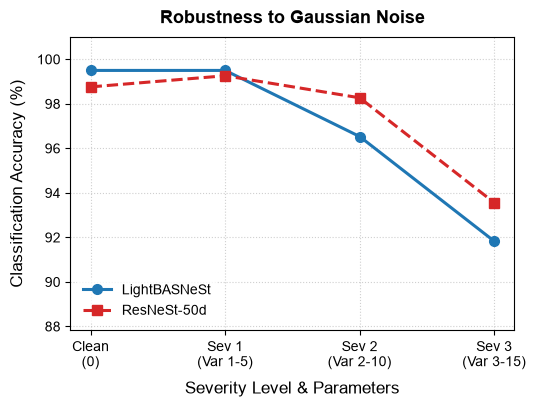

Saved: robustness_gaussian_blur.png


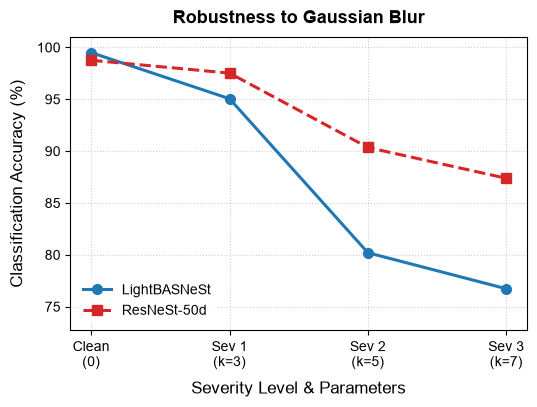

Saved: robustness_jpeg_compression.png


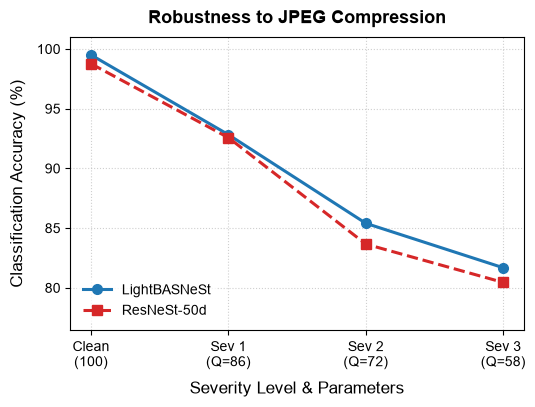

Saved: robustness_brightness.png


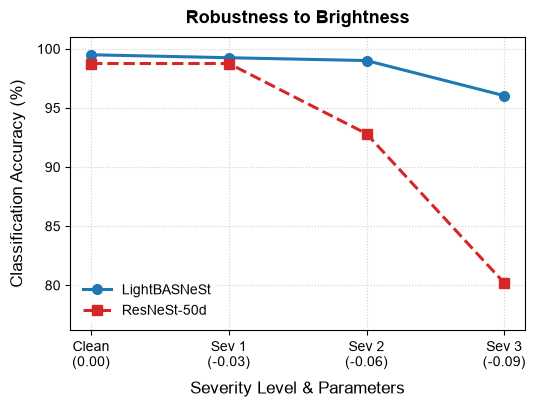

Saved: robustness_combined_2x2_grid.png


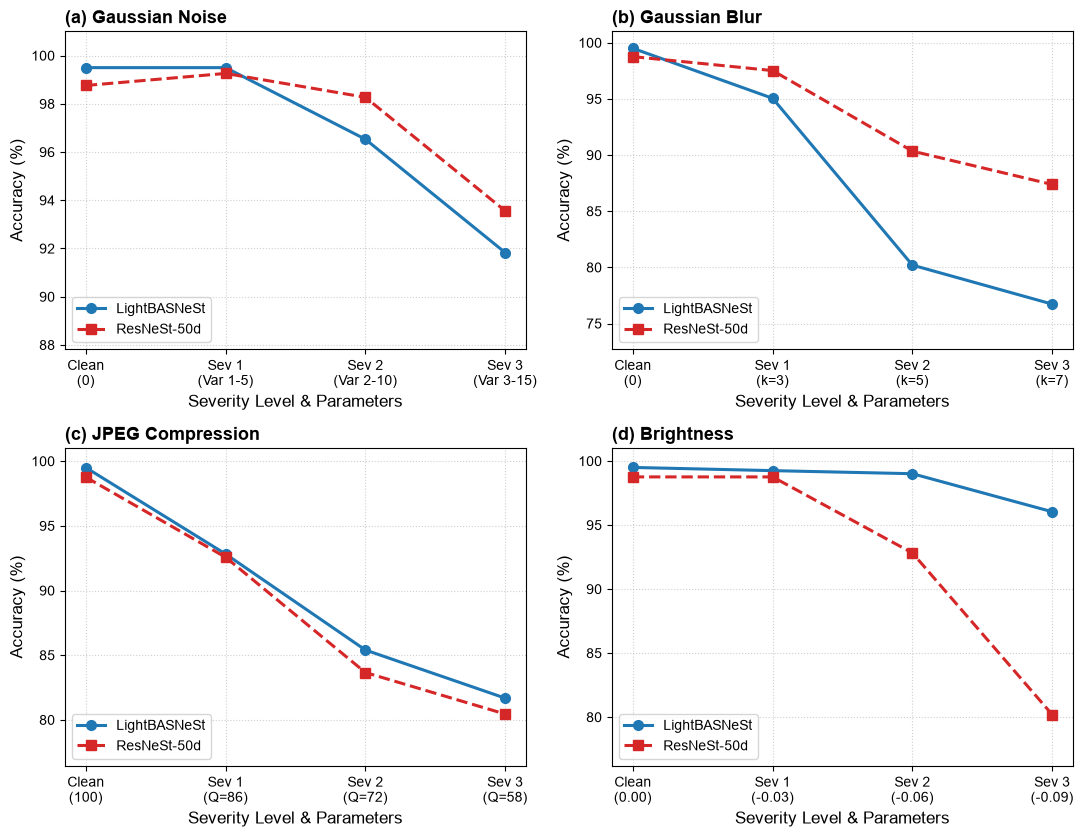

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Configure publication-quality aesthetic standards (IEEE / Elsevier suitable)
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'lines.linewidth': 2.2,
    'lines.markersize': 7,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

severities = [0, 1, 2, 3]  # 0 represents Clean baseline

# Benchmark evaluation data (4 Corruptions)
data = {
    "Gaussian Noise": {
        "x_ticks": ["Clean\n(0)", "Sev 1\n(Var 1-5)", "Sev 2\n(Var 2-10)", "Sev 3\n(Var 3-15)"],
        "proposed": [99.50, 99.50, 96.53, 91.83],
        "resnest50d": [98.76, 99.26, 98.27, 93.56]
    },
    "Gaussian Blur": {
        "x_ticks": ["Clean\n(0)", "Sev 1\n(k=3)", "Sev 2\n(k=5)", "Sev 3\n(k=7)"],
        "proposed": [99.50, 95.05, 80.20, 76.73],
        "resnest50d": [98.76, 97.52, 90.35, 87.38]
    },
    "JPEG Compression": {
        "x_ticks": ["Clean\n(100)", "Sev 1\n(Q=86)", "Sev 2\n(Q=72)", "Sev 3\n(Q=58)"],
        "proposed": [99.50, 92.82, 85.40, 81.68],
        "resnest50d": [98.76, 92.57, 83.66, 80.45]
    },
    "Brightness": {
        "x_ticks": ["Clean\n(0.00)", "Sev 1\n(-0.03)", "Sev 2\n(-0.06)", "Sev 3\n(-0.09)"],
        "proposed": [99.50, 99.25, 99.01, 96.04],
        "resnest50d": [98.76, 98.76, 92.82, 80.20]
    }
}

COLOR_PROPOSED = "#1f77b4"  # High-contrast blue
COLOR_RESNEST  = "#d62728"  # High-contrast red

def plot_individual_corruptions(save_files=True):
    """Generates and saves 4 standalone publication-ready comparison plots."""
    for corr_name, metrics in data.items():
        fig, ax = plt.subplots(figsize=(5.5, 4.2))
        
        ax.plot(severities, metrics["proposed"], marker='o', color=COLOR_PROPOSED, 
                label='LightBASNeSt', linestyle='-')
        ax.plot(severities, metrics["resnest50d"], marker='s', color=COLOR_RESNEST, 
                label='ResNeSt-50d', linestyle='--')
        
        ax.set_title(f"Robustness to {corr_name}", fontweight='bold', pad=10)
        ax.set_xlabel("Severity Level & Parameters", labelpad=8)
        ax.set_ylabel("Classification Accuracy (%)", labelpad=8)
        ax.set_xticks(severities)
        ax.set_xticklabels(metrics["x_ticks"])
        
        min_y = min(min(metrics["proposed"]), min(metrics["resnest50d"]))
        ax.set_ylim(max(0, min_y - 4), 101)
        
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(frameon=True, facecolor='white', edgecolor='none', loc='lower left')
        
        plt.tight_layout()
        if save_files:
            file_name = f"robustness_{corr_name.lower().replace(' ', '_')}.png"
            plt.savefig(file_name, format='png', dpi=300)
            print(f"Saved: {file_name}")
        plt.show()

def plot_combined_grid(save_file=True):
    """Generates a clean 2x2 grid composite figure for paper page optimization."""
    fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
    axes = axes.flatten()
    
    for idx, (corr_name, metrics) in enumerate(data.items()):
        ax = axes[idx]
        ax.plot(severities, metrics["proposed"], marker='o', color=COLOR_PROPOSED, 
                label='LightBASNeSt', linestyle='-')
        ax.plot(severities, metrics["resnest50d"], marker='s', color=COLOR_RESNEST, 
                label='ResNeSt-50d', linestyle='--')
        
        ax.set_title(f"({chr(97+idx)}) {corr_name}", fontweight='bold', loc='left')
        ax.set_xlabel("Severity Level & Parameters")
        ax.set_ylabel("Accuracy (%)")
        ax.set_xticks(severities)
        ax.set_xticklabels(metrics["x_ticks"])
        
        min_y = min(min(metrics["proposed"]), min(metrics["resnest50d"]))
        ax.set_ylim(max(0, min_y - 4), 101)
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(frameon=True, facecolor='white', loc='lower left')

    plt.tight_layout()
    if save_file:
        plt.savefig("robustness_combined_2x2_grid.png", format='png', dpi=300)
        print("Saved: robustness_combined_2x2_grid.png")
    plt.show()

if __name__ == "__main__":
    # Generate 4 individual figure files
    plot_individual_corruptions(save_files=True)
    
    # Generate a single 2x2 multi-panel figure (a, b, c, d)
    plot_combined_grid(save_file=True)